In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import utils
import storm_dates
import pre_processing
import constants
import matplotlib.dates as mdates
from IPython.display import display, HTML

display(HTML("<style>.container { width:100% !important; }</style>"))

/mnt/data/symbolic-regression-ldi/.venv/lib/python3.12/site-packages/spacepy/time.py:2448: UserWarning: Leapseconds may be out of date. Use spacepy.toolbox.update(leapsecs=True)
  _read_leaps()


In [3]:
relevant_columns = ['Bz', 'Vp', 'Np', 'T', 'Bmag']

In [ ]:
ace_columns = ['Bmag', 'Bx', 'By', 'Bz','Vp', 'Np', 'T']

dst_kyoto = utils.read_iaga_file('./data/dst-kyoto.txt', columns = ["DATE", "TIME", "DOY", "DST"])
dst_kyoto = dst_kyoto[~dst_kyoto.index.duplicated(keep='first')]

ace_imf = utils.read_data('./data/all_timeline', pattern_to_read=['csv', 'ace_imf_1h_'], print_info = True, return_separated = False)
ace_imf.columns = ['Bmag', 'Bx', 'By', 'Bz']
ace_imf = ace_imf[~ace_imf.index.duplicated(keep='first')]

ace_imf_provisional = utils.read_data('./data/all_timeline', pattern_to_read=['csv', 'ace_imf_provisional_1h_'], print_info = True, return_separated = False)
ace_imf_provisional = pre_processing.preprocess_ace_imf_provisional(ace_imf_provisional, resample=False)
ace_imf_provisional.columns = ['Bmag', 'Bx', 'By', 'Bz']
ace_imf_provisional = ace_imf_provisional[~ace_imf_provisional.index.duplicated(keep='first')]

ace_imf = ace_imf.combine_first(ace_imf_provisional)

ace_swepam = utils.read_data('./data/all_timeline', pattern_to_read=['csv', 'ace_swepam_1h_'], print_info = True, return_separated = False)                          
ace_swepam.columns = ['Vx', 'Vy', 'Vz', 'Vp', 'Np', 'T']
ace_swepam = ace_swepam.loc[:, ('Vp', 'Np', 'T')]
ace_swepam = ace_swepam[~ace_swepam.index.duplicated(keep='first')]
    
ace_swepam_provisional = utils.read_data('./data/all_timeline', pattern_to_read=['csv', 'ace_swepam_provisional_1h_'], print_info = True, return_separated = False)                          
ace_swepam_provisional = pre_processing.preprocess_ace_swepam_provisional(ace_swepam_provisional, resample=False)
display(ace_swepam_provisional.head())
ace_swepam_provisional.columns = ['Np', 'Vp', 'T']
ace_swepam_provisional = ace_swepam_provisional[~ace_swepam_provisional.index.duplicated(keep='first')]

ace_swepam = ace_swepam.combine_first(ace_swepam_provisional)

ace_data = ace_imf.join(ace_swepam)

all_data = ace_data.join(dst_kyoto['DST'])

all_data["E_Field"] = -all_data["Vp"] * all_data["Bz"] * 1e-3  # Convective electric field in mV/m
all_data["P_dyn"] = 1.6726e-6 * all_data["Np"] * (all_data["Vp"] ** 2)  # Dynamic pressure

Reading from file ./data/all_timeline/ace_imf_1h_1998.csv
Reading from file ./data/all_timeline/ace_imf_1h_1999.csv
Reading from file ./data/all_timeline/ace_imf_1h_2000.csv
Reading from file ./data/all_timeline/ace_imf_1h_2001.csv
Reading from file ./data/all_timeline/ace_imf_1h_2002.csv
Reading from file ./data/all_timeline/ace_imf_1h_2003.csv
Reading from file ./data/all_timeline/ace_imf_1h_2004.csv
Reading from file ./data/all_timeline/ace_imf_1h_2005.csv
Reading from file ./data/all_timeline/ace_imf_1h_2006.csv
Reading from file ./data/all_timeline/ace_imf_1h_2007.csv
Reading from file ./data/all_timeline/ace_imf_1h_2008.csv
Reading from file ./data/all_timeline/ace_imf_1h_2009.csv
Reading from file ./data/all_timeline/ace_imf_1h_2010.csv
Reading from file ./data/all_timeline/ace_imf_1h_2011.csv
Reading from file ./data/all_timeline/ace_imf_1h_2012.csv
Reading from file ./data/all_timeline/ace_imf_1h_2013.csv
Reading from file ./data/all_timeline/ace_imf_1h_2014.csv
Reading from f

,Proton_density,Proton_speed,Proton_temp
datetime,,,
2017-07-01 00:00:00,9.5748,352.84,27952.0
2017-07-01 01:00:00,9.3308,355.90,31679.0
2017-07-01 02:00:00,9.3422,357.36,32519.0
2017-07-01 03:00:00,9.1828,359.25,22173.0
2017-07-01 04:00:00,9.6689,350.39,26966.0


In [5]:
all_data

,Bmag,Bx,By,Bz,Np,T,Vp,DST,E_Field,P_dyn
datetime,,,,,,,,,,
1998-01-01 00:00:00,4.819,-2.718,-1.111,3.221,NaN,NaN,NaN,-9.0,NaN,NaN
1998-01-01 01:00:00,5.079,-4.237,-0.495,-1.869,NaN,NaN,NaN,-8.0,NaN,NaN
1998-01-01 02:00:00,5.432,-4.598,-0.380,-0.692,NaN,NaN,NaN,-9.0,NaN,NaN
1998-01-01 03:00:00,5.433,-4.235,0.924,-0.137,NaN,NaN,NaN,-9.0,NaN,NaN
1998-01-01 04:00:00,5.161,-3.440,2.427,-0.707,NaN,NaN,NaN,-13.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2024-12-31 20:00:00,20.607,-8.083,18.189,-4.451,14.4754,166420.0,445.99,-6.0,1.985101,4.815850
2024-12-31 21:00:00,19.192,-7.955,16.039,-5.805,13.2279,131144.0,444.29,-18.0,2.579103,4.367331
2024-12-31 22:00:00,15.381,-6.880,13.435,-1.869,14.6221,89523.0,439.39,-23.0,0.821220,4.721741


In [6]:
MU0 = 4 * np.pi * 1e-7          # vacuum permeability [H/m]
MP = 1.6726e-27                 # proton mass [kg]
KB = 1.380649e-23               # Boltzmann constant [J/K]

def compute_derived_features(dfx: pd.DataFrame, lag_hours: int = 1) -> pd.DataFrame:
    df = dfx.copy()
    # Convert to SI-like for intermediate computations
    B = df["B"].values * 1e-9          # nT -> T
    Bx = df["Bx"].values * 1e-9
    By = df["By"].values * 1e-9
    Bz = df["Bz"].values * 1e-9
    V = df["V"].values * 1e3           # km/s -> m/s
    n = df["n"].values * 1e6           # cm^-3 -> m^-3
    T = df["T"].values
    Dst = df["Dst"].values

    # --- Core magnetic & electric field derived features ---
    df["B_T"] = np.sqrt(df["By"]**2 + df["Bz"]**2)
    df["clock_angle"] = np.degrees(np.arctan2(df["By"], df["Bz"]))
    df["sin_th2"] = np.sin(np.radians(df["clock_angle"]) / 2)
    df["cos_th2"] = np.cos(np.radians(df["clock_angle"]) / 2)

    # Dawn-dusk electric field (mV/m)
    df["Ey"] = -df["V"] * df["Bz"] * 1e-3
    # Rectified southward VB term
    df["VBs"] = df["V"] * np.maximum(0, -df["Bz"])
    df["VBs_thresh"] = np.maximum(df["VBs"] - 0.5, 0)  # Ec ~0.5 mV/m

    # --- Pressures ---
    df["Pdyn"] = 1.6726e-6 * df["n"] * df["V"]**2                # nPa
    df["sqrt_Pdyn"] = np.sqrt(df["Pdyn"])
    df["P_B"] = (df["B"]**2) / (2 * MU0) * 1e9                   # nPa
    df["P_th"] = n * KB * T * 1e9                                # nPa
    df["P_total"] = df["Pdyn"] + df["P_B"] + df["P_th"]

    # Plasma beta
    df["beta"] = (2 * MU0 * n * KB * T) / (B**2 + 1e-30)

    # --- Alfven parameters ---
    V_A = B / np.sqrt(MU0 * MP * n)
    df["M_A"] = V / (V_A + 1e-30)

    # --- Coupling functions ---
    df["epsilon"] = df["V"] * (df["B_T"]**2) * (df["sin_th2"]**4)
    df["dPhi_dt"] = (df["V"]**(4/3)) * (df["B_T"]**(2/3)) * (df["sin_th2"]**(8/3))

    # --- Derivatives (finite differences) ---
    for col in ["Bz", "V", "n"]:
        df[f"d{col}_dt"] = df[col].diff()

    # --- Lags (Dst persistence term) ---
    df["Dst_prev"] = df["Dst"].shift(lag_hours)
    df["dDst_dt_prev"] = df["Dst"].diff().shift(1)

    # --- Rolling-window stats (3h and 6h means/max) ---
    for var in ["Ey", "Bz"]:
        df[f"{var}_mean_3h"] = df[var].rolling(3, min_periods=1).mean()
        df[f"{var}_max_6h"] = df[var].rolling(6, min_periods=1).max()

    # --- Interaction terms (nonlinear combos) ---
    df["Ey_sqrtPdyn"] = df["Ey"] * df["sqrt_Pdyn"]
    df["V2"] = df["V"]**2
    df["VBs_sqrtPdyn"] = df["VBs"] * df["sqrt_Pdyn"]
    df["Bz_over_B"] = df["Bz"] / (df["B"] + 1e-9)
    df["Pdyn_over_PB"] = df["Pdyn"] / (df["P_B"] + 1e-9)

    # Drop first few NaNs from diffs/lags
    df = df.dropna().reset_index(drop=True)
    return df

In [7]:
def plot_storm(dst_kyoto, storm, col, sd, ed, storm_index):
    
    fig, ax = plt.subplots(1, 1, figsize = (15, 5))
    l1, = ax.plot(dst_kyoto[sd:ed].index, dst_kyoto[sd:ed]['DST'].values, label = 'Dst (1 hour data)', color = 'red')

    
    lines = [l1]

    if col is not None:
        
        if storm[col].isna().sum() == len(storm[col]):
            l7 = ax.fill_between(
                all_data[sd:ed].index,
                all_data[sd:ed][col].min(),
                all_data[sd:ed][col].max(),
                #where = storm[col].isna(),
                color = 'magenta',
                alpha = 0.1,
                hatch = 'X',
                label = f'Missing {col}'
            )
            
            lines.extend([l7])
            
        else:
    
            twin = ax.twinx()
            l5, = twin.plot(storm.index, storm[col], label = f'{col}', color = 'orange', linestyle='--')
            twin.set_ylabel(f'{col}')        

            l6 = twin.fill_between(
                storm.index,
                storm[col].min(),
                storm[col].max(),
                where = storm[col].isna(),
                color = 'magenta',
                alpha = 0.1,
                hatch = 'X',
                label = f'Missing {col}'
            )

            lines.extend([l5, l6])

            twin.set_ylim(storm[col].min(), storm[col].max())

    labels = [l.get_label() for l in lines]
    
    ax.grid(True)
    ax.set_ylabel('Disturbance (nT)')
    leg = ax.legend(
        lines,
        labels,
        bbox_to_anchor=(0.5, 1.25),
        loc="upper center",
        ncol=3,
        fancybox=True,
        prop={"size": 12},
        edgecolor="black",
        facecolor="none",
    )

    ax.set_xlim(sd, ed)        
    ax.set_xlabel('Date')
    ax.set_title(f'{col} with [{storm[col].isna().sum()}/{len(storm)}] ({storm[col].isna().sum() / len(storm[col]) * 100:.3f}%) missing values for storm {storm_index} from {sd.strftime("%Y-%B-%d")} to {ed.strftime("%Y-%B-%d")}')

    plt.show();
    

There are ACE missing values in Train storm 1 from 1998 March 08 to 1998 March 17
T missing 21 values (9.677%)


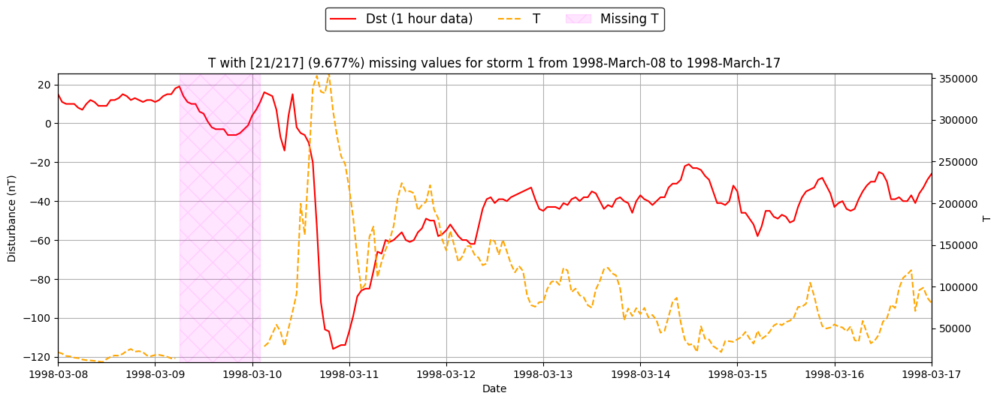

There are ACE missing values in Train storm 2 from 1998 May 02 to 1998 May 11
T missing 14 values (6.452%)


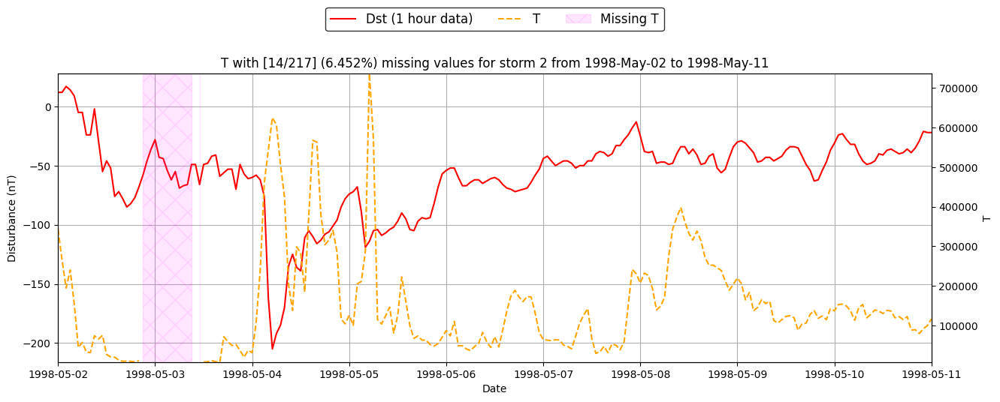

There are ACE missing values in Train storm 3 from 1998 June 24 to 1998 July 02
T missing 14 values (7.254%)


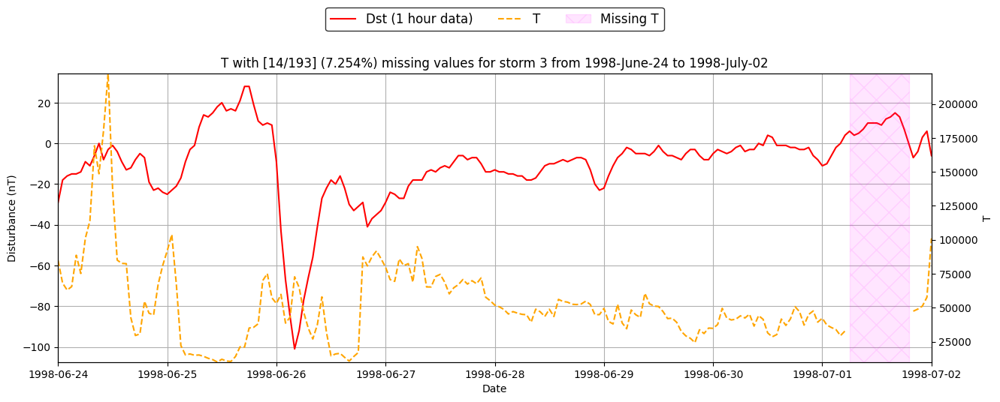

Train storm 4 from 1998 August 04 to 1998 August 13 has no missing values
Train storm 5 from 1998 August 25 to 1998 September 02 has no missing values
Train storm 6 from 1998 September 23 to 1998 October 01 has no missing values
There are ACE missing values in Train storm 7 from 1998 October 17 to 1998 October 25
T missing 2 values (1.036%)


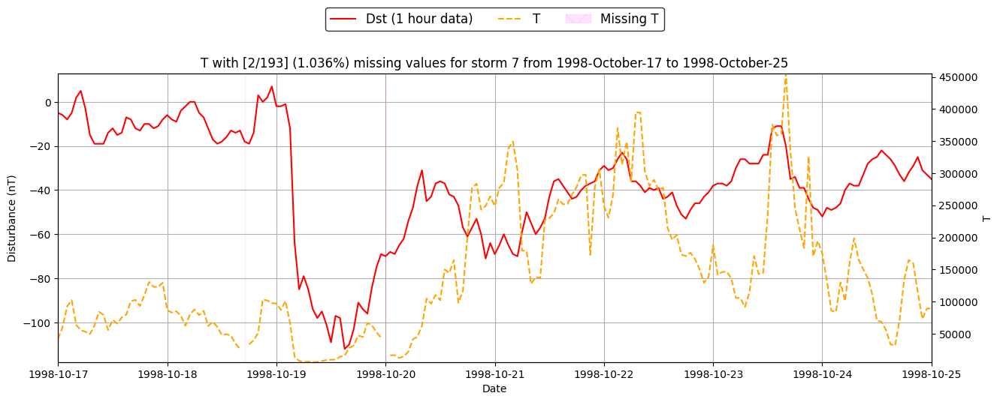

There are ACE missing values in Train storm 8 from 1999 January 11 to 1999 January 20
T missing 1 values (0.461%)


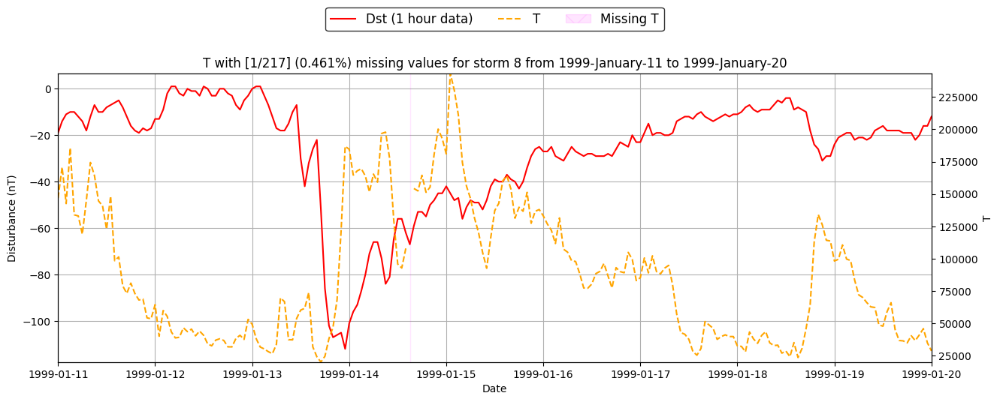

Train storm 9 from 1999 February 16 to 1999 February 25 has no missing values
There are ACE missing values in Train storm 10 from 1999 February 27 to 1999 March 07
T missing 4 values (2.073%)


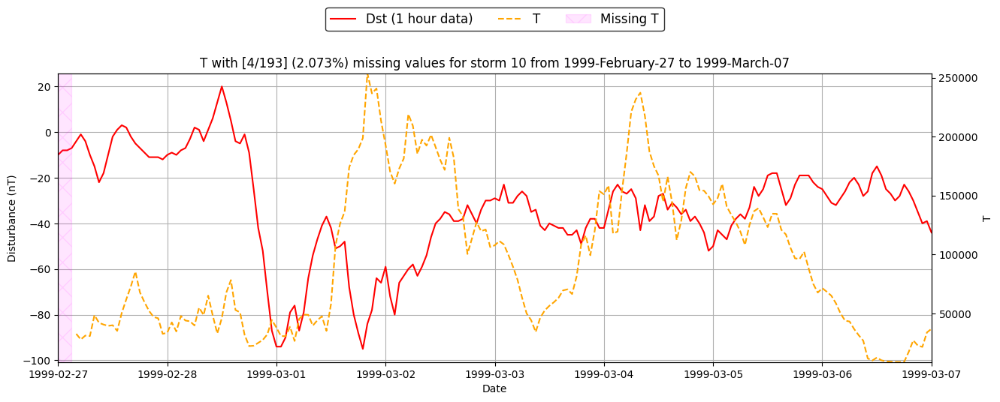

Train storm 11 from 1999 April 15 to 1999 April 23 has no missing values
Train storm 12 from 1999 September 20 to 1999 September 29 has no missing values
There are ACE missing values in Train storm 13 from 2000 February 10 to 2000 February 18
T missing 30 values (15.544%)


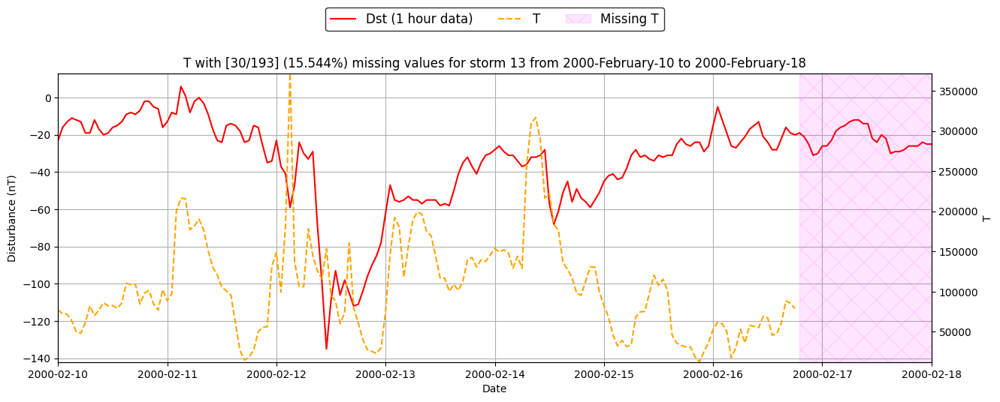

Train storm 14 from 2000 May 15 to 2000 May 30 has no missing values
Train storm 15 from 2000 June 06 to 2000 June 14 has no missing values
There are ACE missing values in Train storm 16 from 2000 July 13 to 2000 July 26
T missing 37 values (11.821%)


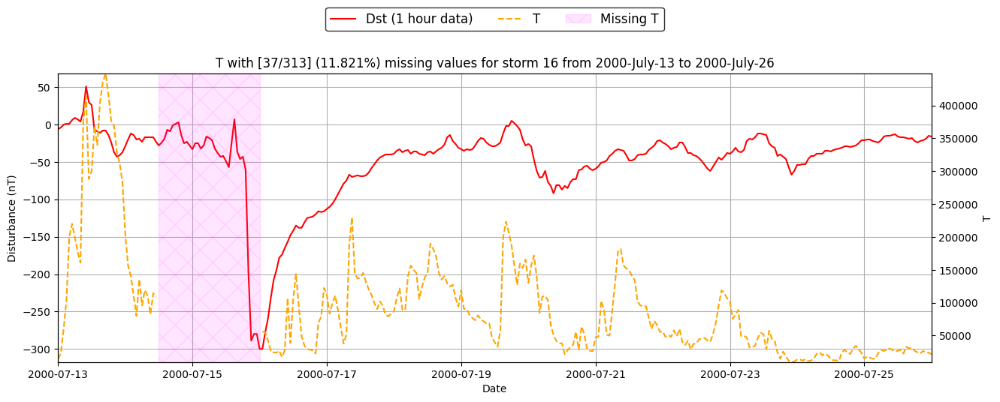

There are ACE missing values in Train storm 17 from 2000 August 09 to 2000 August 18
T missing 31 values (14.286%)


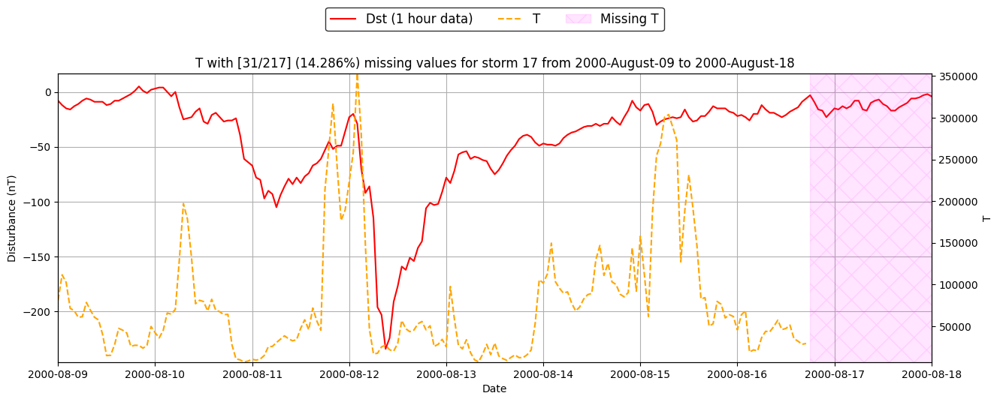

There are ACE missing values in Train storm 18 from 2000 September 15 to 2000 September 24
T missing 4 values (1.843%)


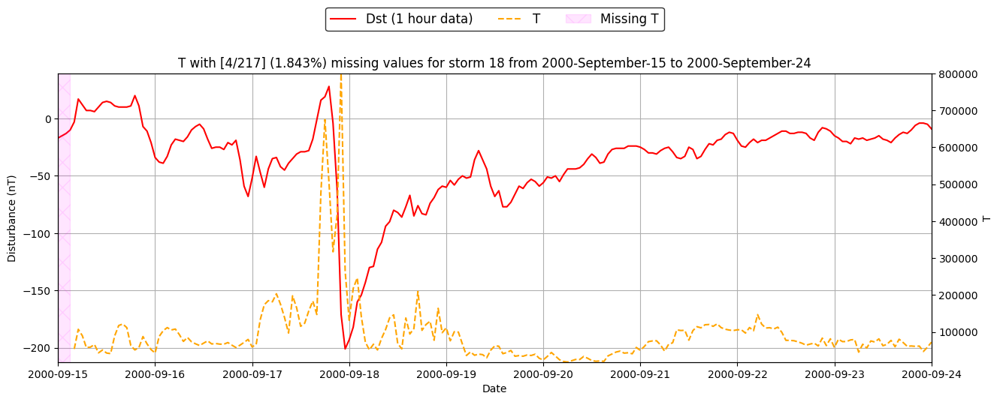

There are ACE missing values in Train storm 19 from 2000 October 02 to 2000 October 20
T missing 115 values (26.559%)


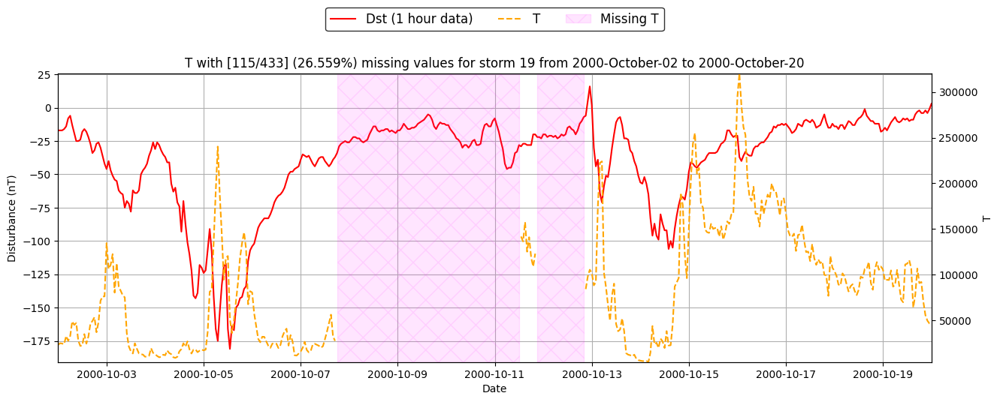

There are ACE missing values in Train storm 20 from 2000 October 27 to 2000 November 16
T missing 61 values (12.682%)


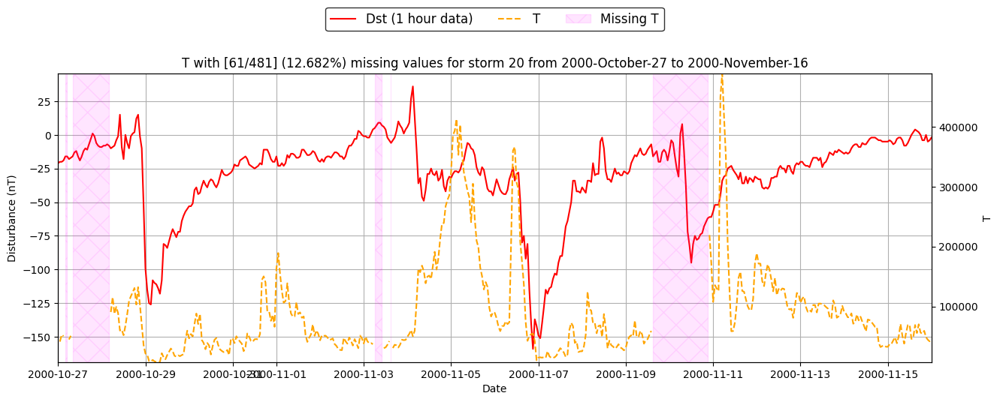

Train storm 21 from 2000 November 27 to 2000 December 05 has no missing values
There are ACE missing values in Train storm 22 from 2001 March 17 to 2001 March 26
T missing 90 values (41.475%)


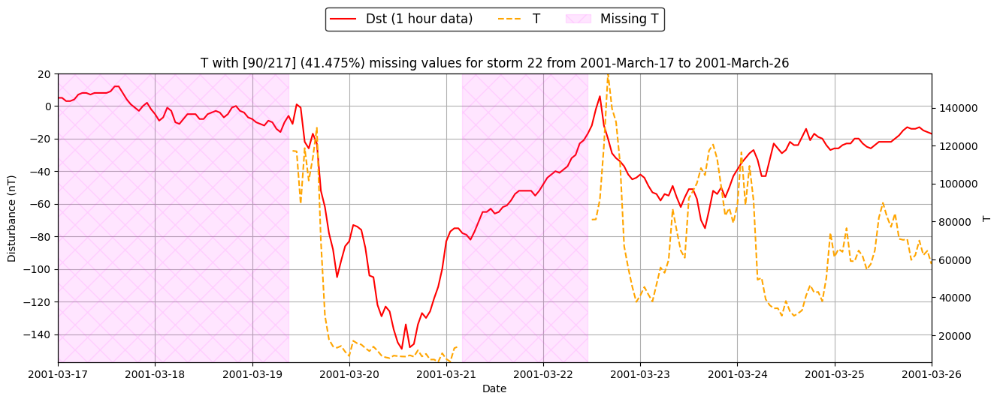

There are ACE missing values in Train storm 23 from 2001 April 09 to 2001 April 28
T missing 16 values (3.501%)


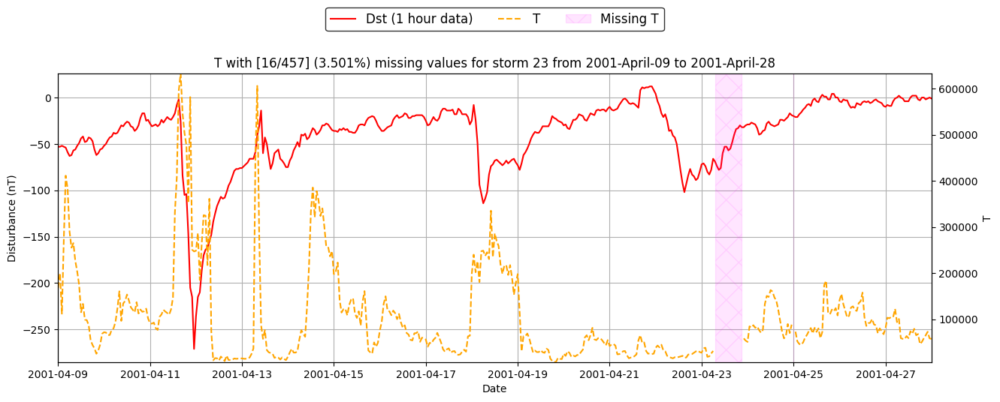

Train storm 24 from 2001 August 15 to 2001 August 23 has no missing values
There are ACE missing values in Train storm 25 from 2001 September 24 to 2001 October 10
T missing 38 values (9.870%)


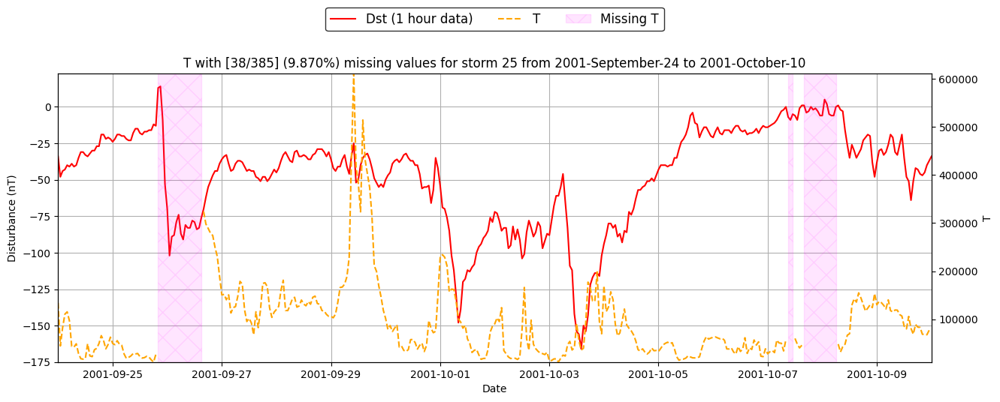

There are ACE missing values in Train storm 26 from 2001 October 19 to 2001 November 13
T missing 108 values (17.970%)


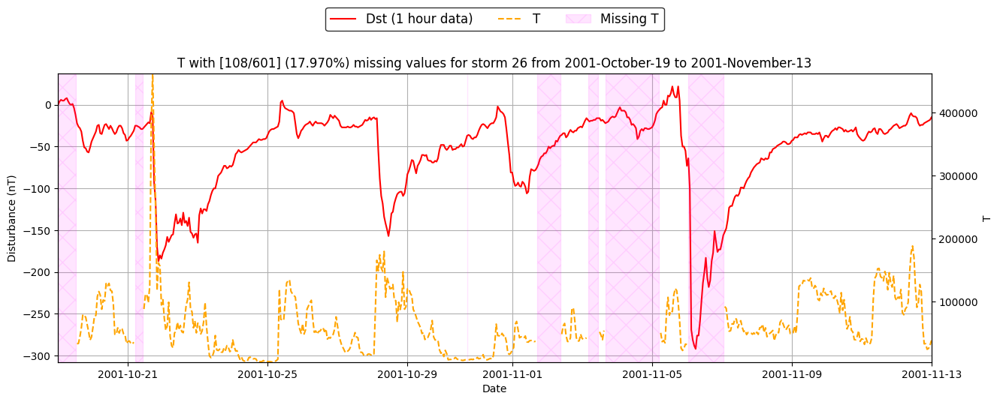

There are ACE missing values in Train storm 27 from 2001 November 22 to 2001 December 01
T missing 12 values (5.530%)


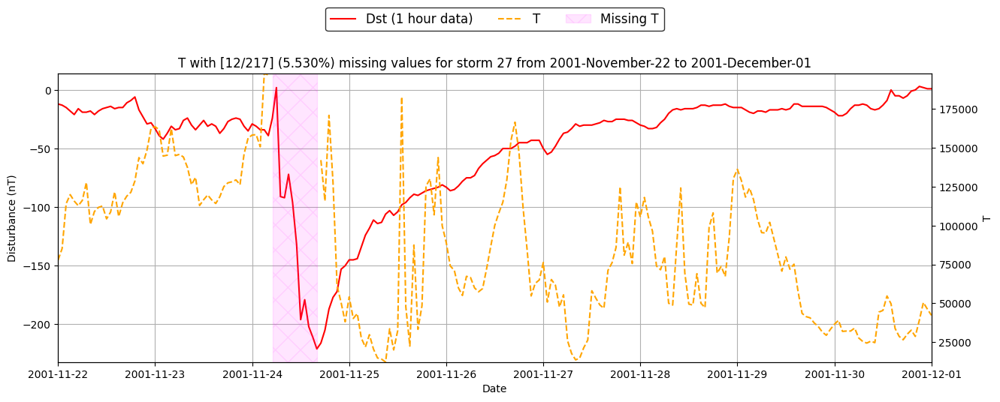

There are ACE missing values in Train storm 28 from 2002 March 22 to 2002 March 30
T missing 23 values (11.917%)


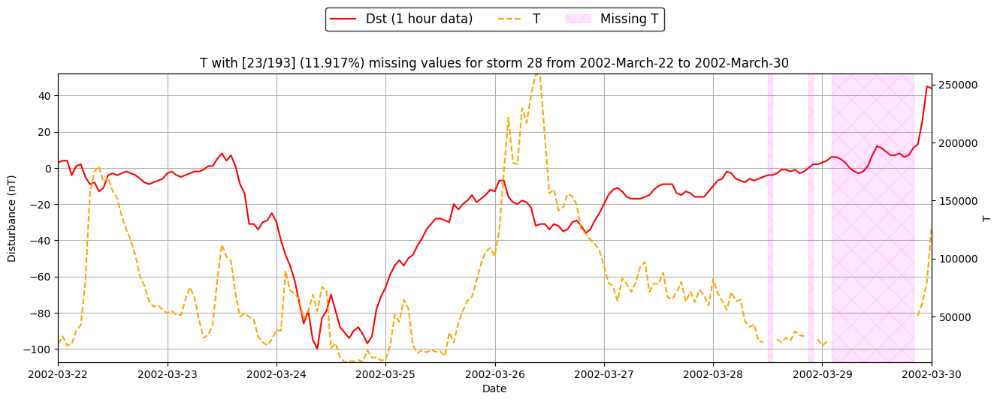

There are ACE missing values in Train storm 29 from 2002 April 15 to 2002 April 26
T missing 16 values (6.038%)


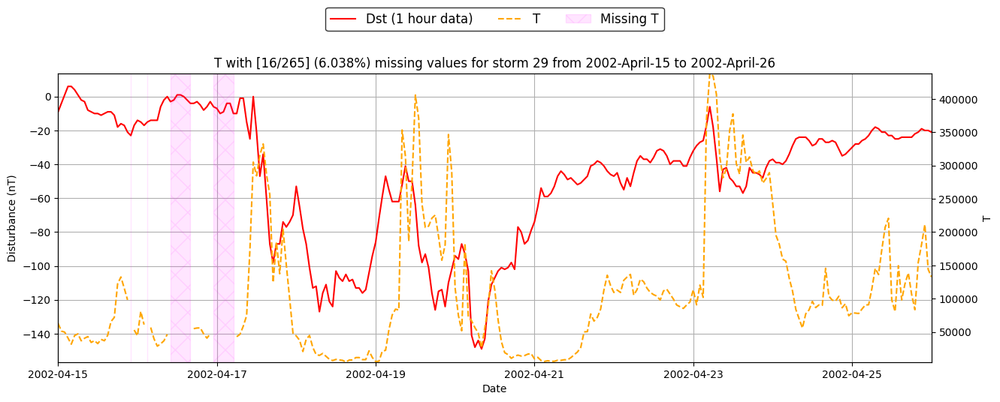

Train storm 30 from 2002 May 21 to 2002 May 29 has no missing values
There are ACE missing values in Train storm 31 from 2002 July 31 to 2002 August 08
T missing 18 values (9.326%)


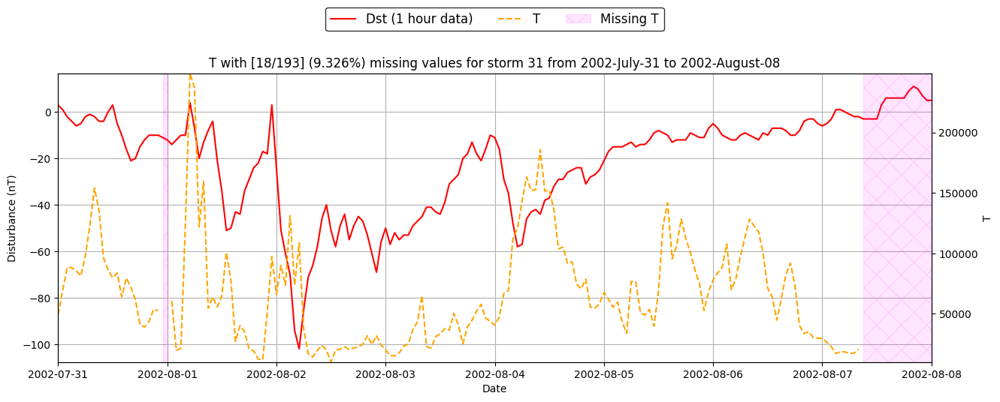

There are ACE missing values in Train storm 32 from 2002 September 02 to 2002 September 17
T missing 44 values (12.188%)


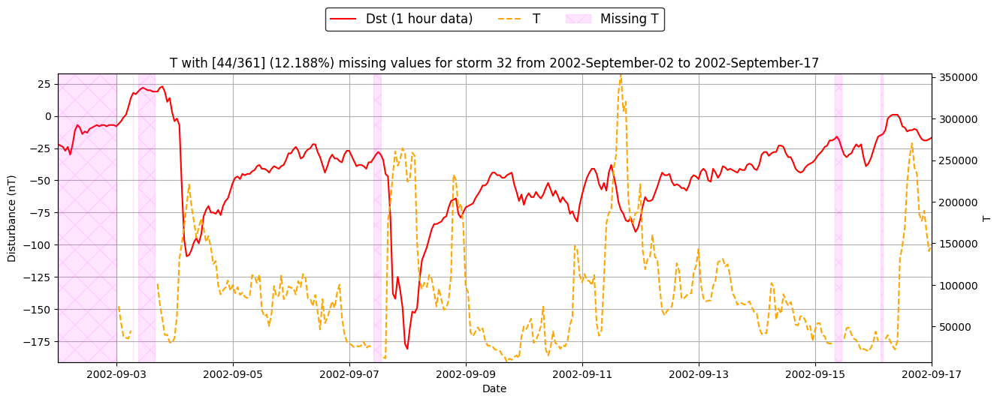

There are ACE missing values in Train storm 33 from 2002 September 29 to 2002 October 20
T missing 71 values (14.059%)


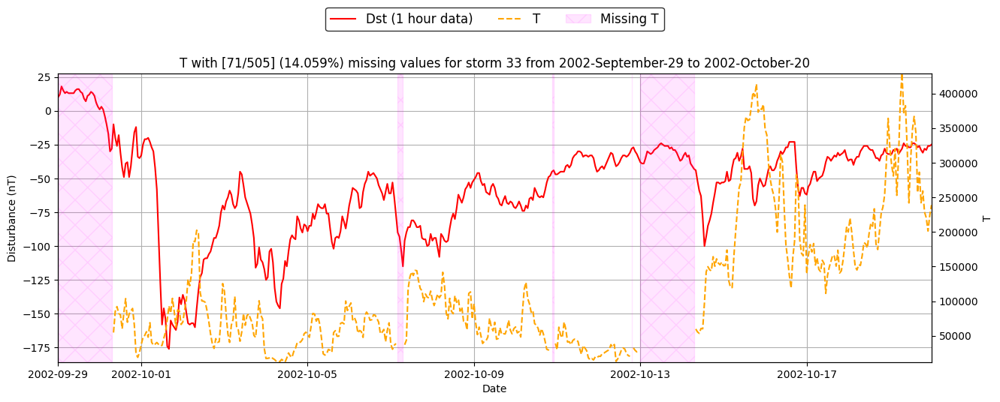

Train storm 34 from 2002 October 22 to 2002 October 31 has no missing values
Train storm 35 from 2002 November 19 to 2002 November 27 has no missing values
Train storm 36 from 2003 May 27 to 2003 June 08 has no missing values
There are ACE missing values in Train storm 37 from 2003 July 10 to 2003 July 22
T missing 3 values (1.038%)


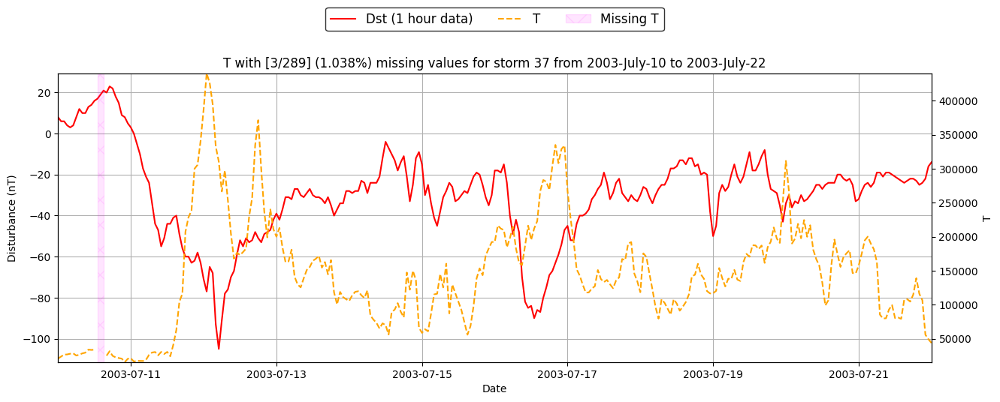

Train storm 38 from 2003 August 16 to 2003 August 25 has no missing values
There are ACE missing values in Train storm 39 from 2003 October 27 to 2003 November 06
Np missing 82 values (34.025%)


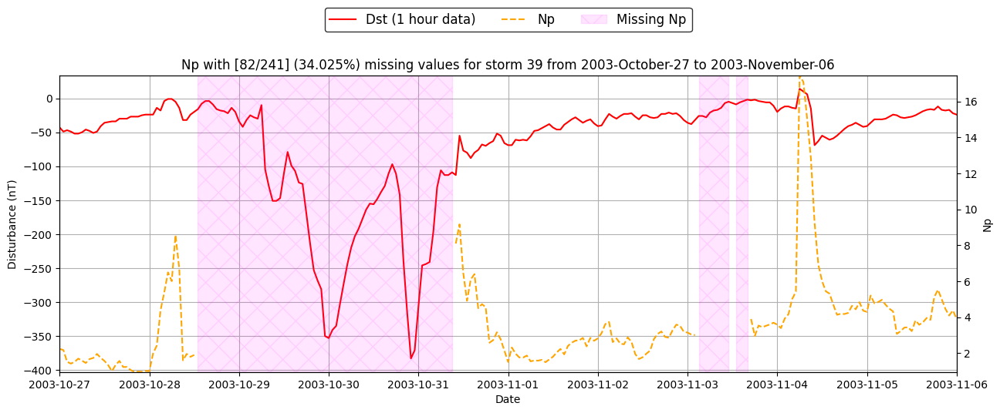

There are ACE missing values in Train storm 40 from 2003 November 18 to 2003 November 27
T missing 1 values (0.461%)


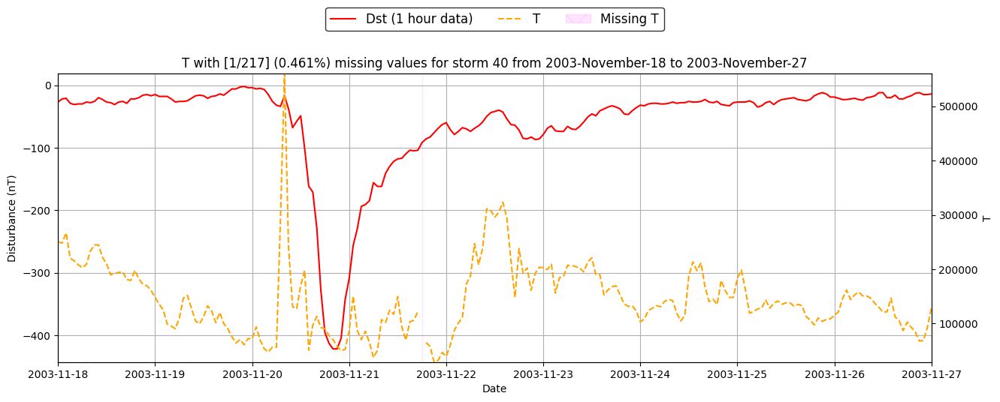

Train storm 41 from 2004 January 20 to 2004 January 28 has no missing values
Train storm 42 from 2004 February 09 to 2004 February 17 has no missing values
Train storm 43 from 2004 April 01 to 2004 April 10 has no missing values
There are ACE missing values in Train storm 44 from 2004 July 21 to 2004 August 02
Np missing 7 values (2.422%)


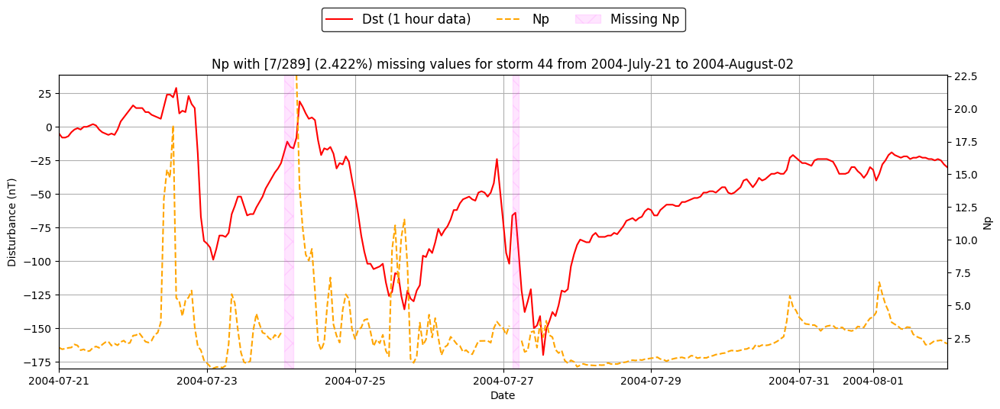

There are ACE missing values in Train storm 45 from 2004 August 28 to 2004 September 06
Np missing 50 values (23.041%)


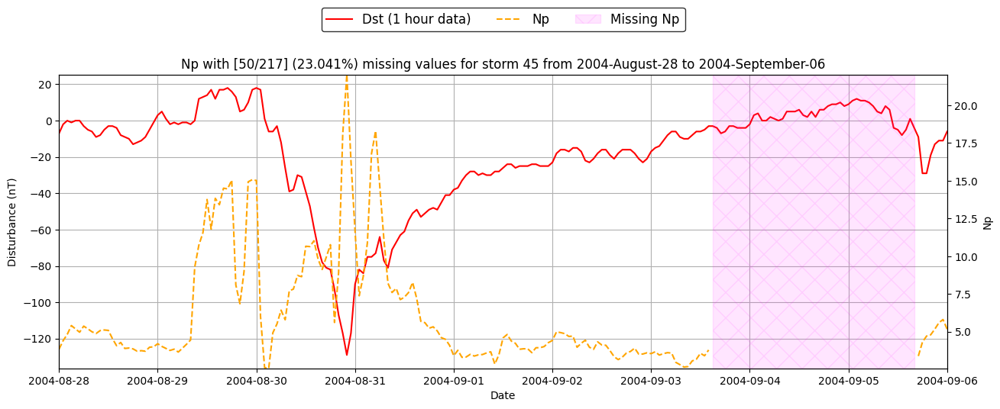

There are ACE missing values in Train storm 46 from 2004 November 06 to 2004 November 18
T missing 10 values (3.460%)


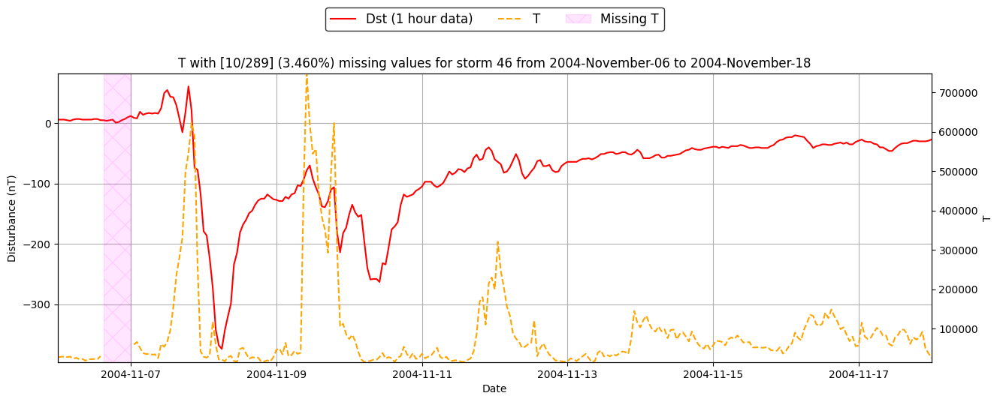

Train storm 48 from 2005 May 06 to 2005 May 22 has no missing values
There are ACE missing values in Train storm 49 from 2005 May 28 to 2005 June 05
T missing 6 values (3.109%)


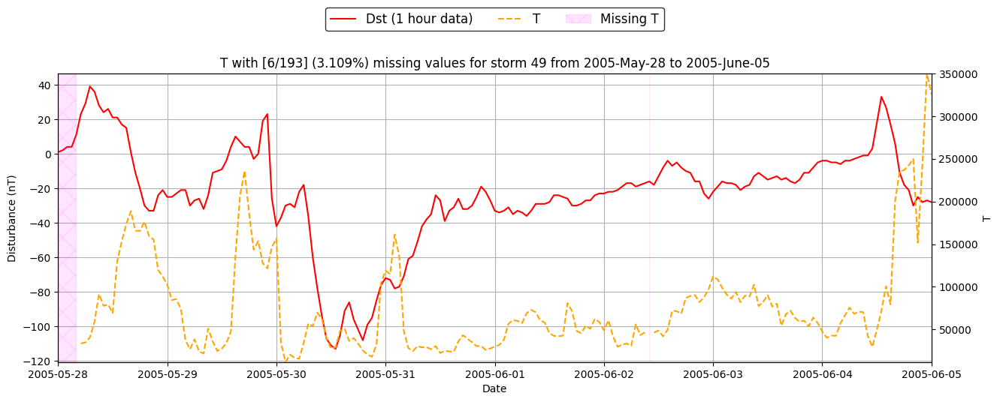

There are ACE missing values in Train storm 50 from 2005 June 10 to 2005 June 19
Np missing 54 values (24.885%)


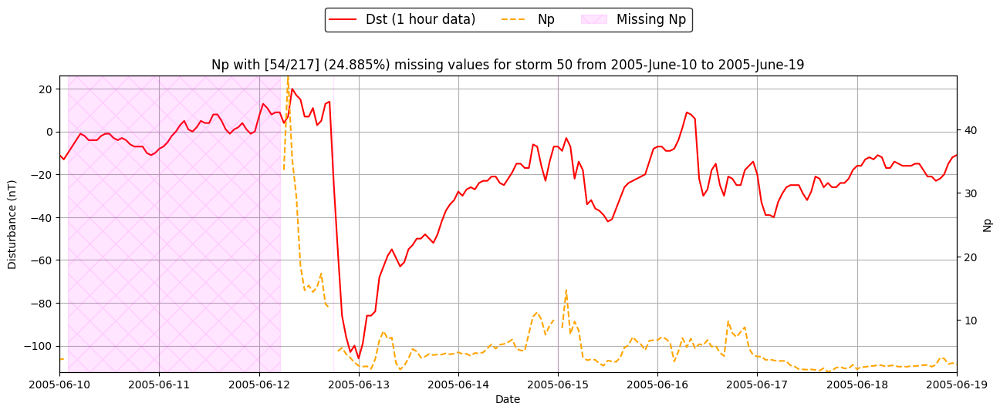

There are ACE missing values in Train storm 51 from 2005 August 22 to 2005 September 06
Np missing 22 values (6.094%)


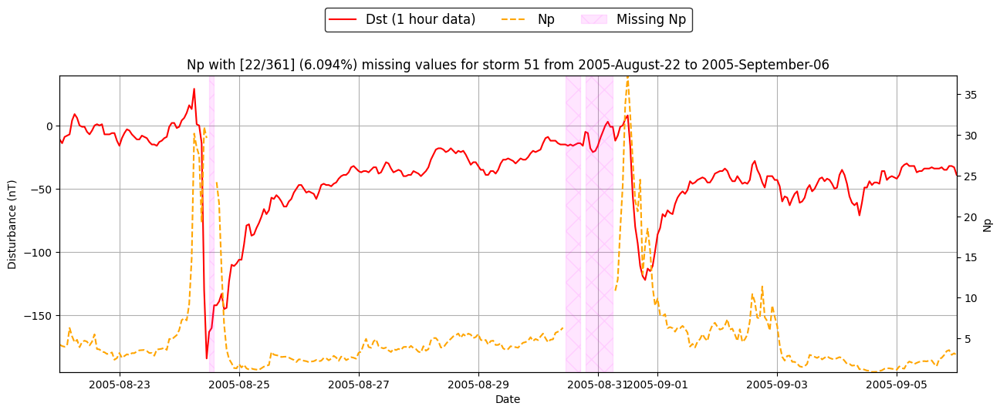

There are ACE missing values in Train storm 52 from 2006 April 12 to 2006 April 20
Np missing 5 values (2.591%)


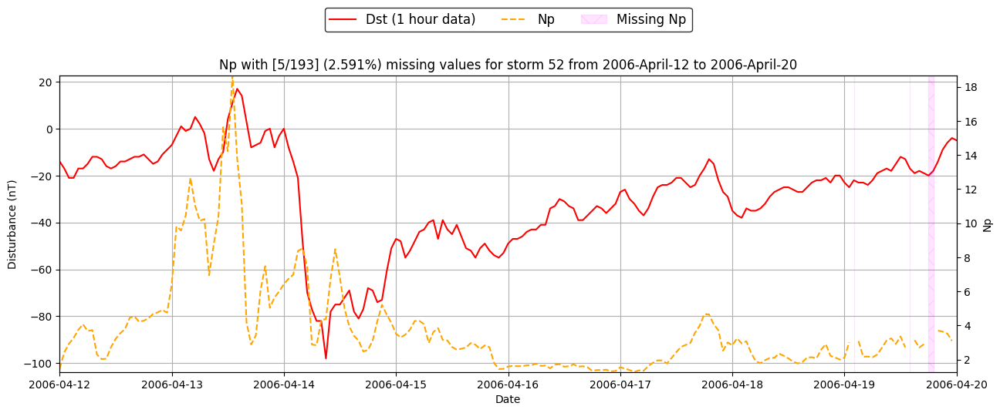

There are ACE missing values in Train storm 53 from 2006 December 13 to 2006 December 21
T missing 16 values (8.290%)


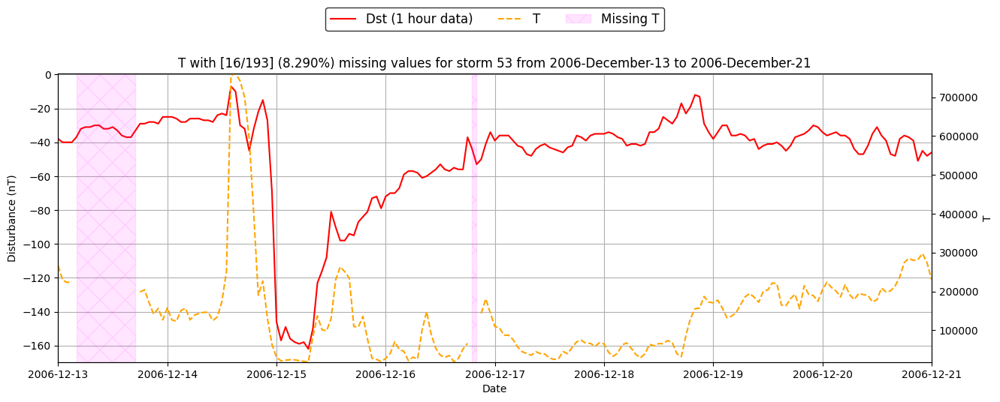

There are ACE missing values in Train storm 54 from 2011 August 04 to 2011 August 12
Np missing 139 values (72.021%)


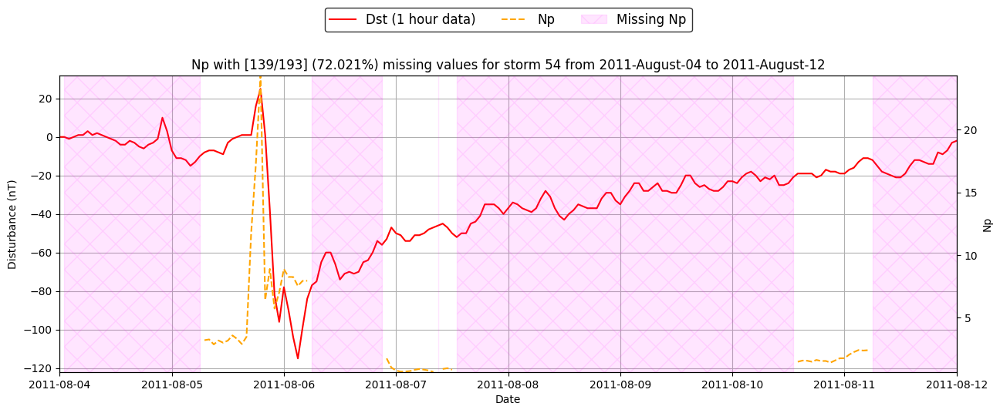

There are ACE missing values in Train storm 55 from 2011 September 24 to 2011 October 03
Np missing 195 values (89.862%)


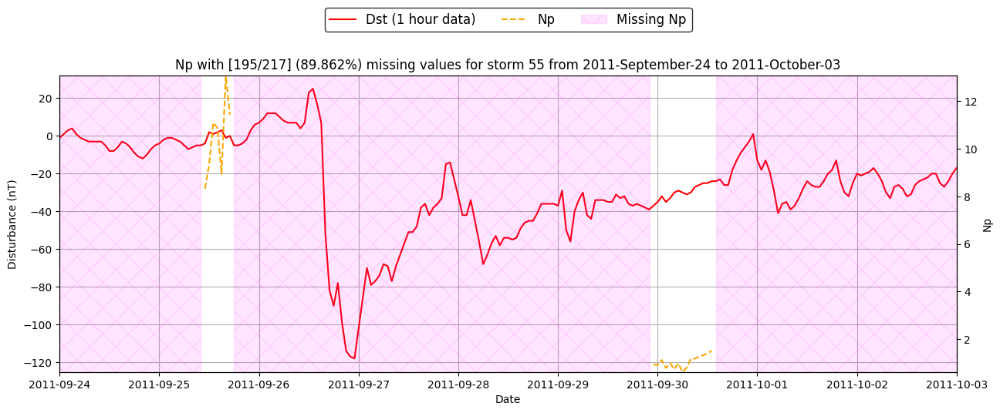

There are ACE missing values in Train storm 56 from 2012 March 07 to 2012 March 15
Np missing 124 values (64.249%)


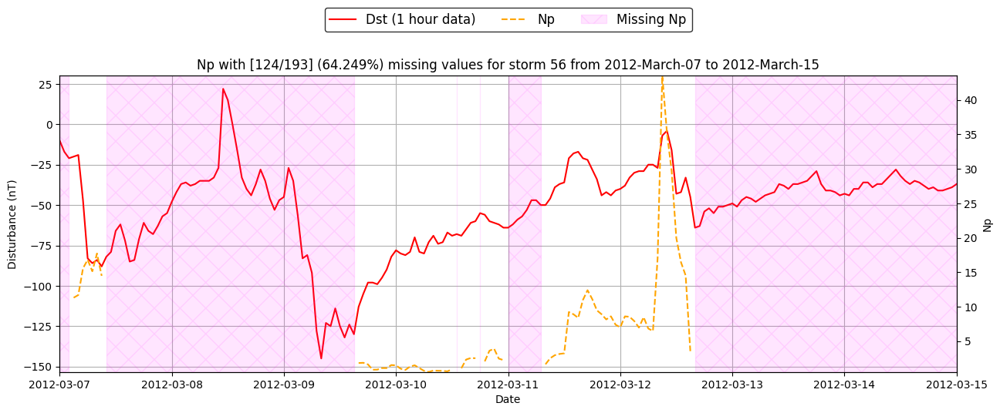

There are ACE missing values in Train storm 57 from 2012 April 21 to 2012 April 30
Np missing 217 values (100.000%)


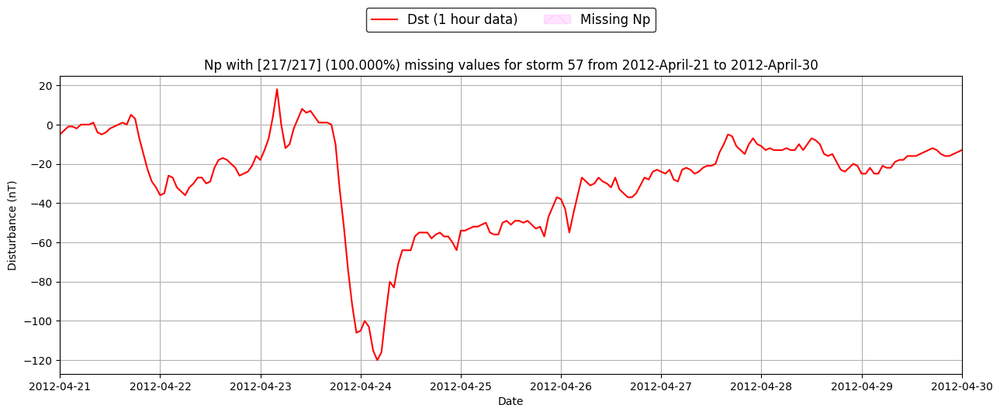

There are ACE missing values in Train storm 58 from 2012 July 13 to 2012 July 22
Np missing 85 values (39.171%)


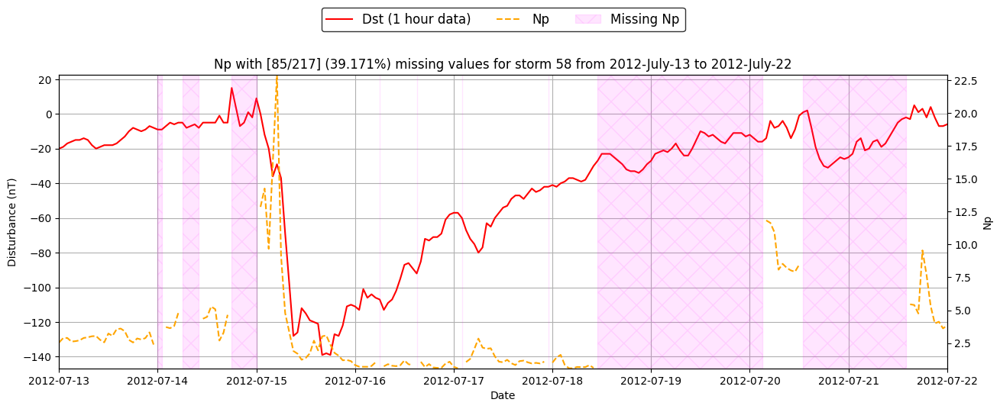

There are ACE missing values in Train storm 59 from 2012 November 12 to 2012 November 20
Np missing 86 values (44.560%)


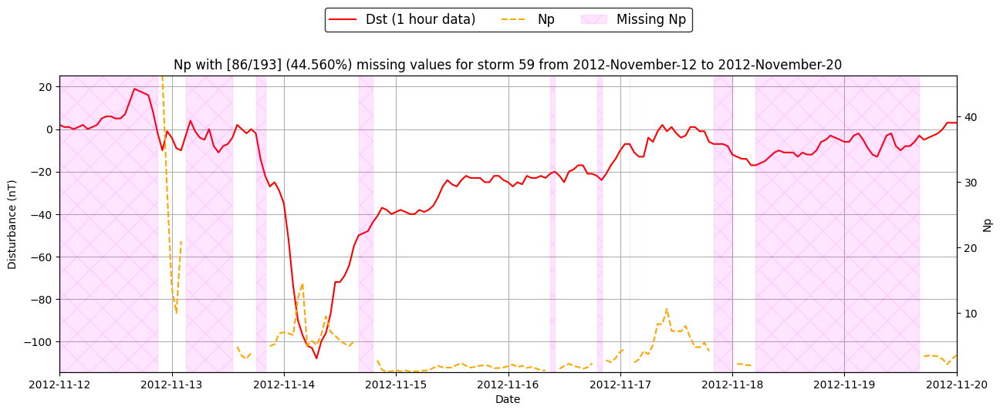

There are ACE missing values in Train storm 60 from 2013 May 30 to 2013 June 07
Np missing 4 values (2.073%)


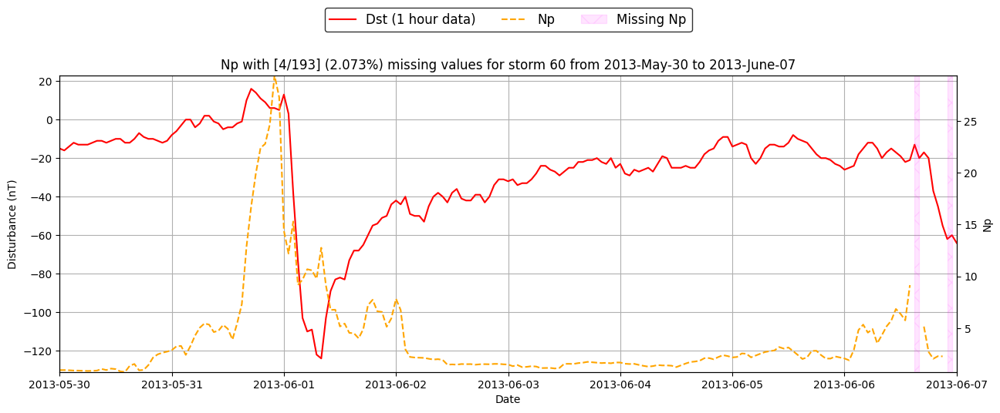

There are ACE missing values in Train storm 61 from 2015 January 05 to 2015 January 13
Np missing 93 values (48.187%)


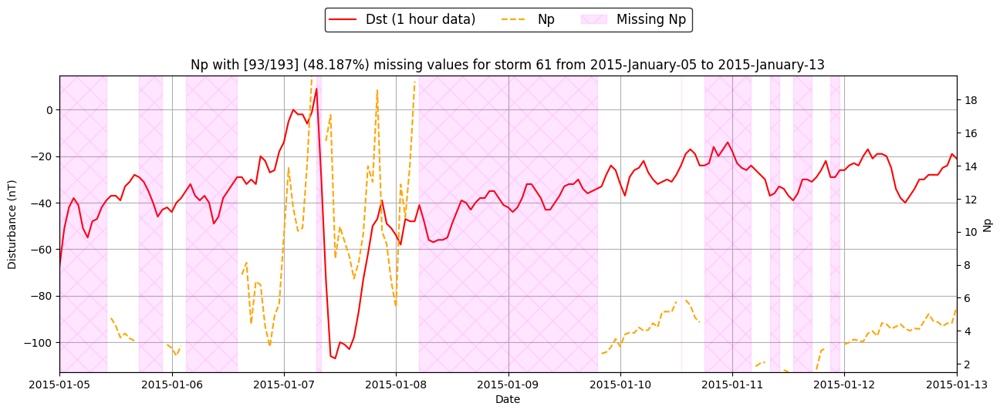

There are ACE missing values in Train storm 62 from 2015 August 14 to 2015 August 22
Np missing 51 values (26.425%)


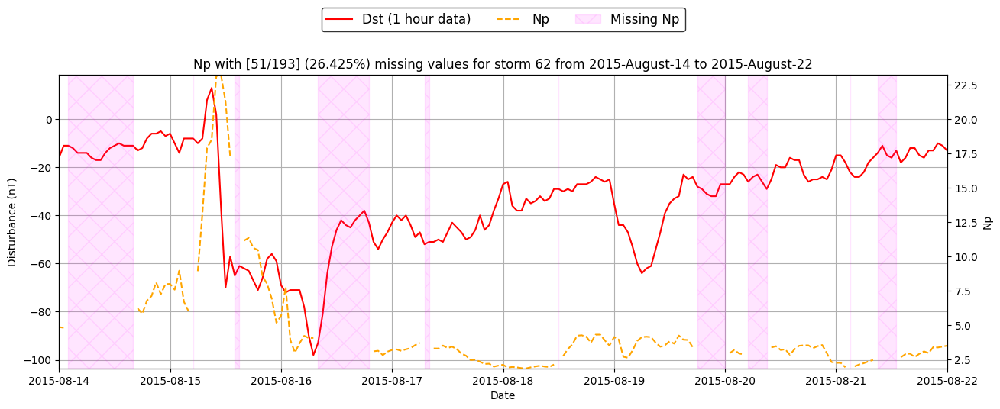

There are ACE missing values in Train storm 63 from 2015 September 07 to 2015 September 15
Np missing 37 values (19.171%)


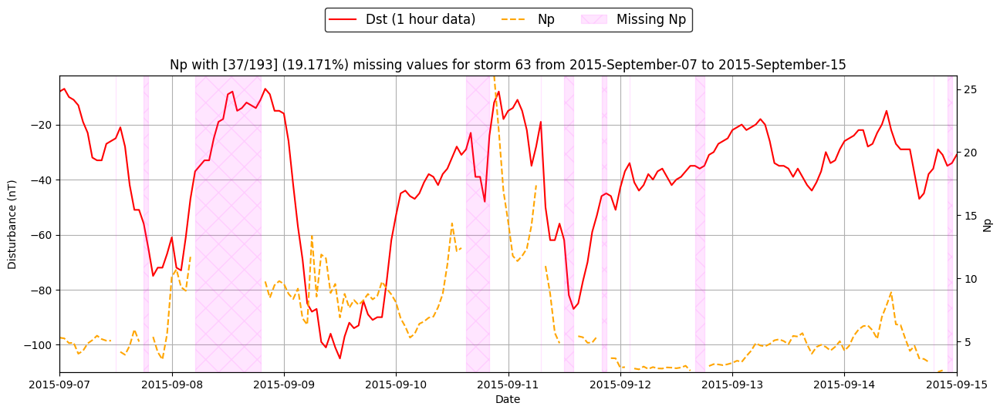

There are ACE missing values in Train storm 64 from 2015 October 05 to 2015 October 14
Np missing 13 values (5.991%)


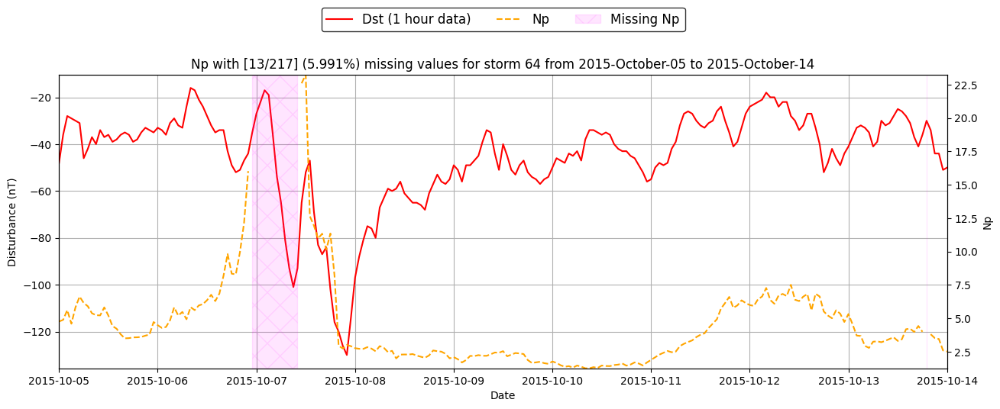

There are ACE missing values in Train storm 65 from 2015 December 29 to 2016 January 07
Np missing 75 values (34.091%)


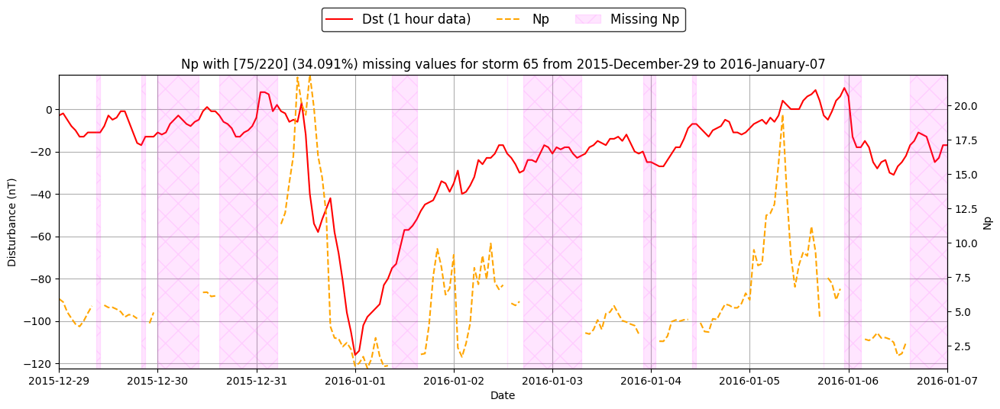

There are ACE missing values in Train storm 66 from 2016 January 18 to 2016 January 26
Np missing 156 values (80.829%)


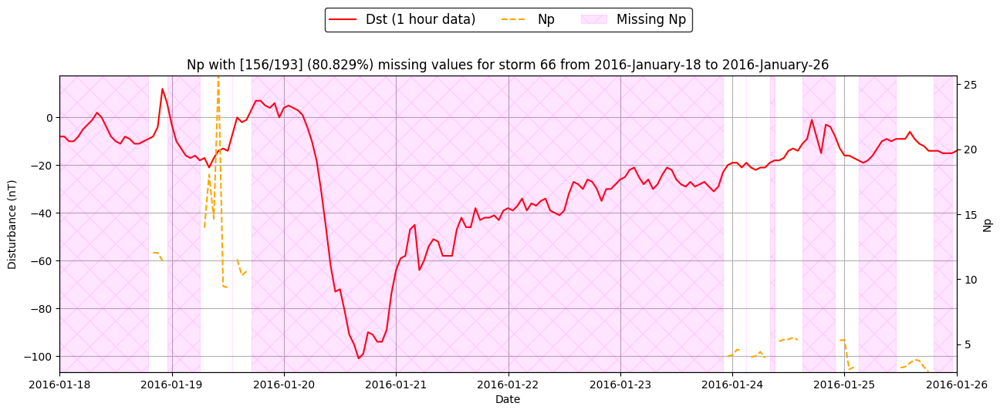

There are ACE missing values in Train storm 67 from 2016 March 04 to 2016 March 12
Np missing 113 values (58.549%)


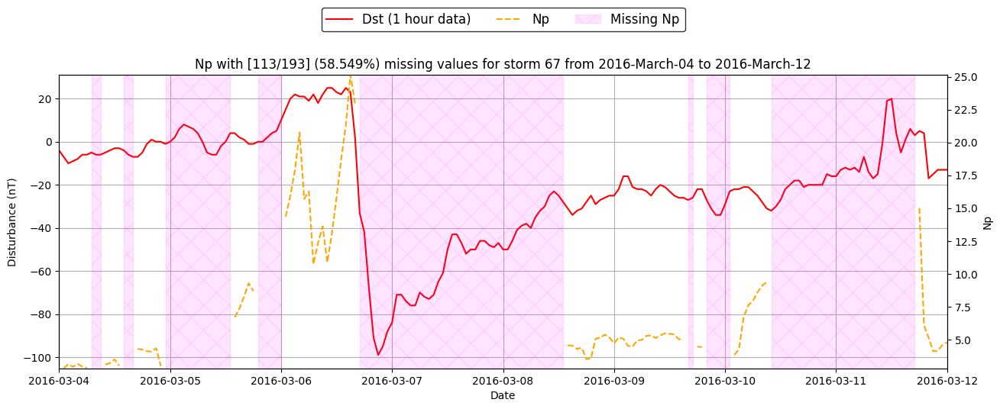

There are ACE missing values in Train storm 68 from 2016 May 06 to 2016 May 14
Np missing 36 values (18.653%)


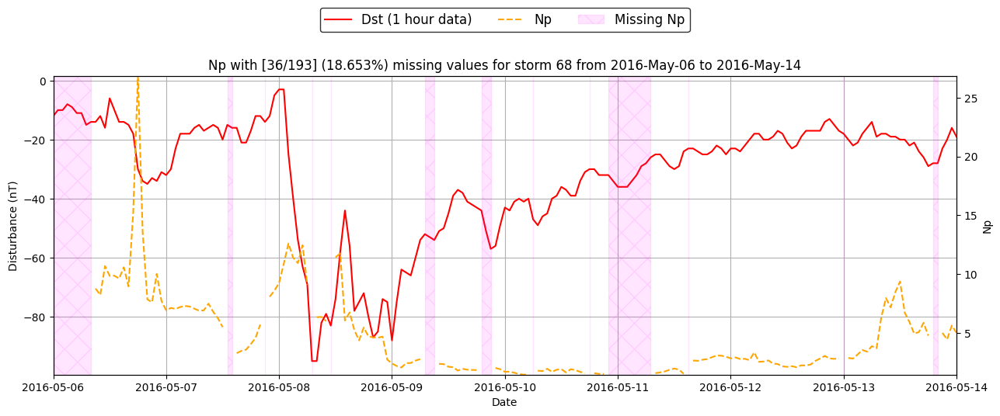

There are ACE missing values in Train storm 69 from 2016 October 11 to 2016 October 20
Np missing 12 values (5.530%)


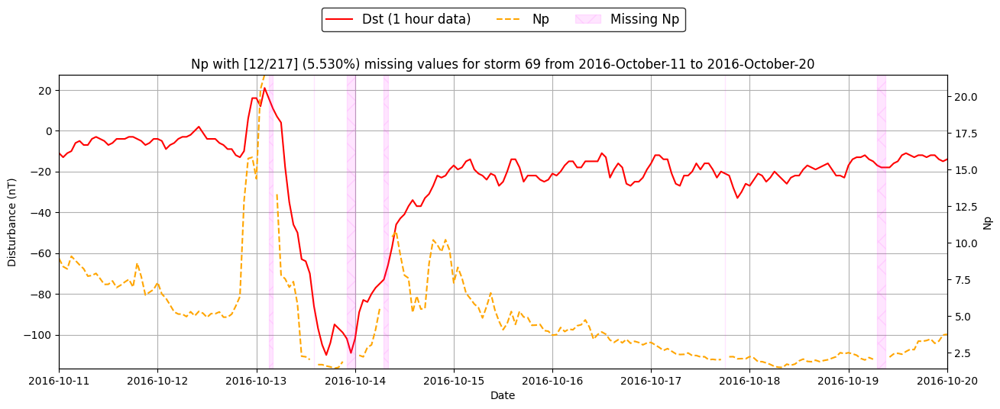

Complete ACE train storms [19/68]


In [ ]:
PLOT_COMPLETE_STORMS = False
PLOT_INCOMPLETE_STORMS = True

valid_ace_train_storms = 0
for start_date, end_date, storm_index in storm_dates.TRAIN_STORMS_SYMBOLIC_REGRESSION:
    sd = pd.to_datetime(start_date)
    ed = pd.to_datetime(end_date)
    storm = ace_data[sd:ed].copy()
    if storm[ace_columns].isna().sum().sum() == 0:
        print(f'Train storm {storm_index} from {sd.strftime("%Y %B %d")} to {ed.strftime("%Y %B %d")} has no missing values')
        valid_ace_train_storms += 1
        if not PLOT_COMPLETE_STORMS:
            continue
            
        plot_storm(dst_kyoto, storm, None, sd, ed, storm_index)
        
    else:
        print(f'There are ACE missing values in Train storm {storm_index} from {sd.strftime("%Y %B %d")} to {ed.strftime("%Y %B %d")}')
        if not PLOT_INCOMPLETE_STORMS:
            continue
            
        col = storm[ace_columns].isna().sum().sort_values(ascending=False).index[0]
        print(f'{col} missing {storm[col].isna().sum()} values ({storm[col].isna().sum() / len(storm[col]) * 100:.3f}%)')
        plot_storm(dst_kyoto, storm, col, sd, ed, storm_index)
        
    
print(f'Complete ACE train storms [{valid_ace_train_storms}/{len(storm_dates.TRAIN_STORMS_SYMBOLIC_REGRESSION)}]')

There are ACE missing values in test storm 89 from 2017 September 06 to 2017 September 15
Bz missing 0 values (0.000%)


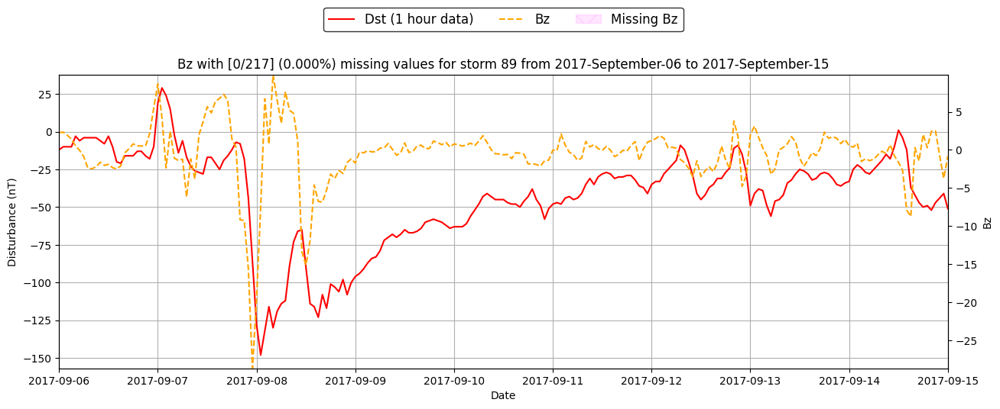

Vp missing 29 values (13.364%)


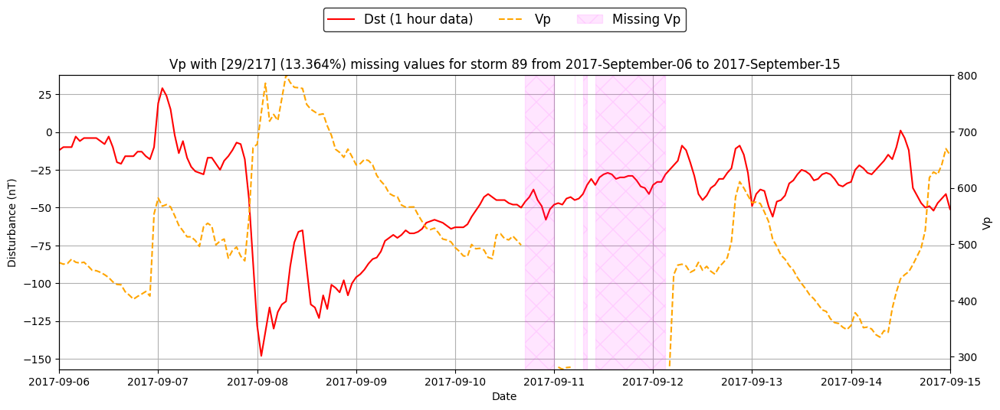

Np missing 29 values (13.364%)


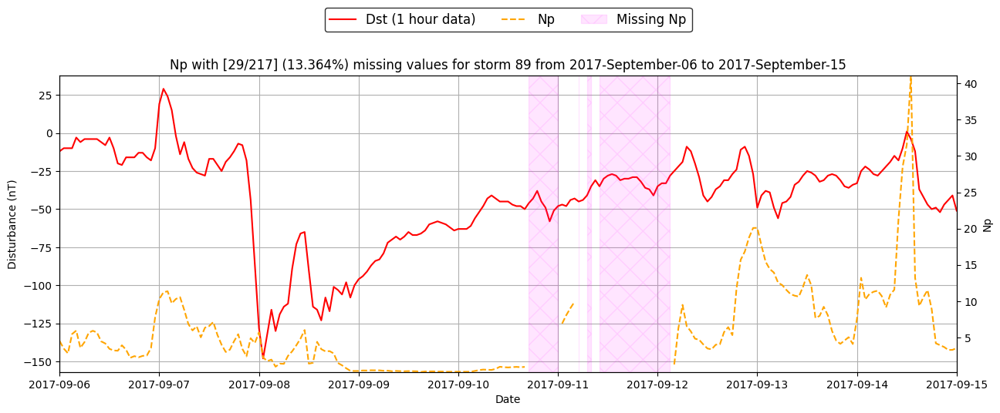

T missing 29 values (13.364%)


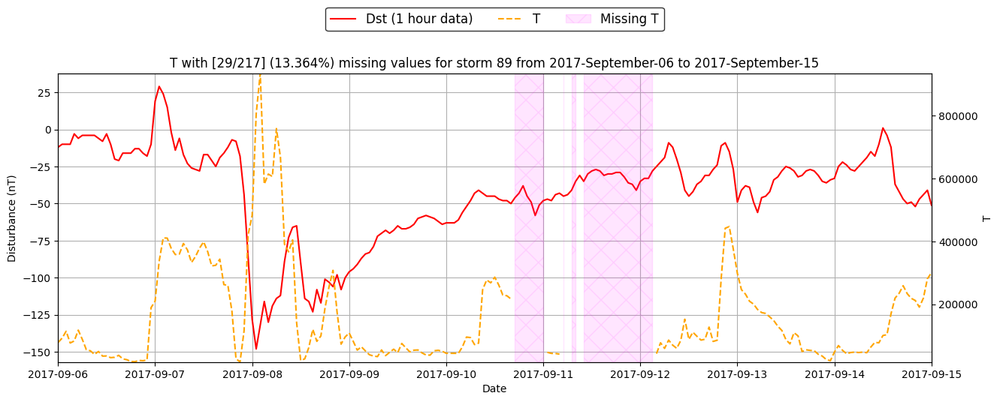

Bmag missing 0 values (0.000%)


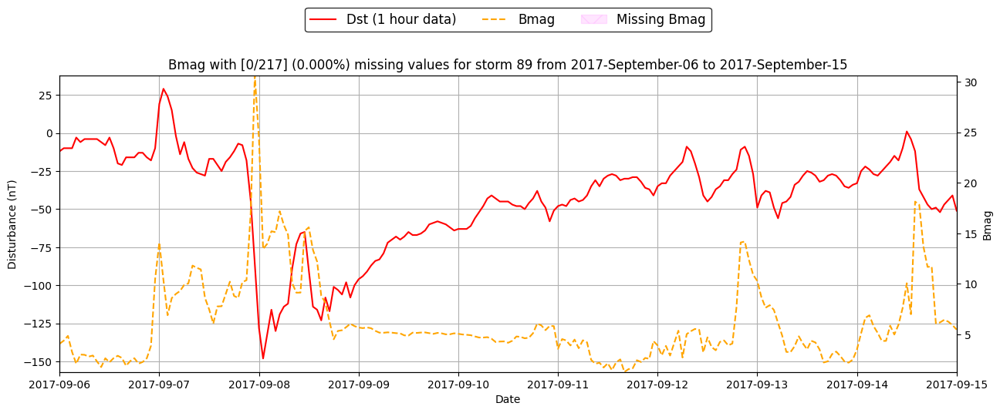

Test storm 90 from 2017 September 26 to 2017 October 04 has no missing values


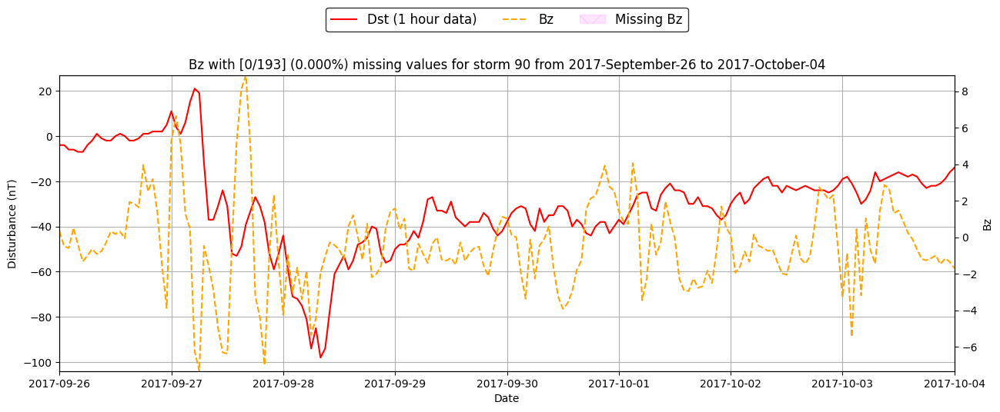

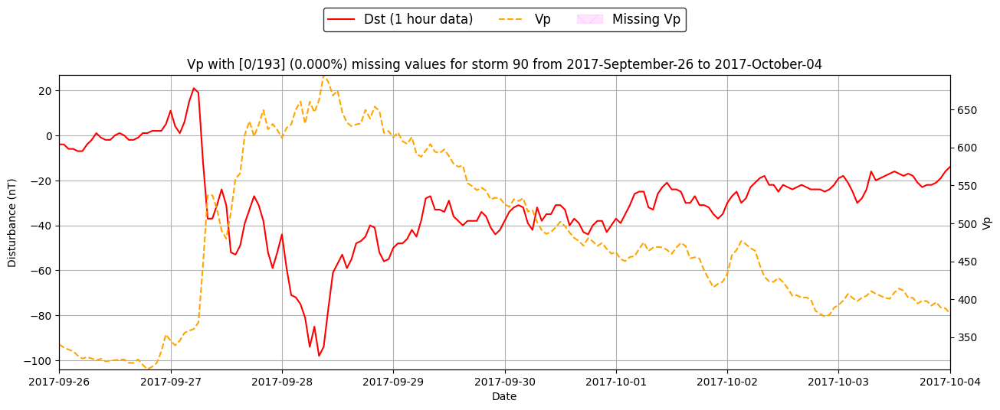

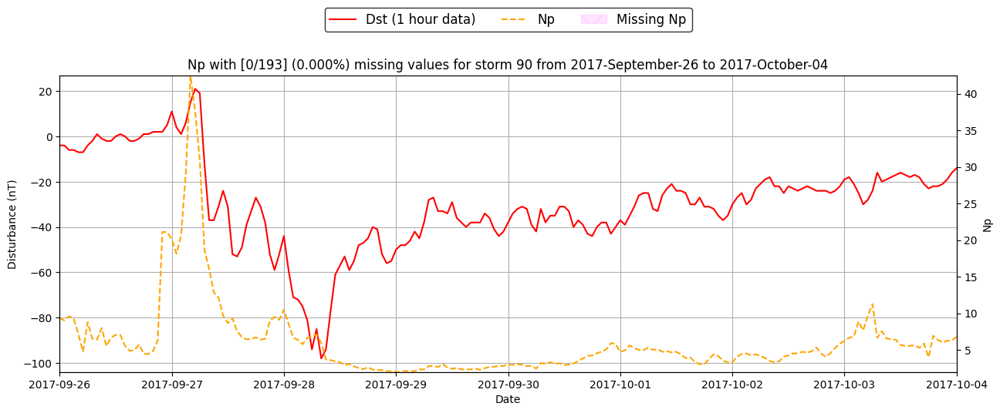

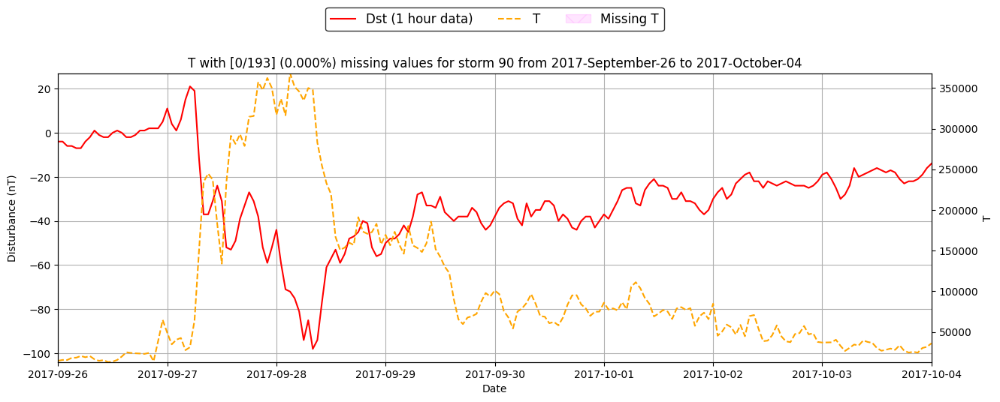

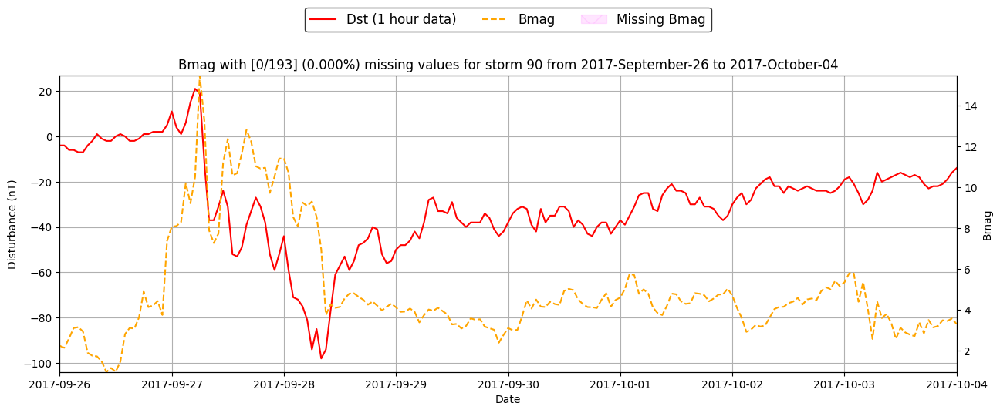

Test storm 91 from 2018 August 24 to 2018 September 01 has no missing values


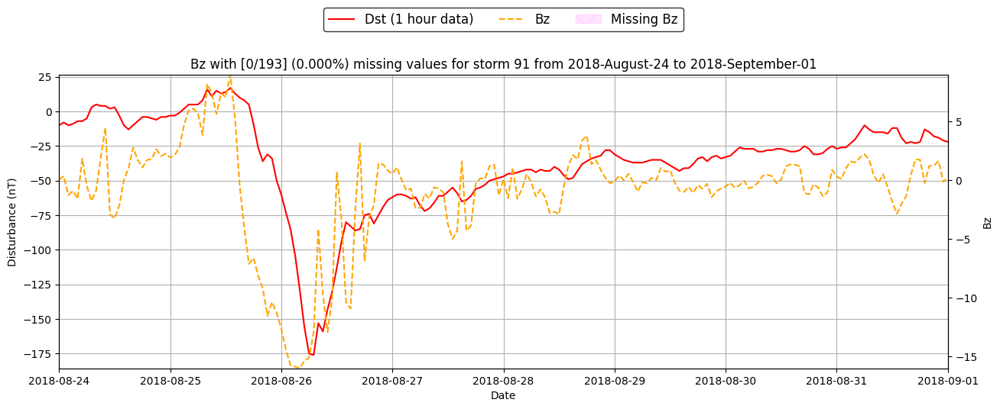

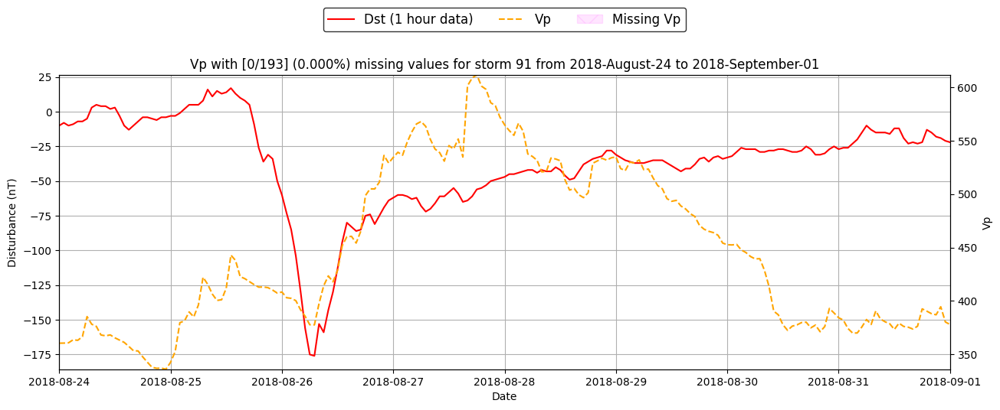

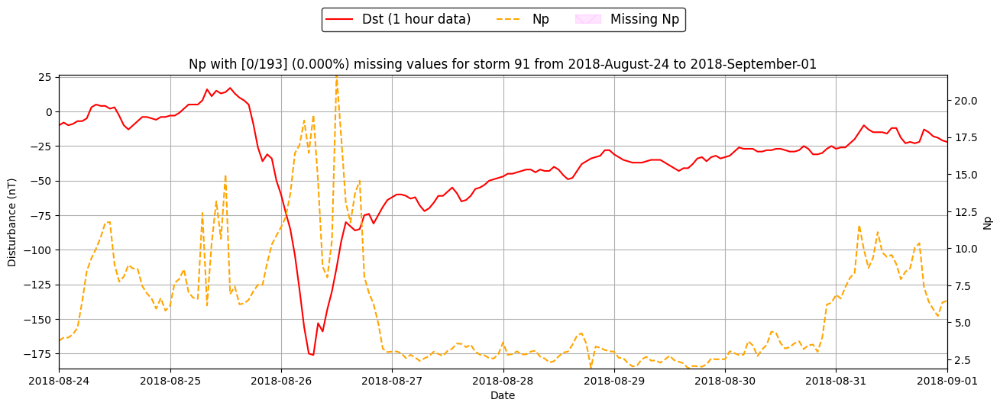

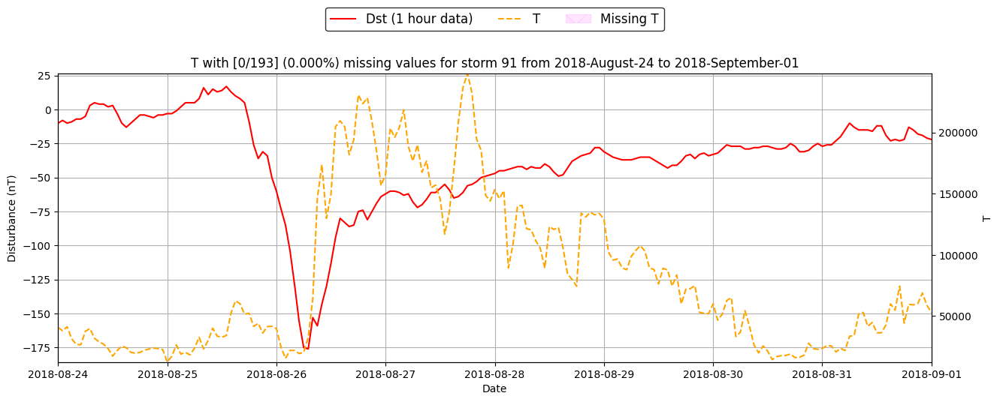

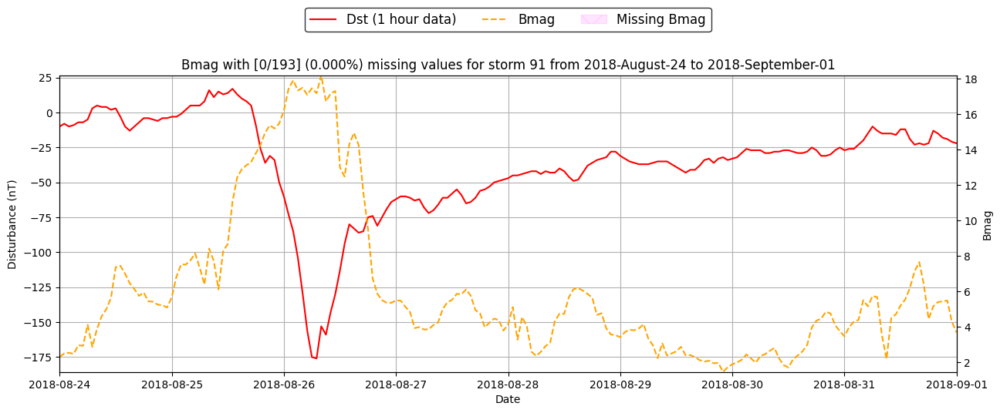

There are ACE missing values in test storm 92 from 2021 November 02 to 2021 November 10
Bz missing 0 values (0.000%)


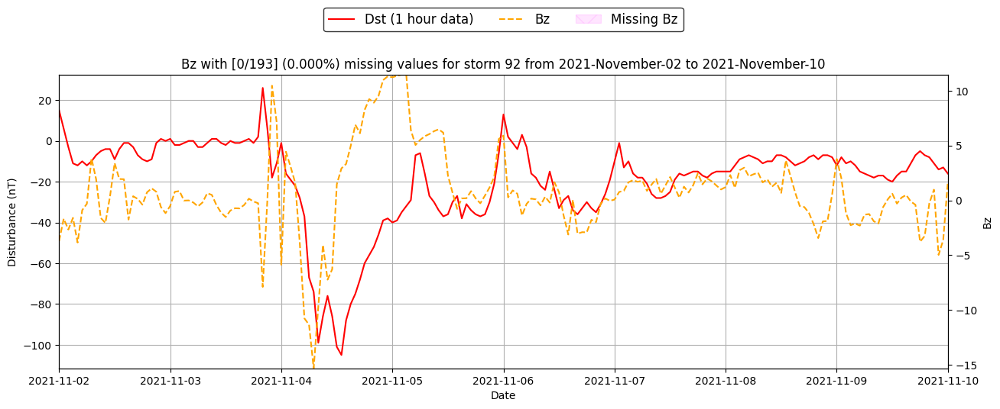

Vp missing 0 values (0.000%)


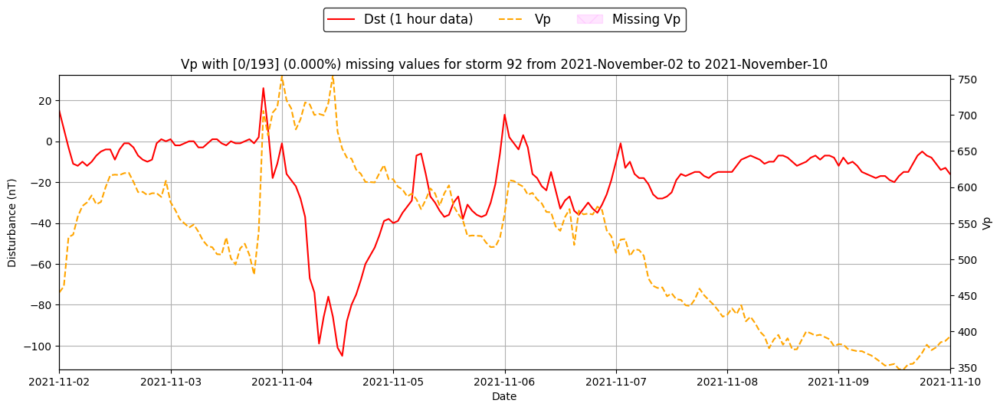

Np missing 4 values (2.073%)


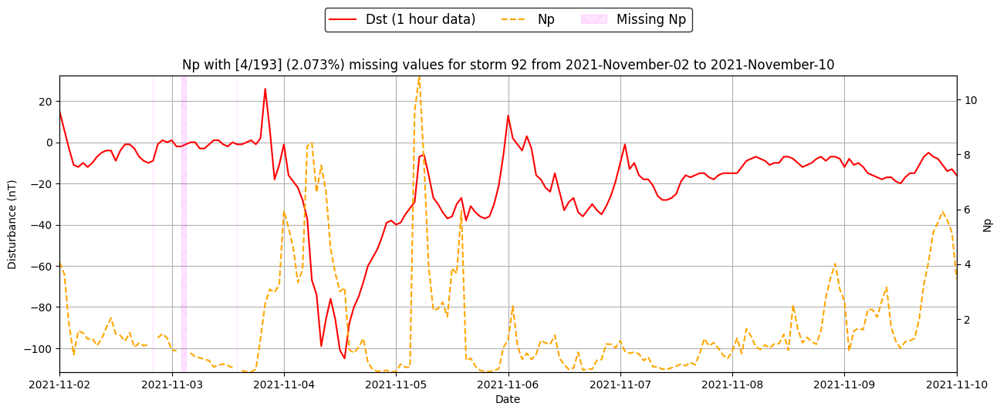

T missing 1 values (0.518%)


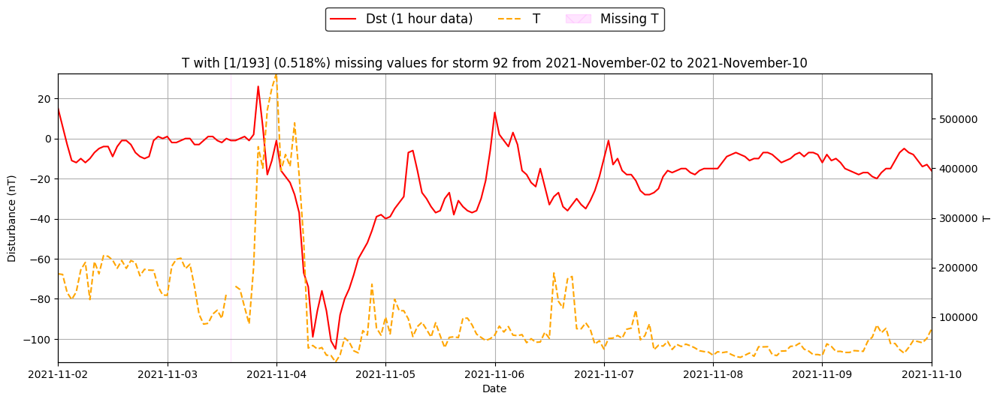

Bmag missing 0 values (0.000%)


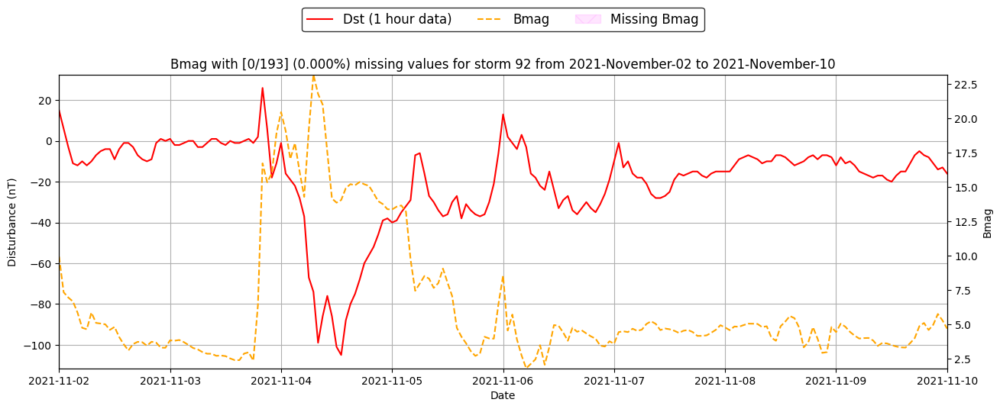

Test storm 93 from 2022 January 12 to 2022 January 20 has no missing values


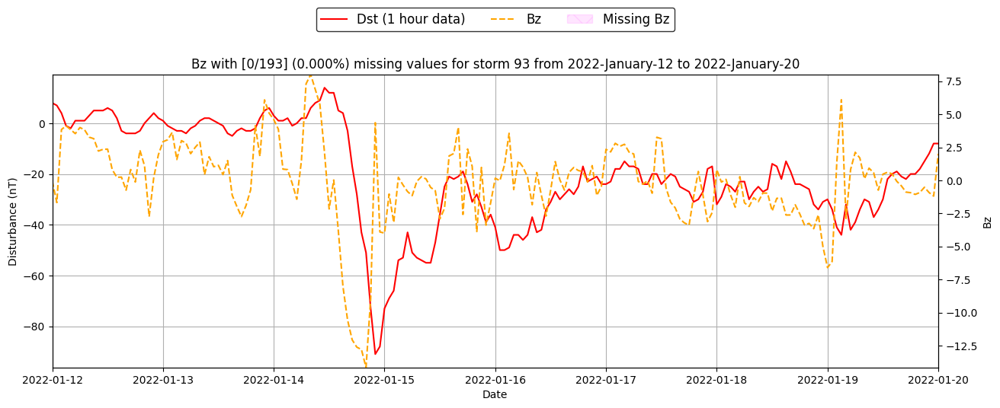

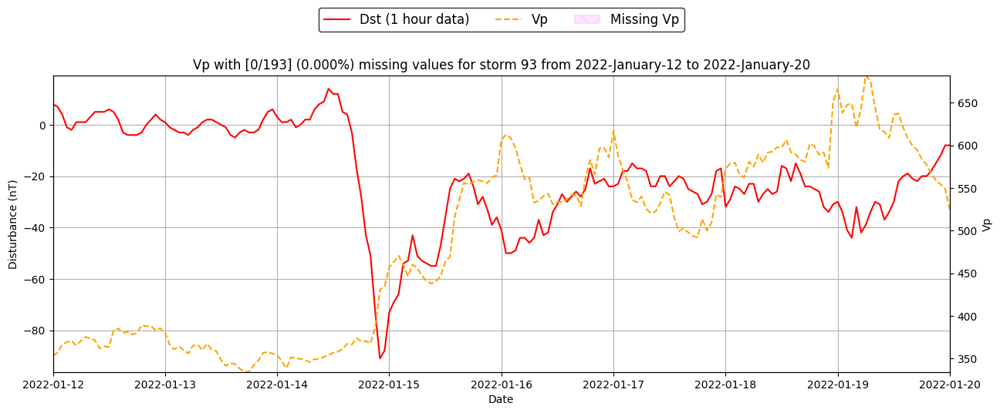

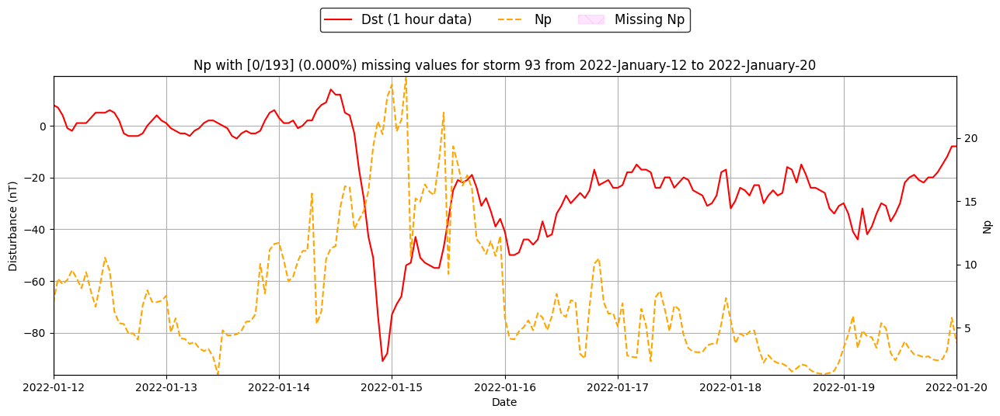

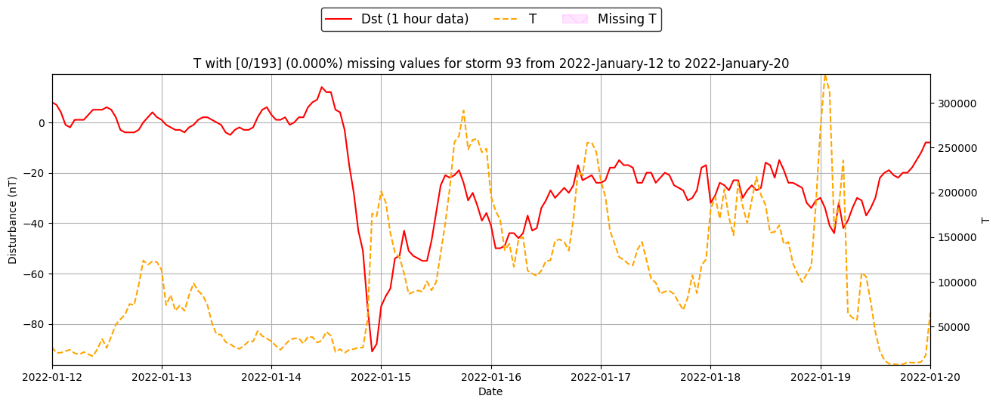

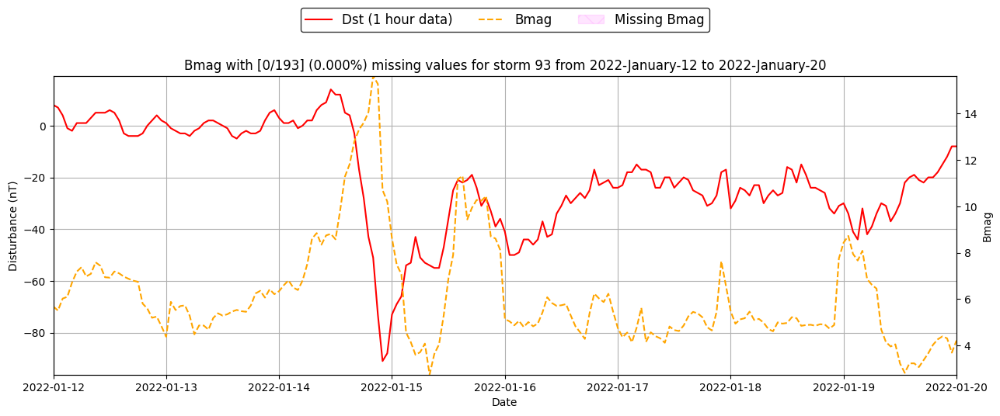

Test storm 94 from 2022 November 05 to 2022 November 13 has no missing values


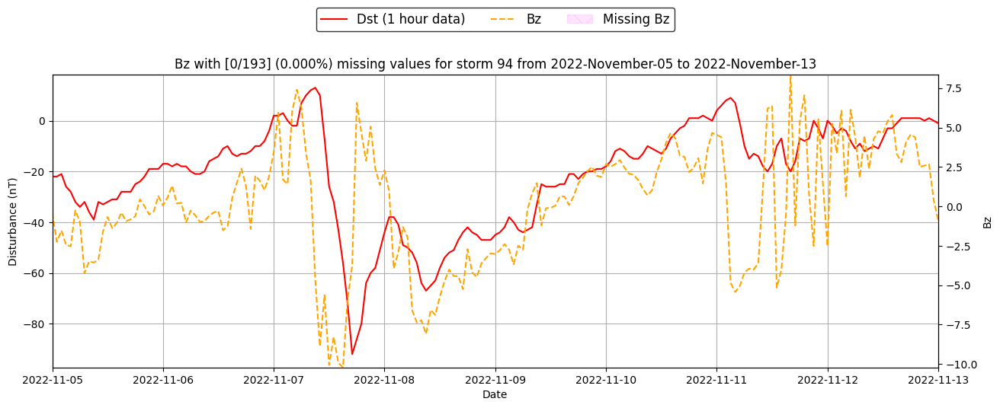

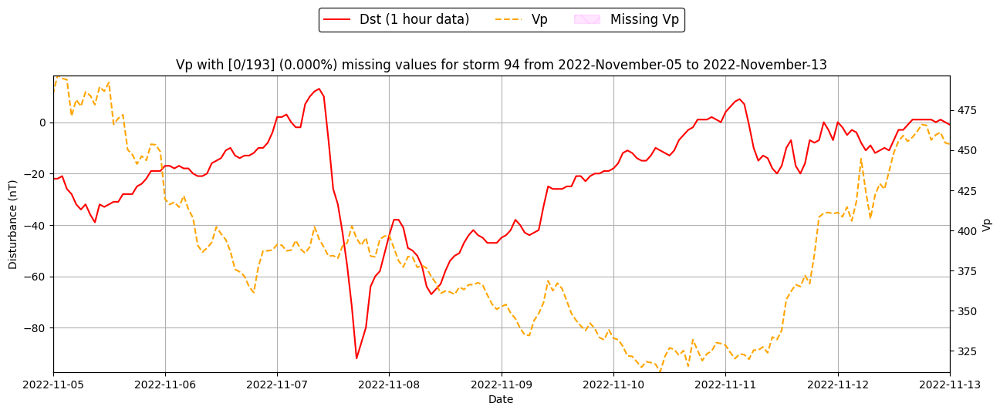

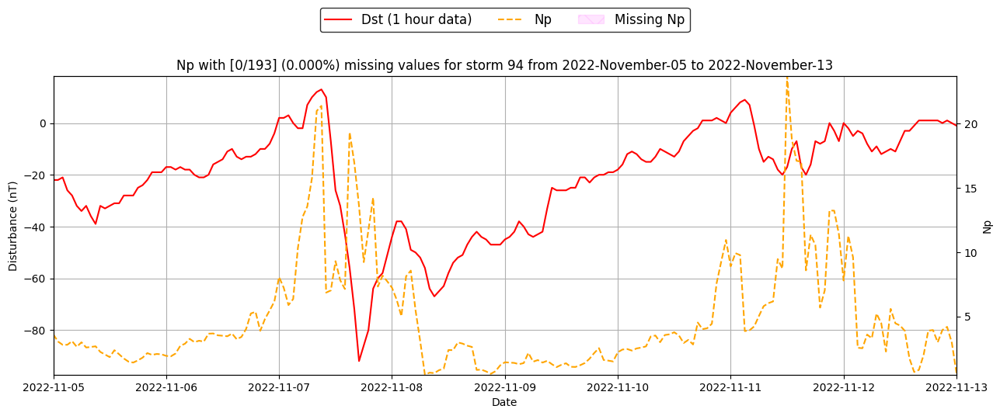

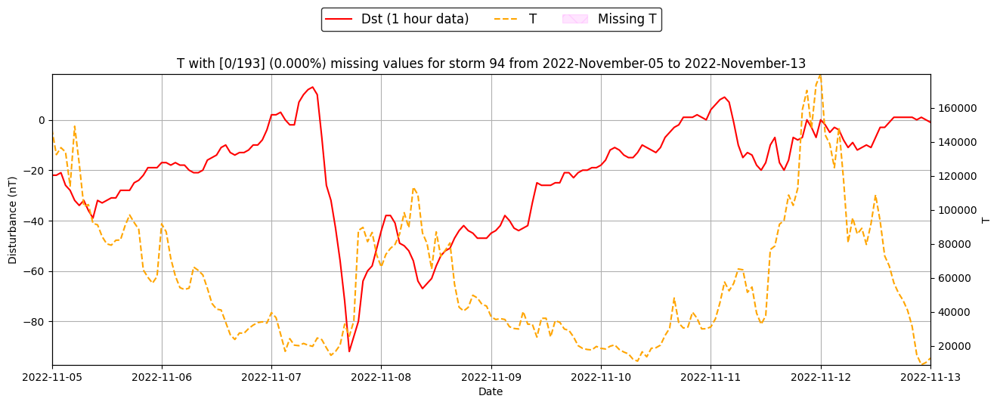

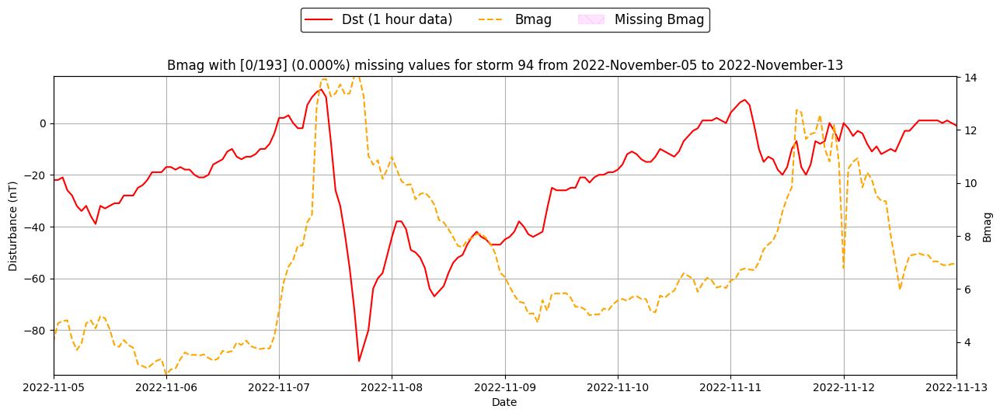

Test storm 95 from 2023 February 25 to 2023 March 06 has no missing values


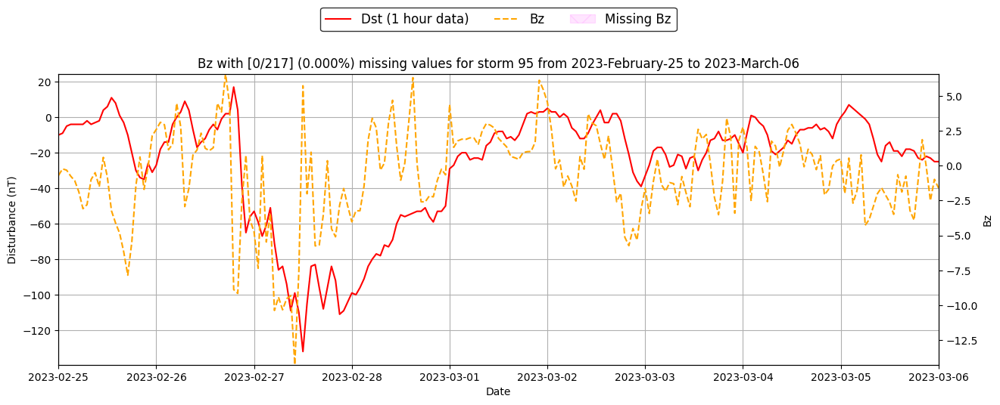

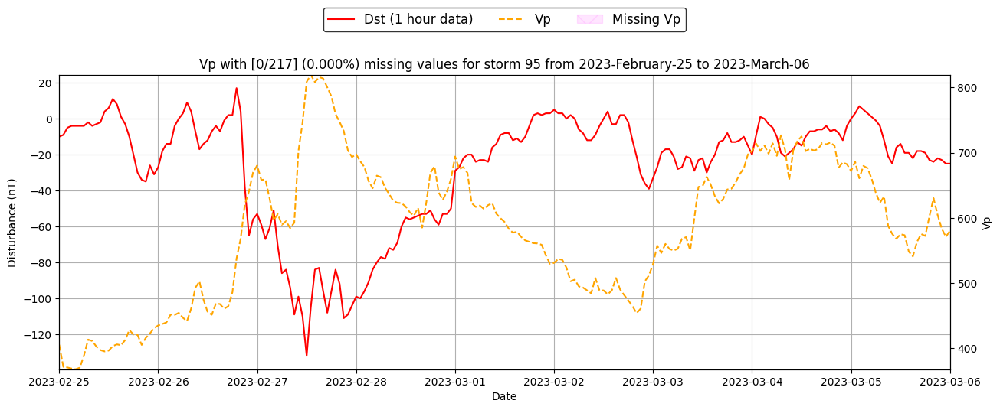

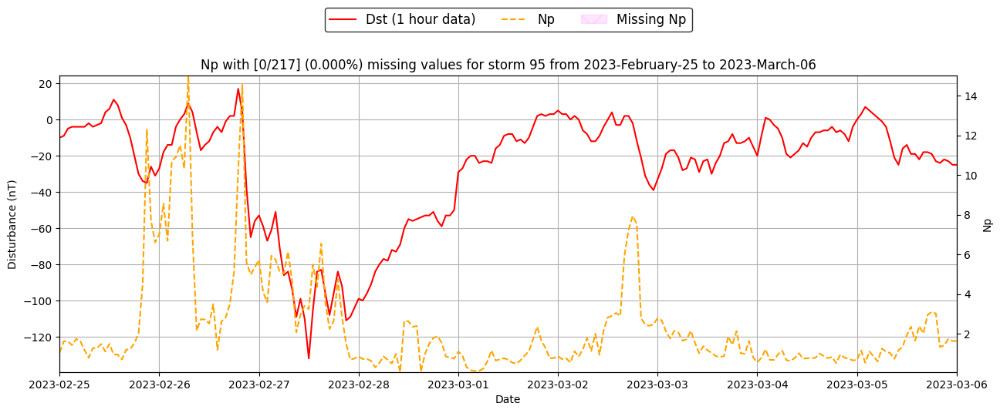

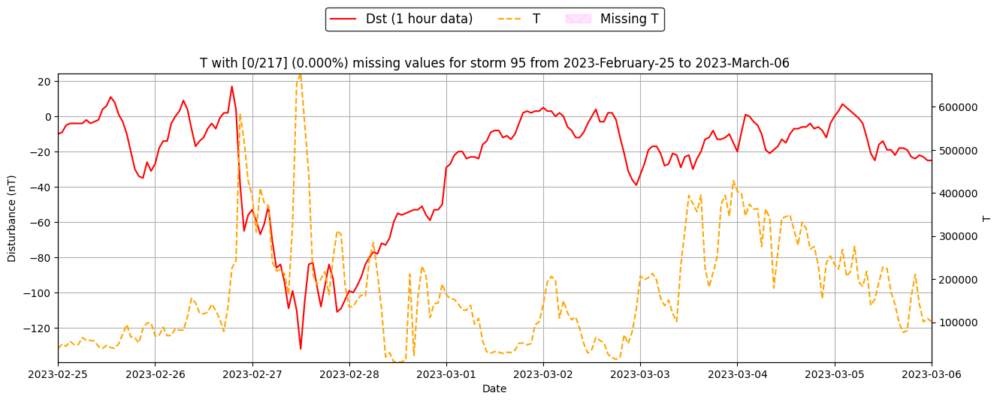

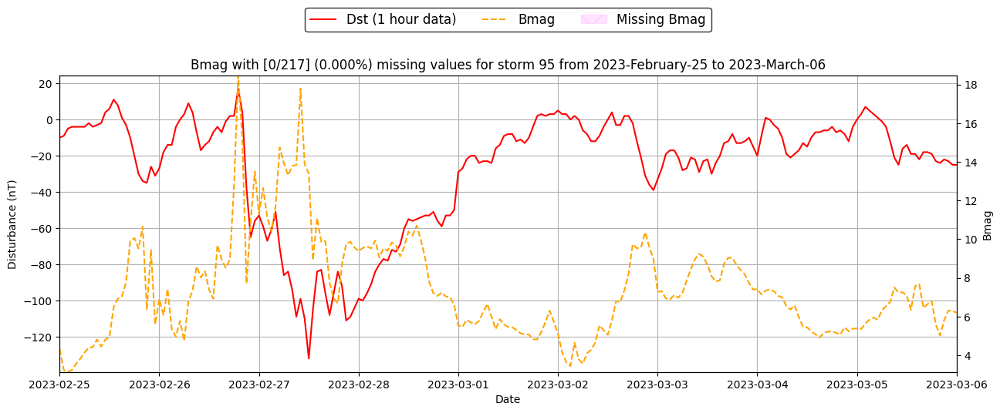

There are ACE missing values in test storm 96 from 2023 March 21 to 2023 March 30
Bz missing 0 values (0.000%)


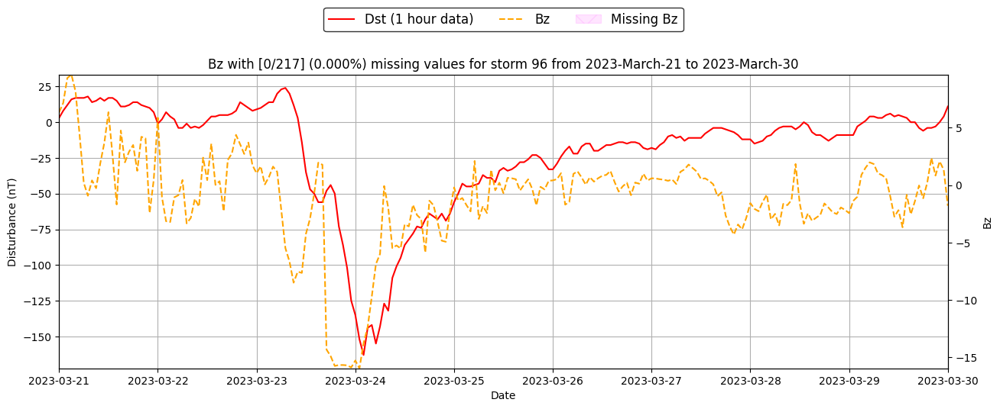

Vp missing 0 values (0.000%)


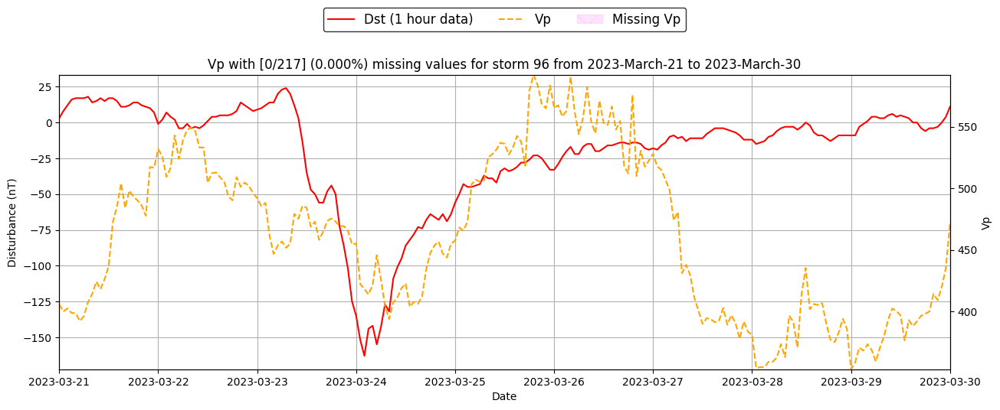

Np missing 4 values (1.843%)


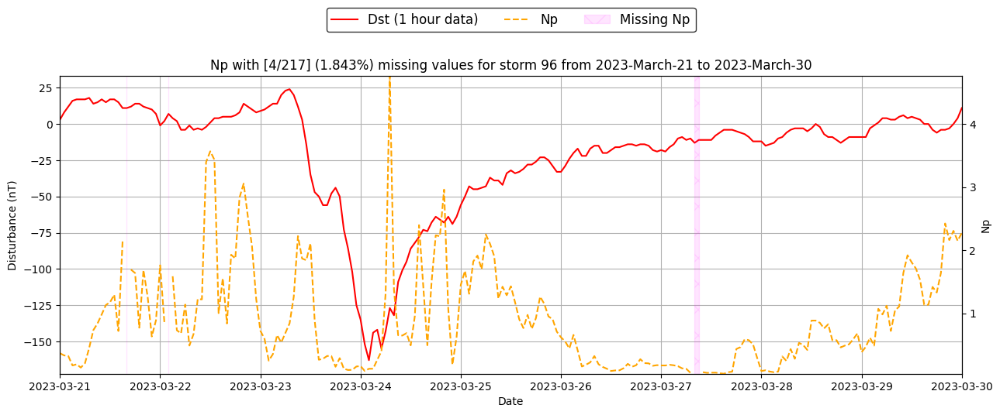

T missing 0 values (0.000%)


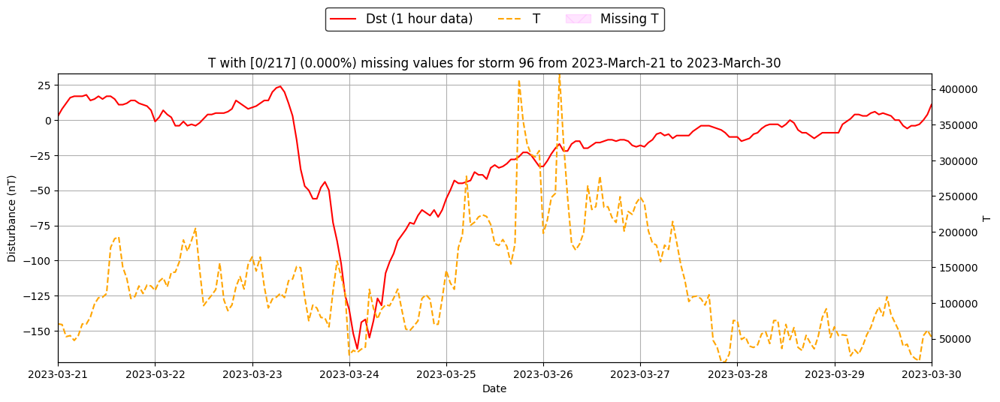

Bmag missing 0 values (0.000%)


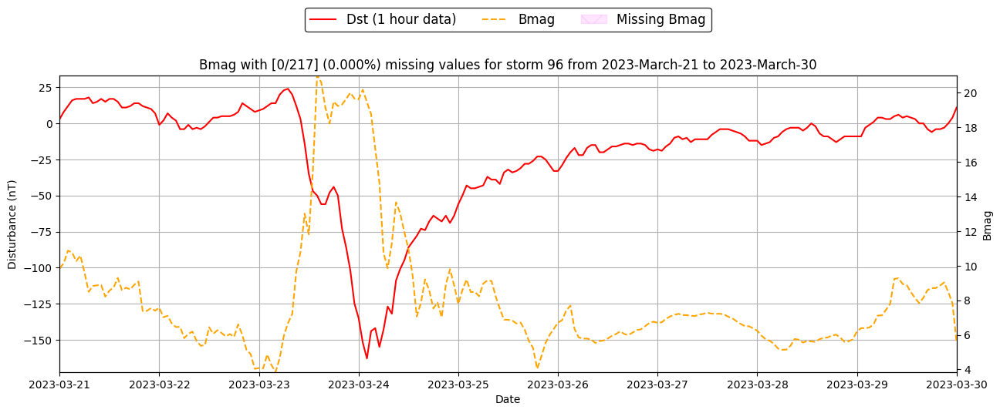

There are ACE missing values in test storm 97 from 2023 April 21 to 2023 April 30
Bz missing 0 values (0.000%)


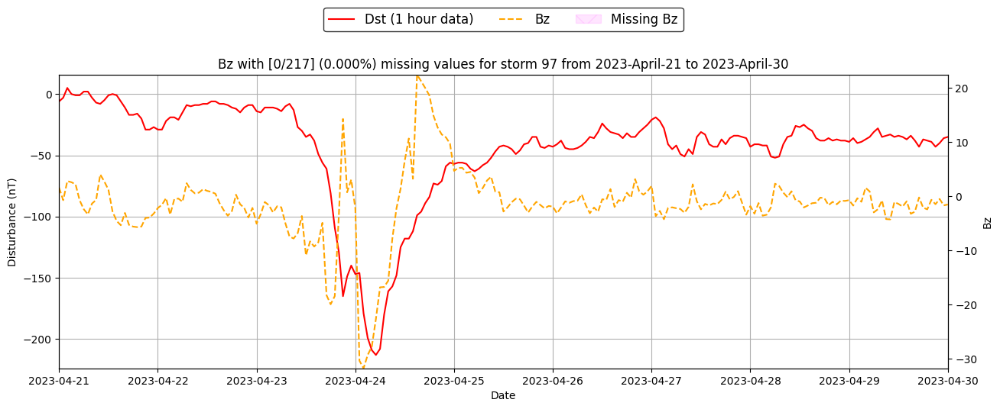

Vp missing 0 values (0.000%)


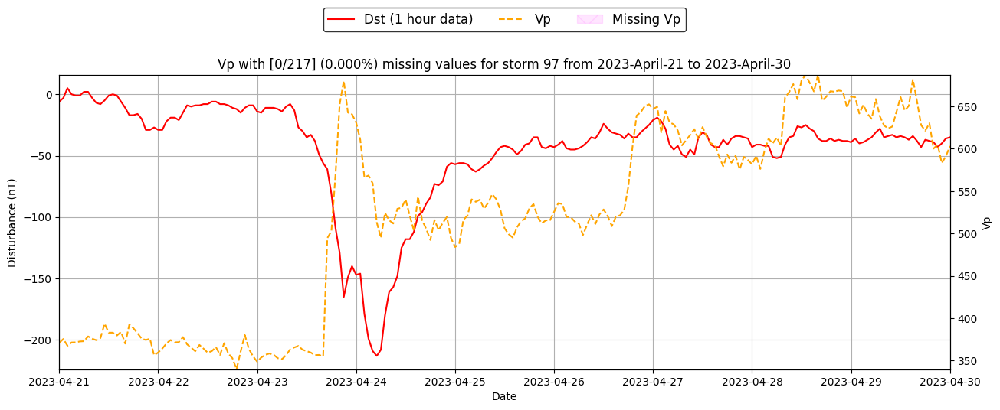

Np missing 1 values (0.461%)


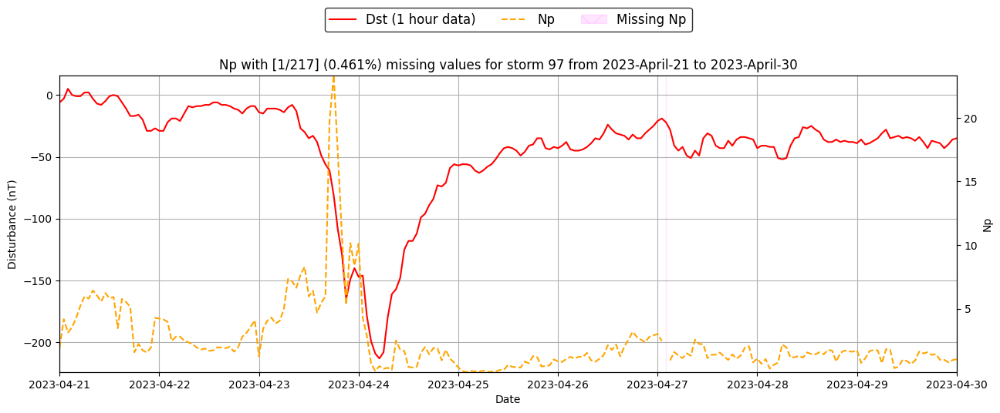

T missing 0 values (0.000%)


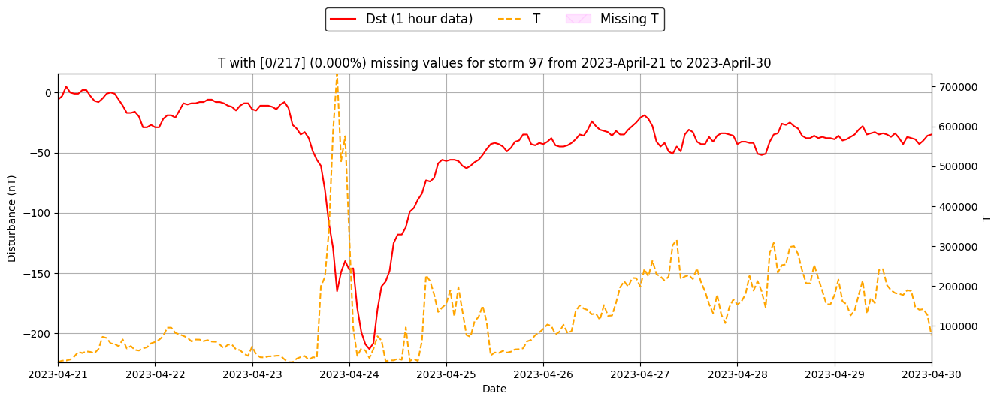

Bmag missing 0 values (0.000%)


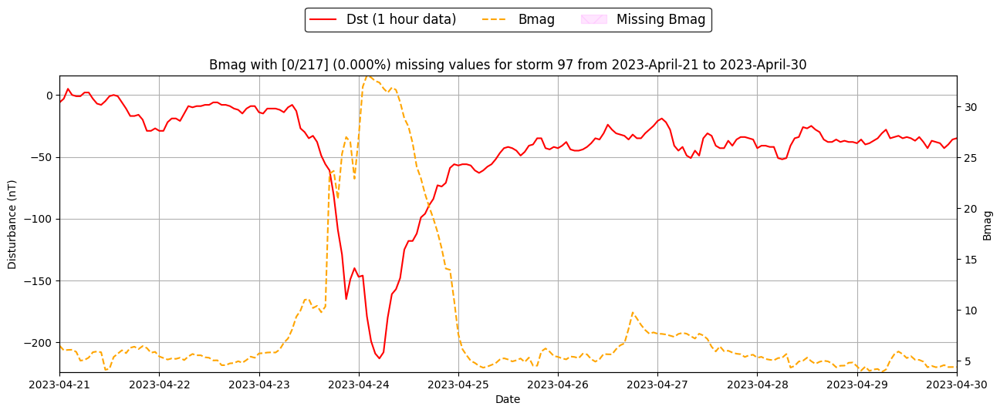

Test storm 98 from 2023 August 03 to 2023 August 11 has no missing values


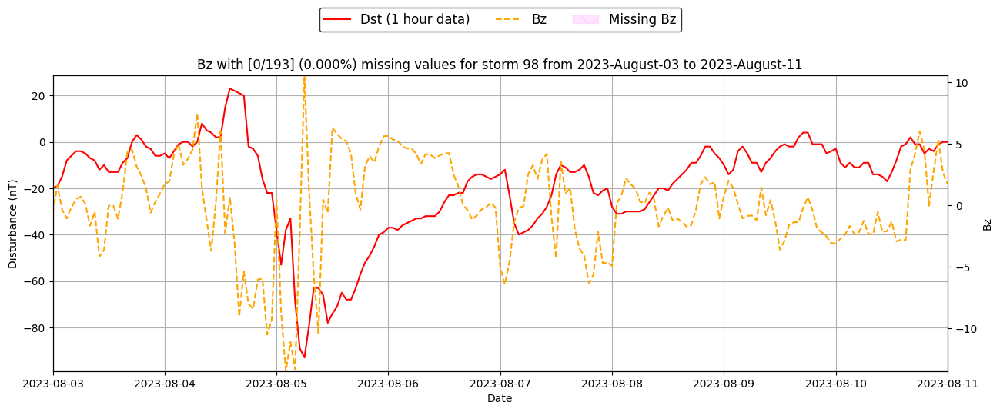

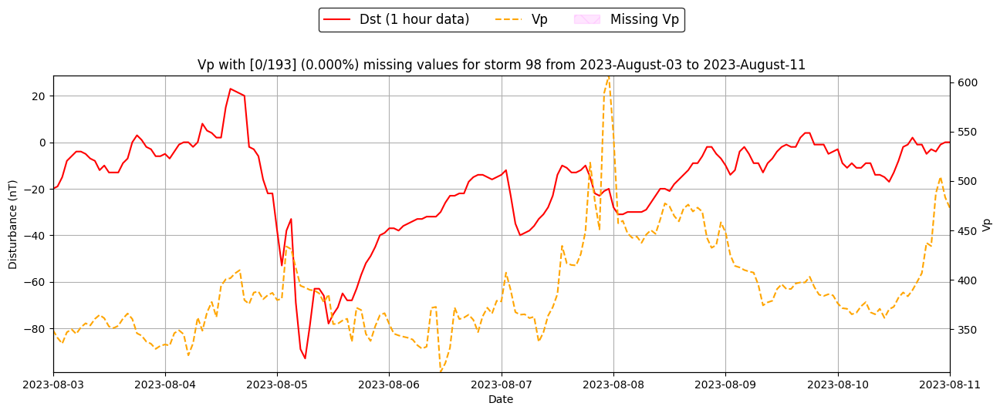

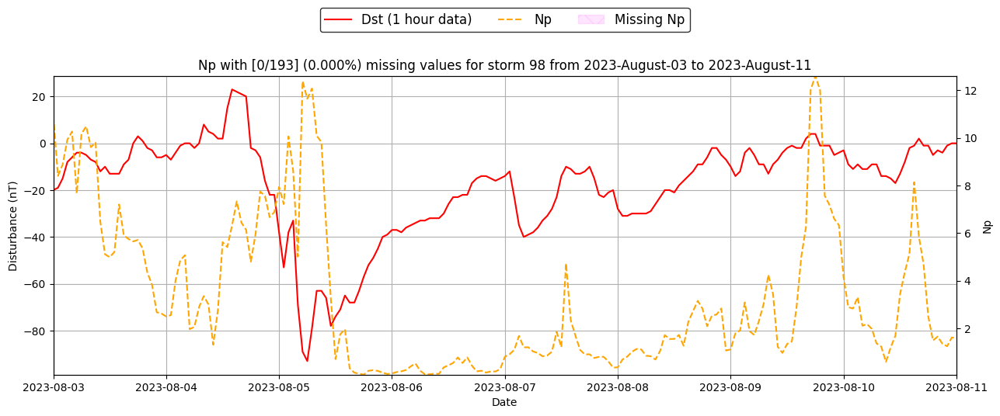

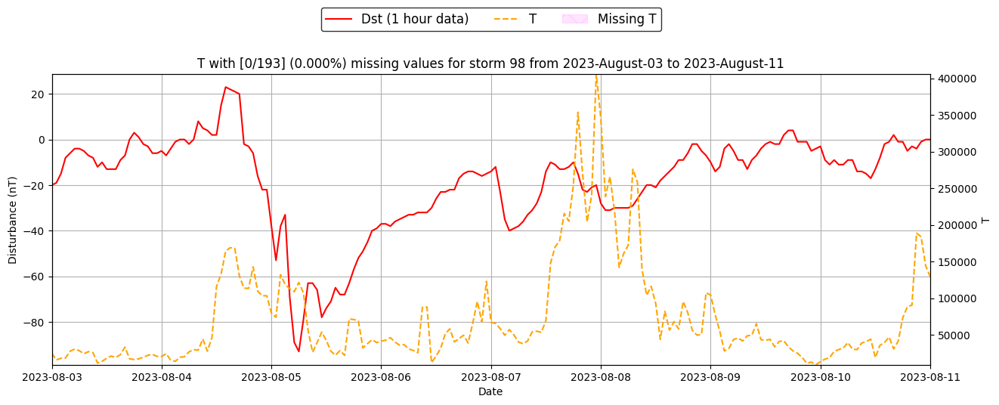

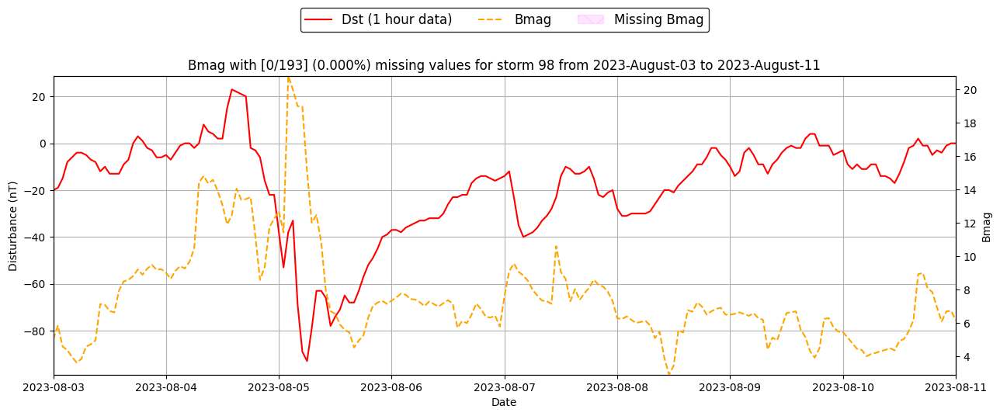

There are ACE missing values in test storm 99 from 2023 November 03 to 2023 November 12
Bz missing 0 values (0.000%)


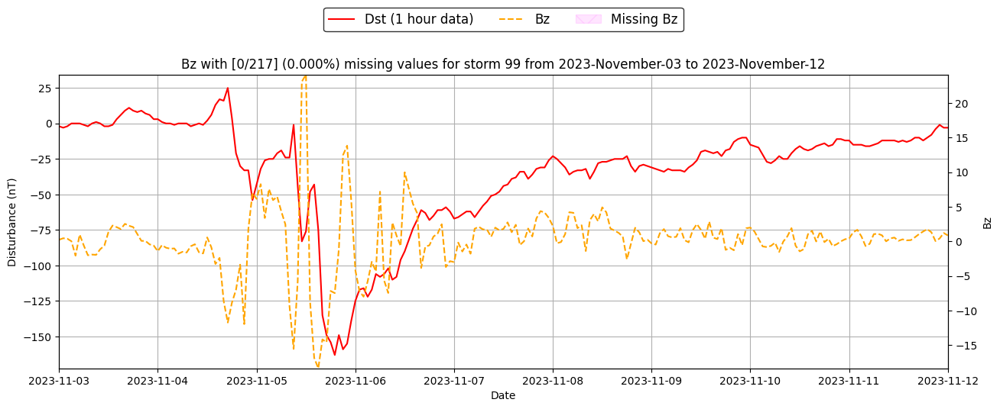

Vp missing 0 values (0.000%)


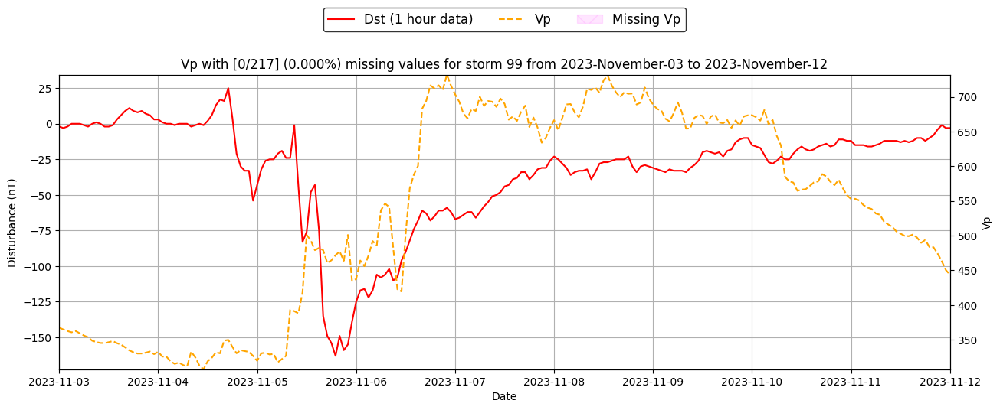

Np missing 1 values (0.461%)


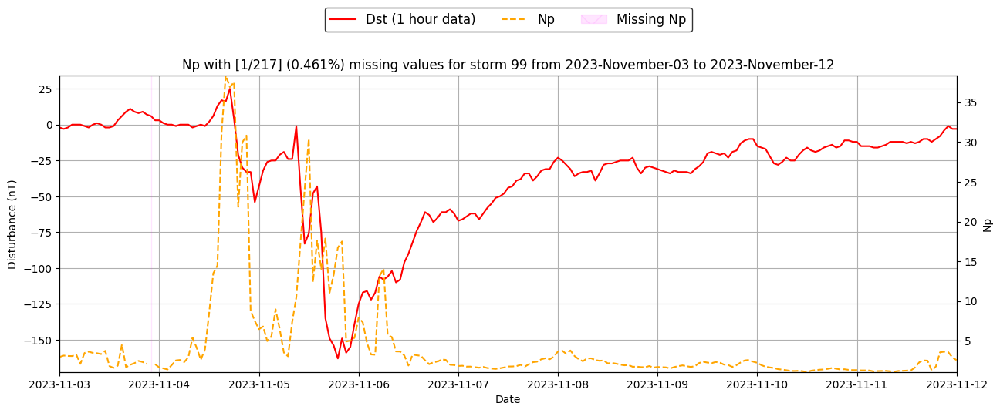

T missing 0 values (0.000%)


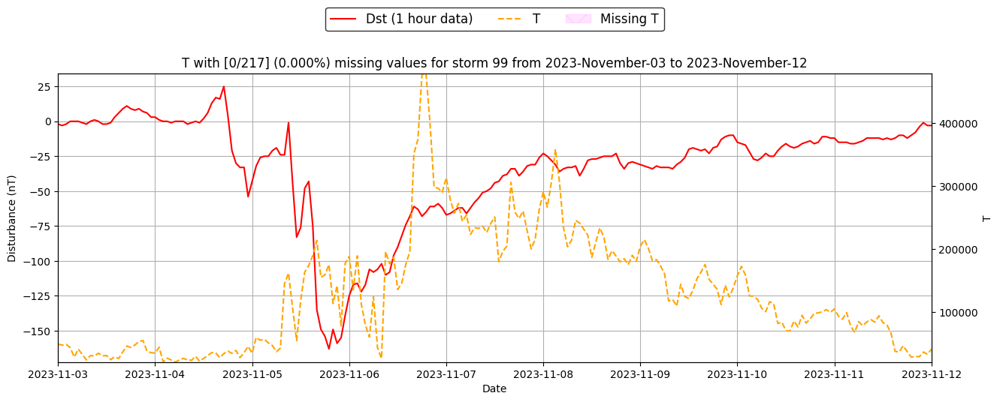

Bmag missing 0 values (0.000%)


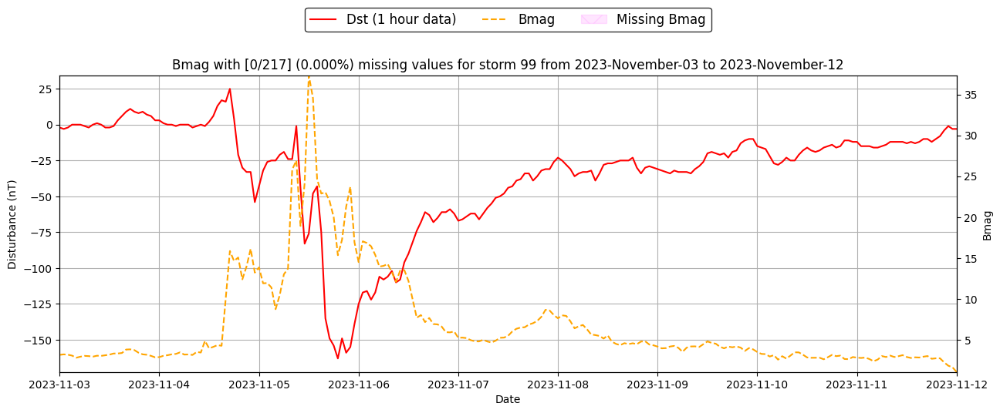

There are ACE missing values in test storm 100 from 2023 November 23 to 2023 December 08
Bz missing 0 values (0.000%)


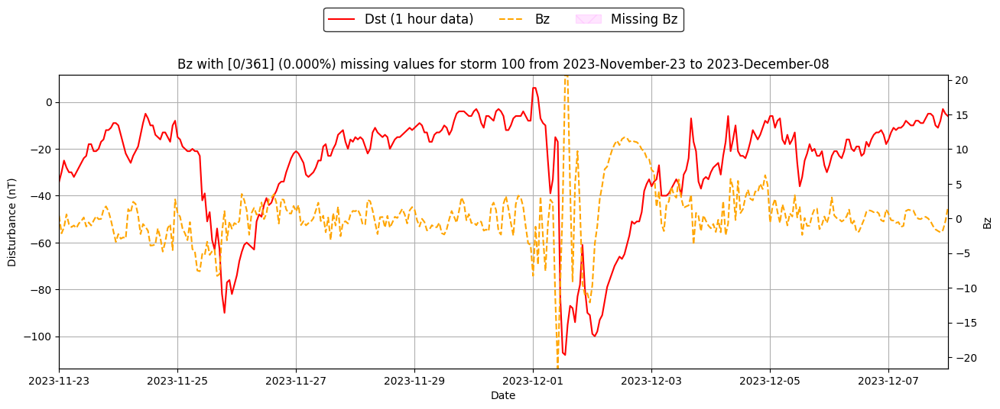

Vp missing 0 values (0.000%)


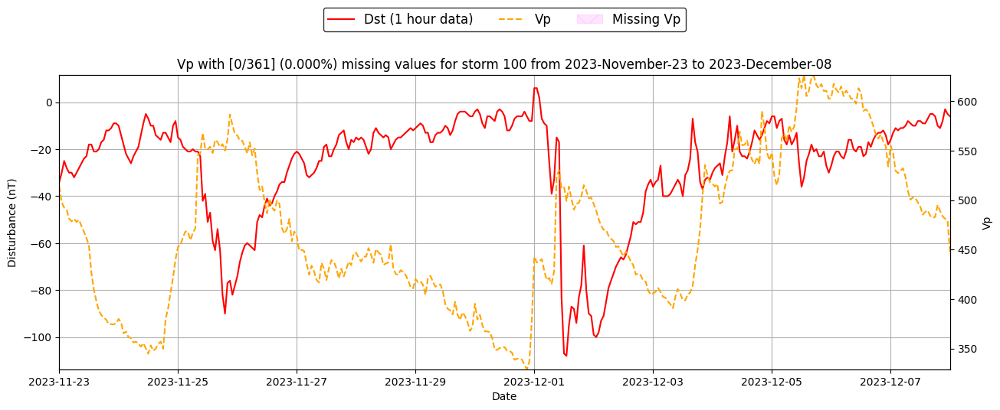

Np missing 1 values (0.277%)


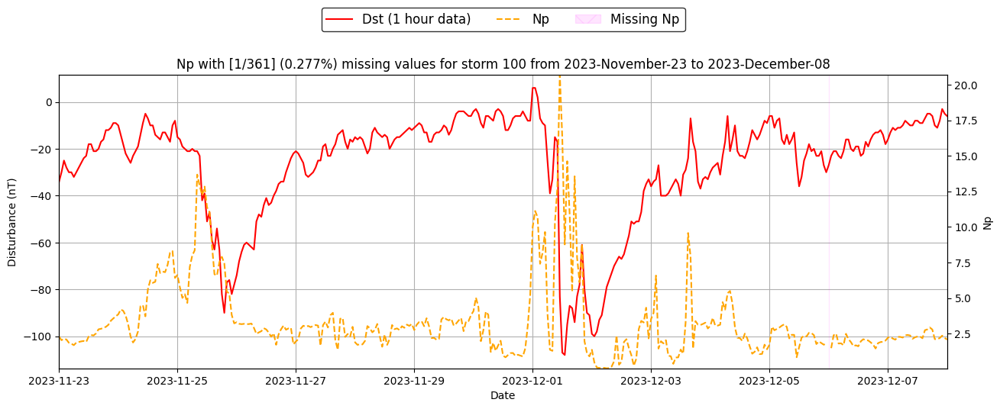

T missing 0 values (0.000%)


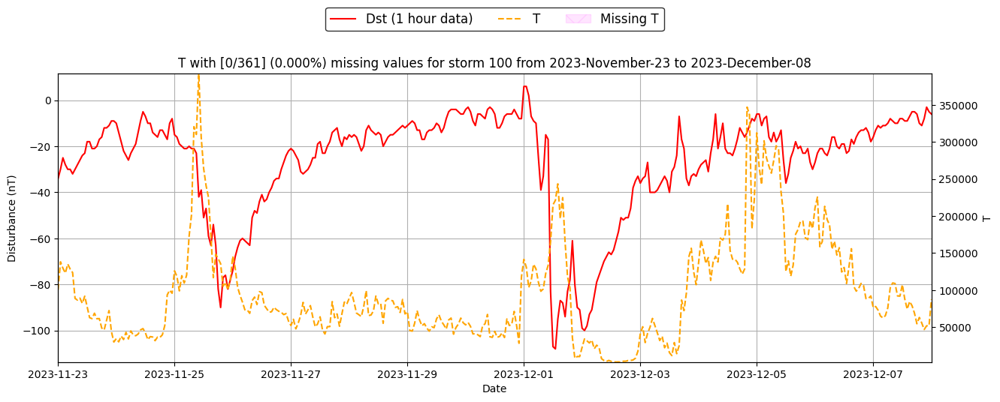

Bmag missing 0 values (0.000%)


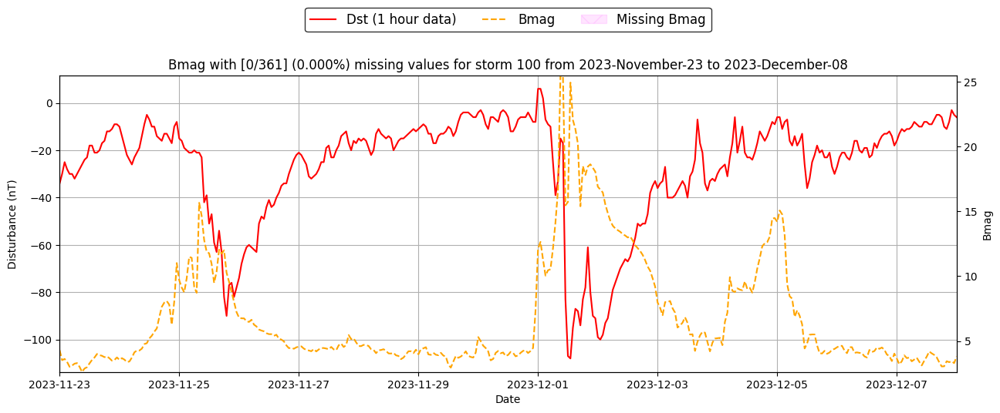

There are ACE missing values in test storm 101 from 2024 March 01 to 2024 March 09
Bz missing 0 values (0.000%)


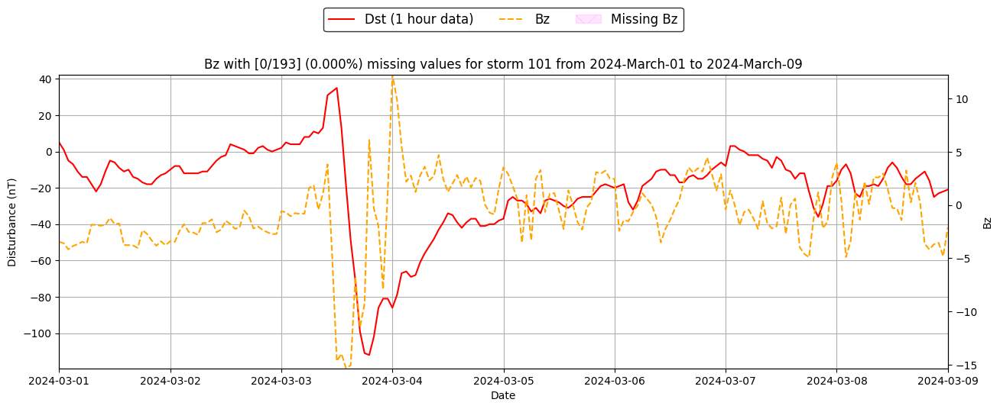

Vp missing 0 values (0.000%)


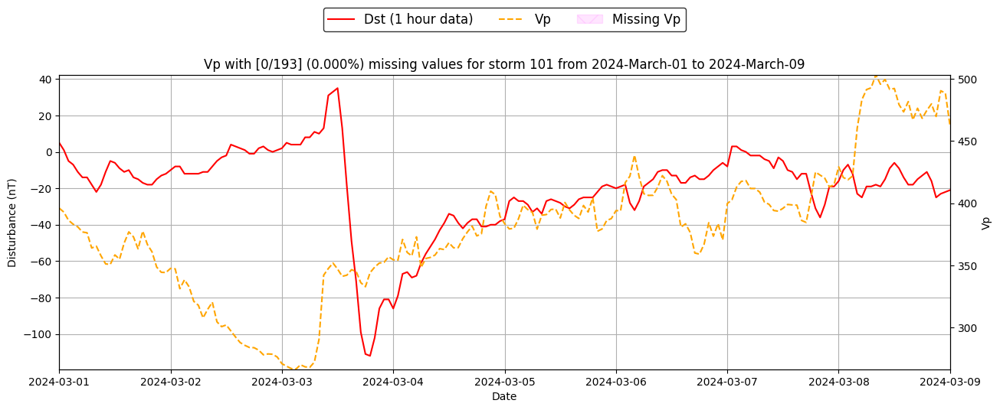

Np missing 3 values (1.554%)


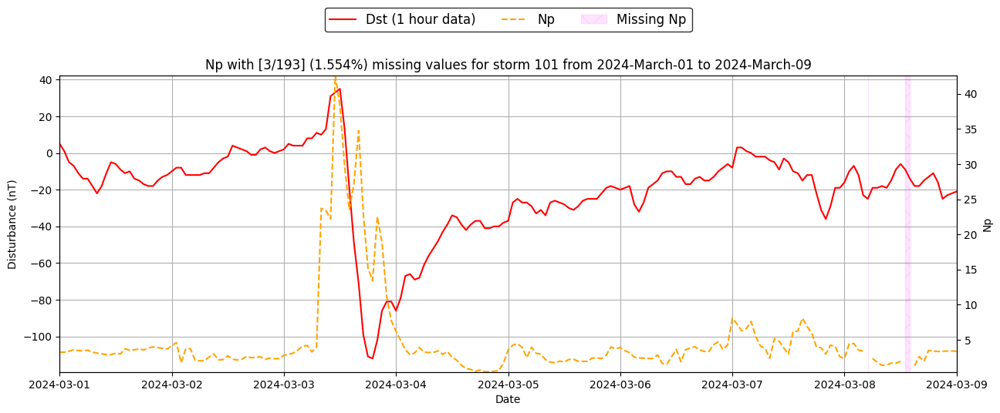

T missing 0 values (0.000%)


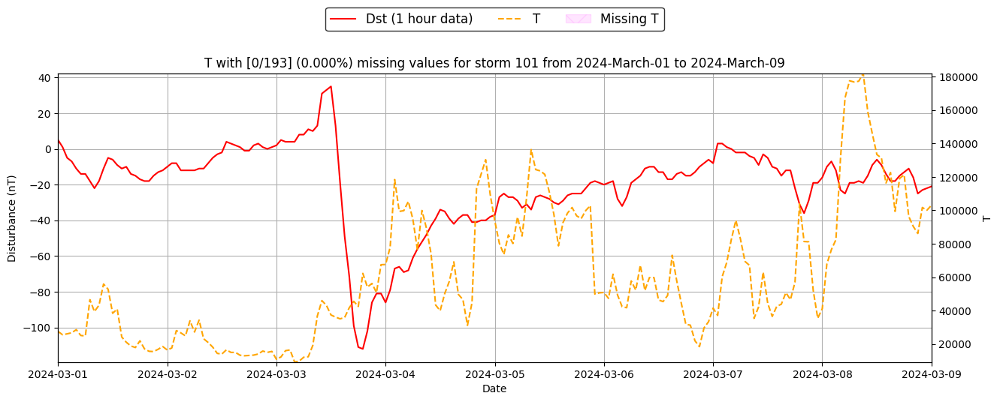

Bmag missing 0 values (0.000%)


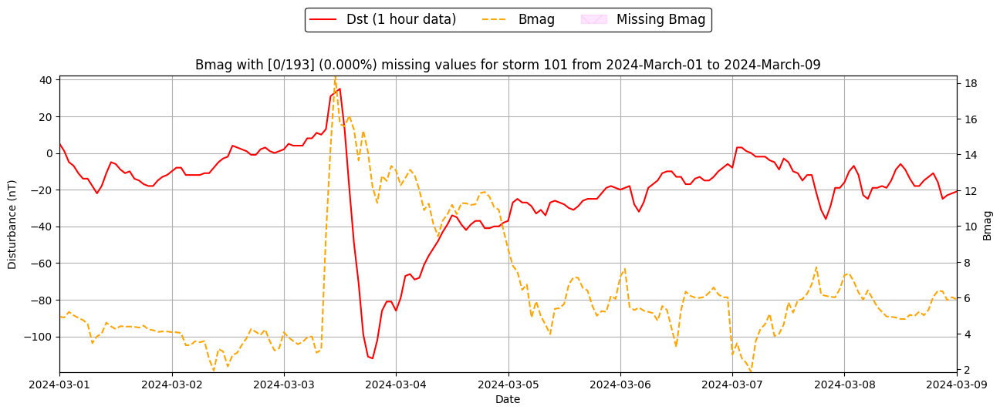

There are ACE missing values in test storm 102 from 2024 March 22 to 2024 March 30
Bz missing 0 values (0.000%)


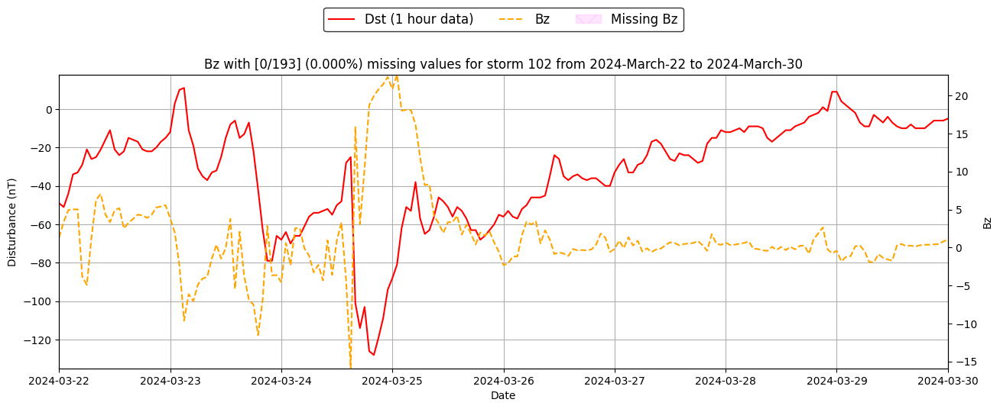

Vp missing 0 values (0.000%)


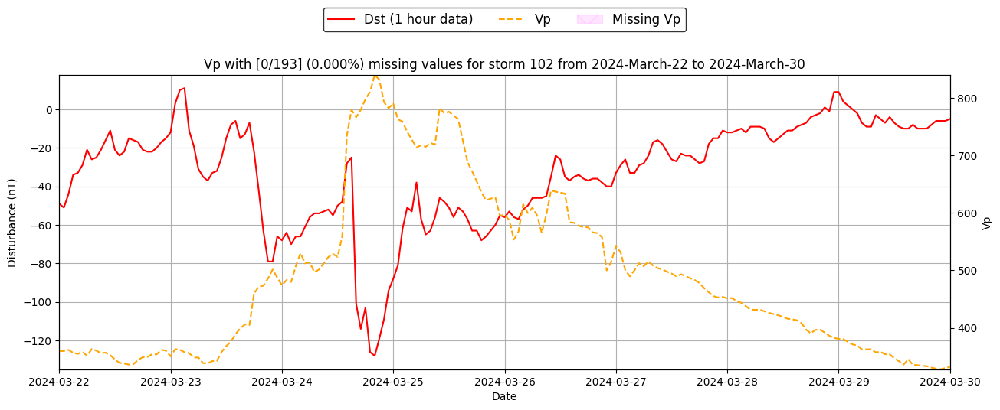

Np missing 6 values (3.109%)


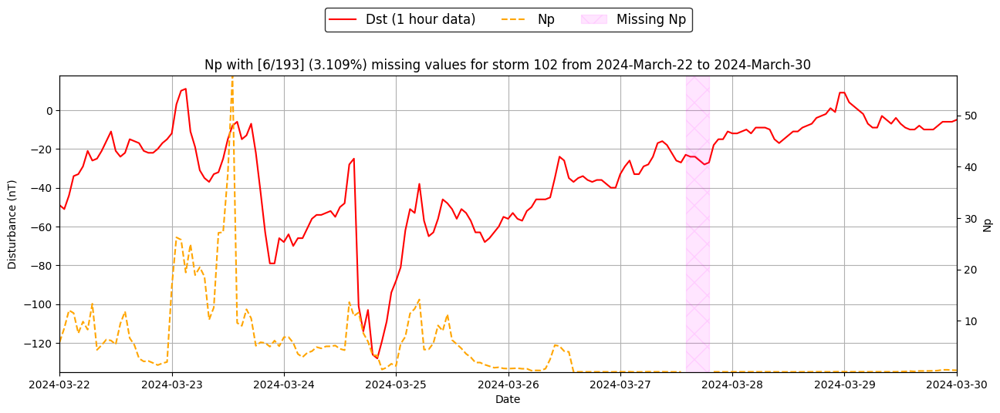

T missing 0 values (0.000%)


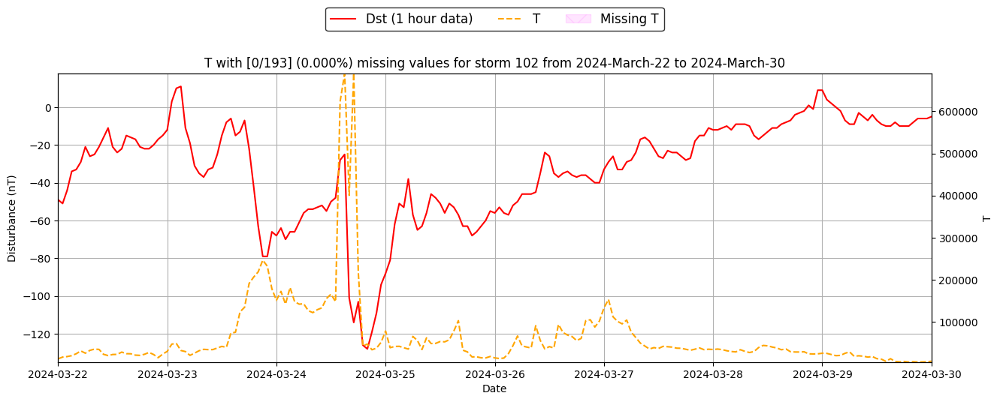

Bmag missing 0 values (0.000%)


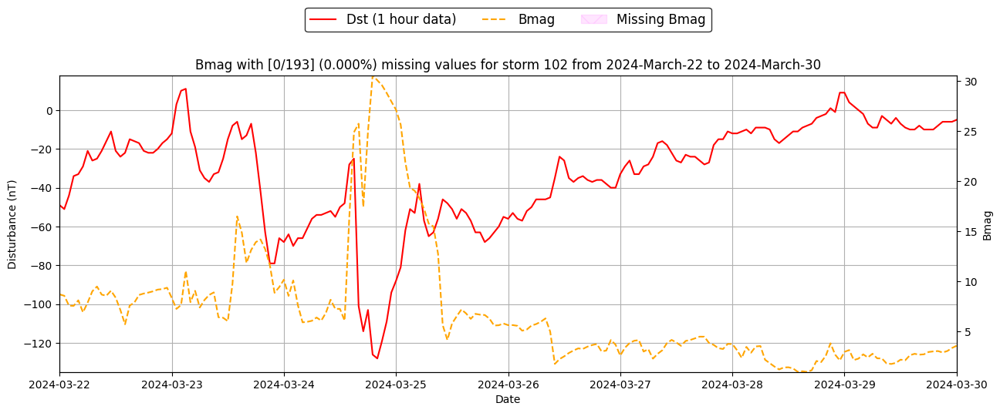

There are ACE missing values in test storm 103 from 2024 April 17 to 2024 April 25
Bz missing 0 values (0.000%)


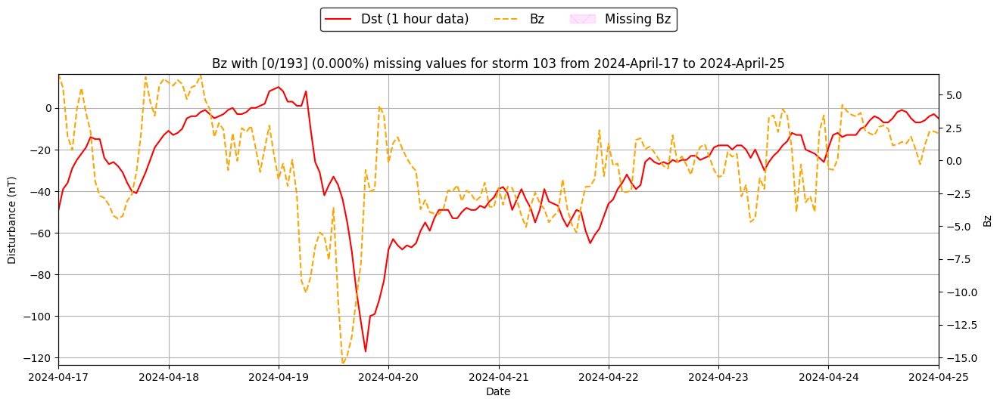

Vp missing 0 values (0.000%)


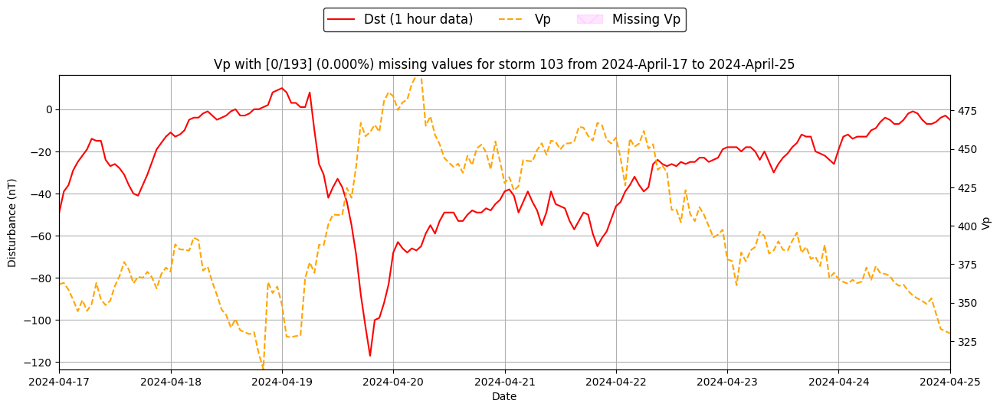

Np missing 1 values (0.518%)


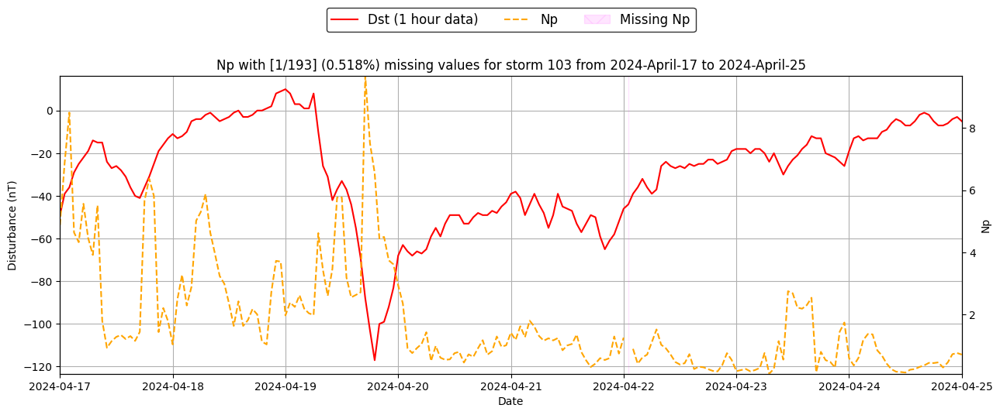

T missing 0 values (0.000%)


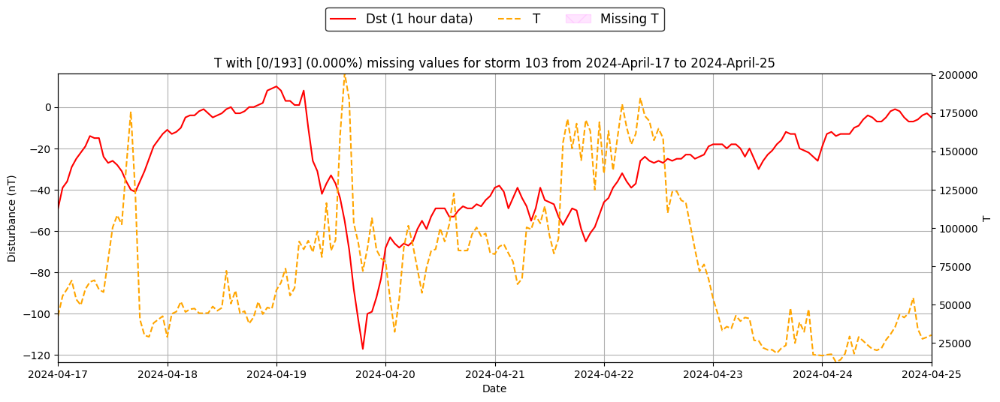

Bmag missing 0 values (0.000%)


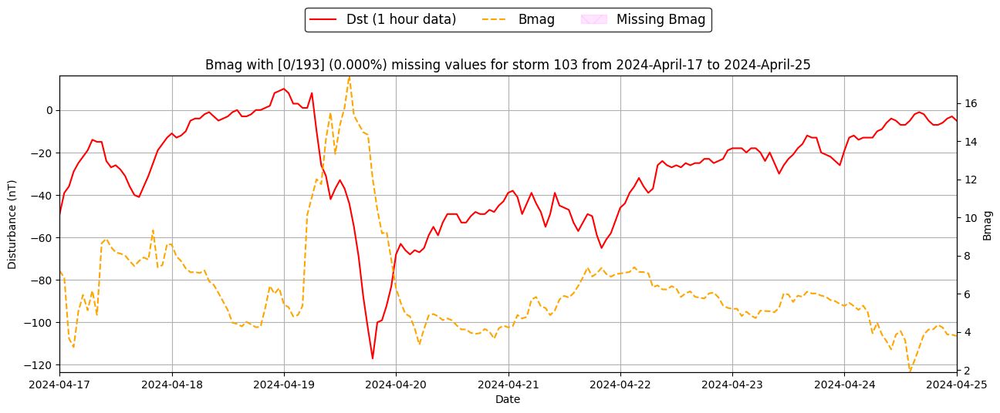

Test storm 104 from 2024 April 30 to 2024 May 24 has no missing values


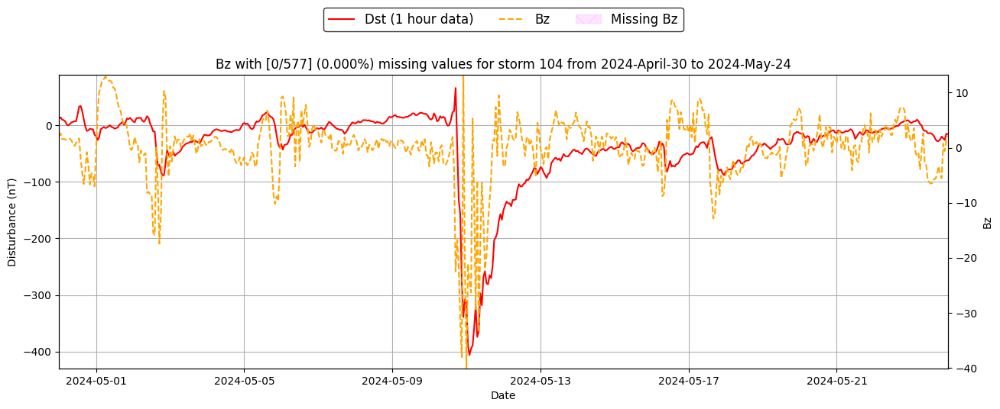

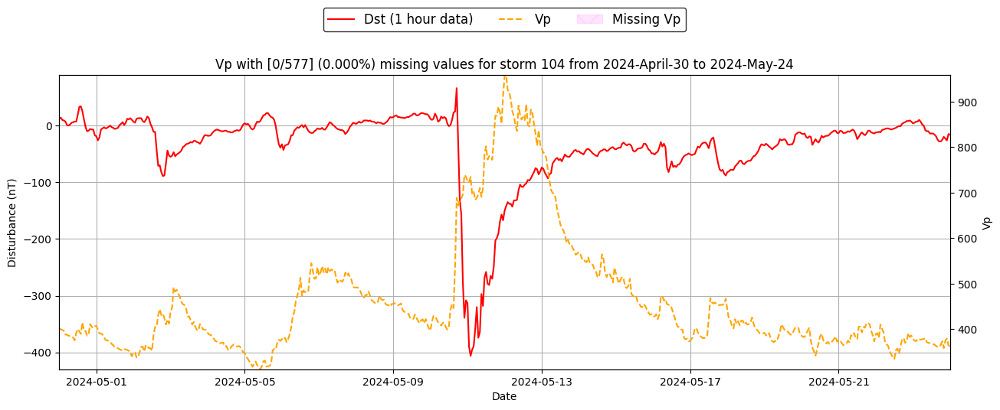

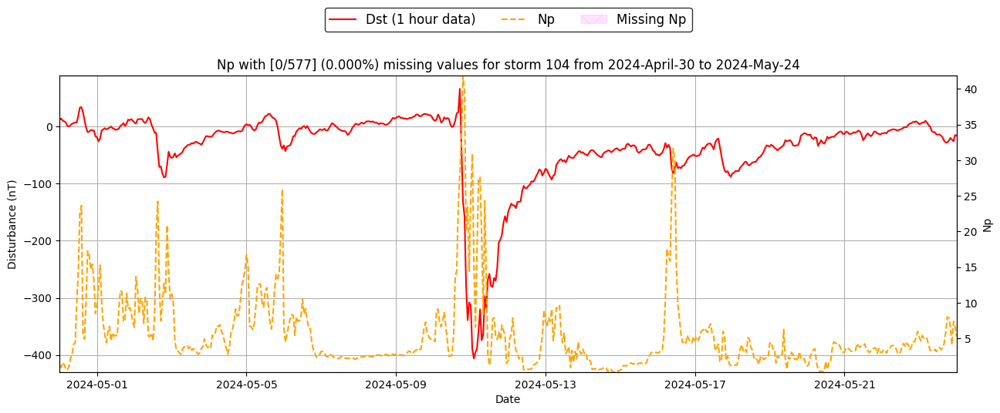

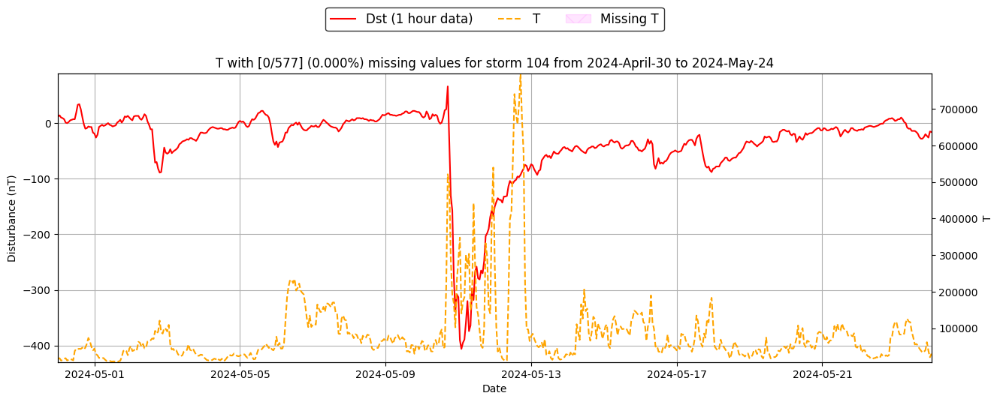

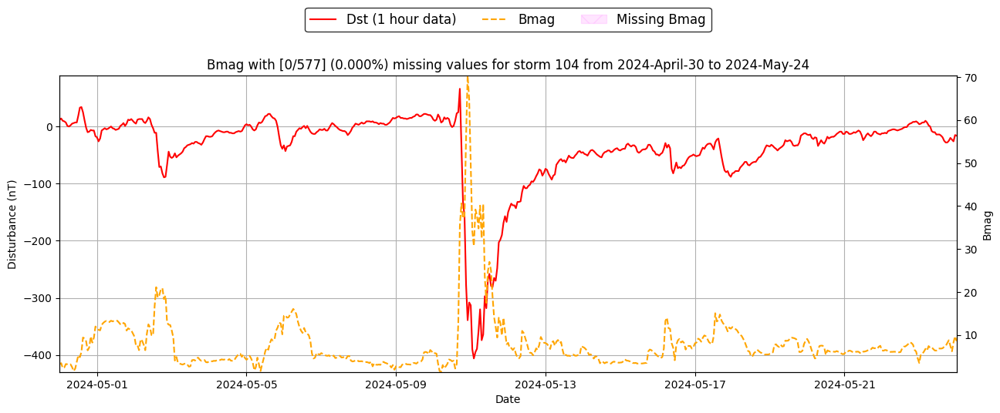

There are ACE missing values in test storm 105 from 2024 June 26 to 2024 July 04
Bz missing 0 values (0.000%)


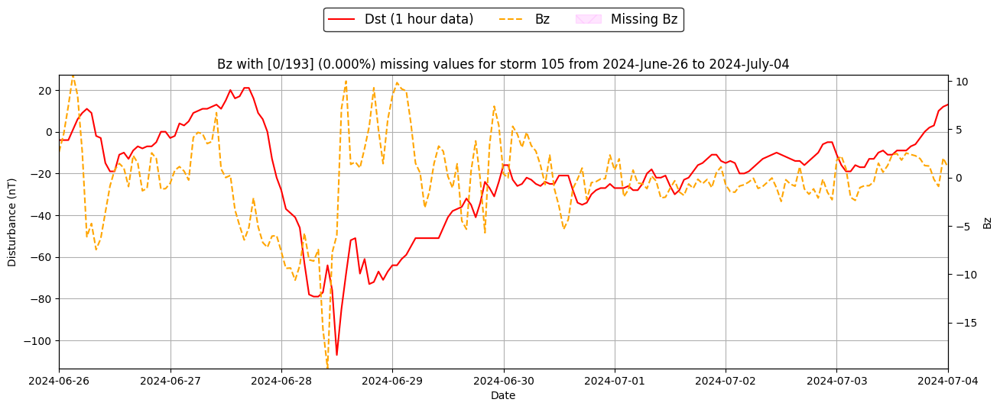

Vp missing 2 values (1.036%)


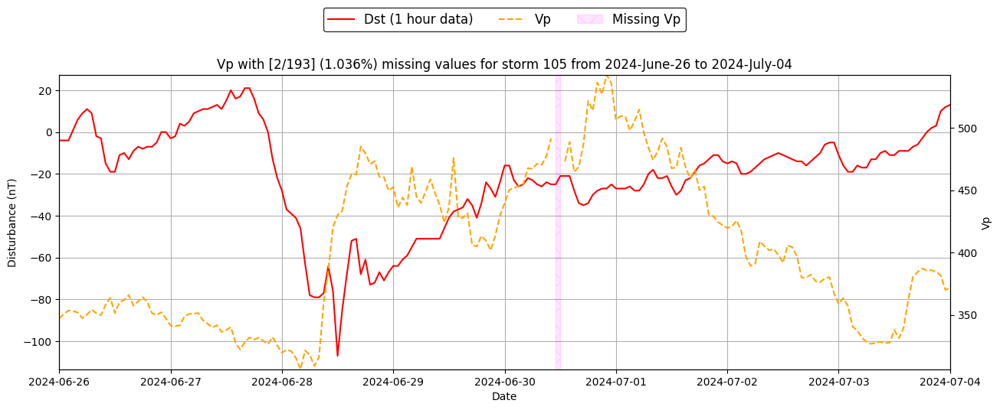

Np missing 2 values (1.036%)


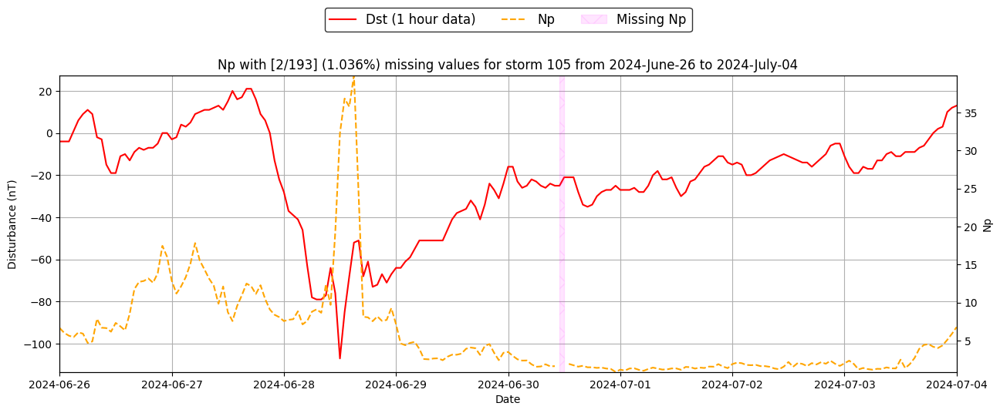

T missing 2 values (1.036%)


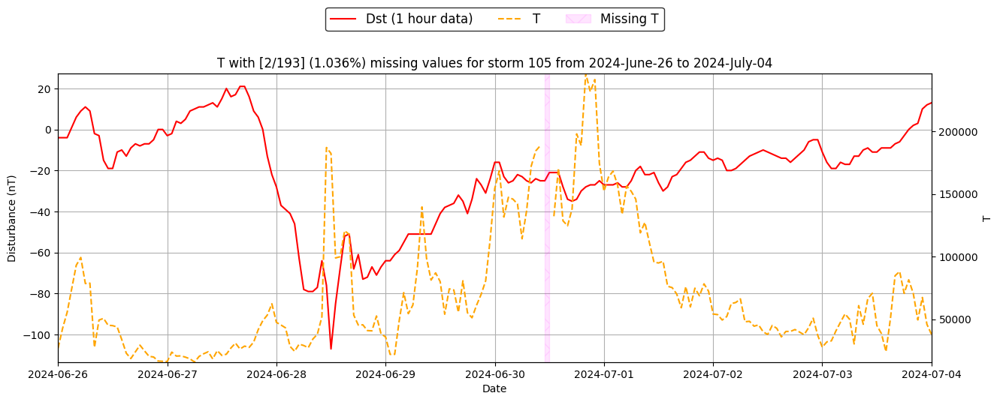

Bmag missing 0 values (0.000%)


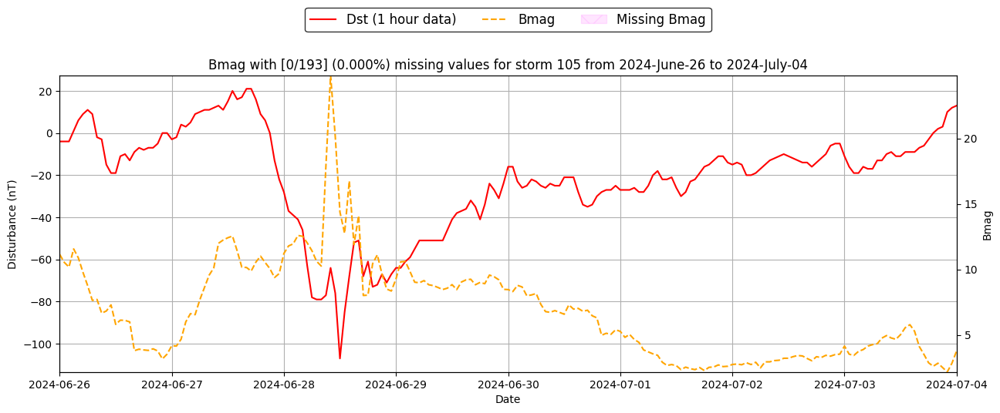

Test storm 106 from 2024 August 02 to 2024 August 19 has no missing values


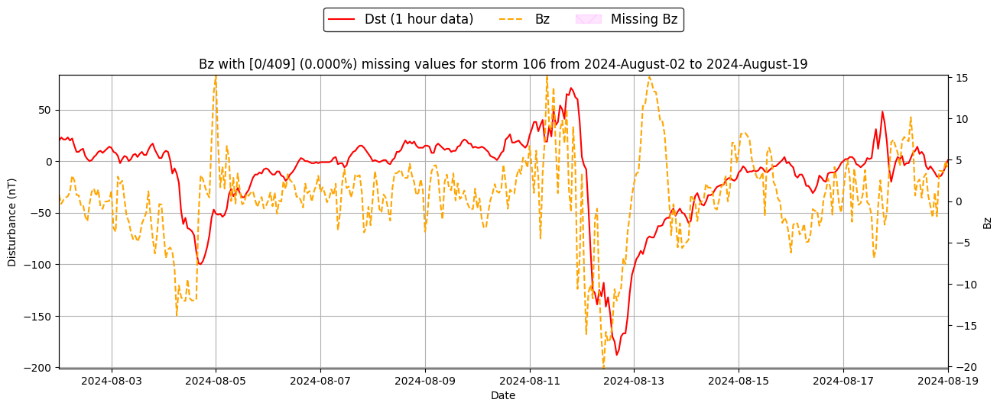

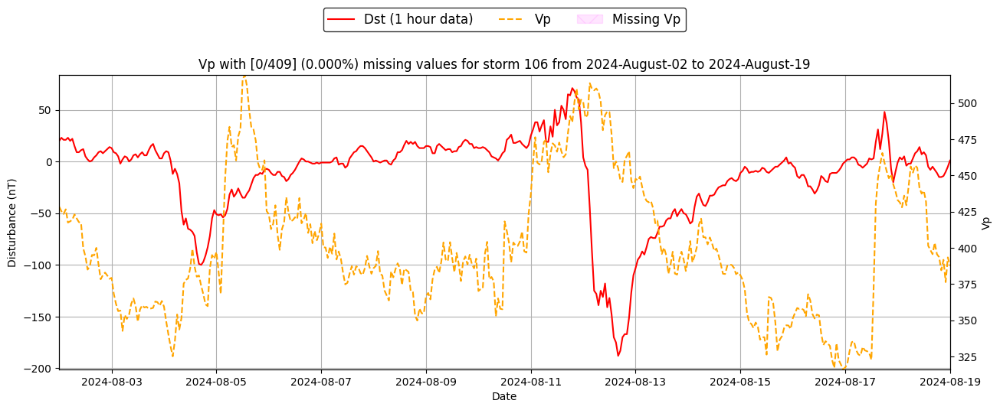

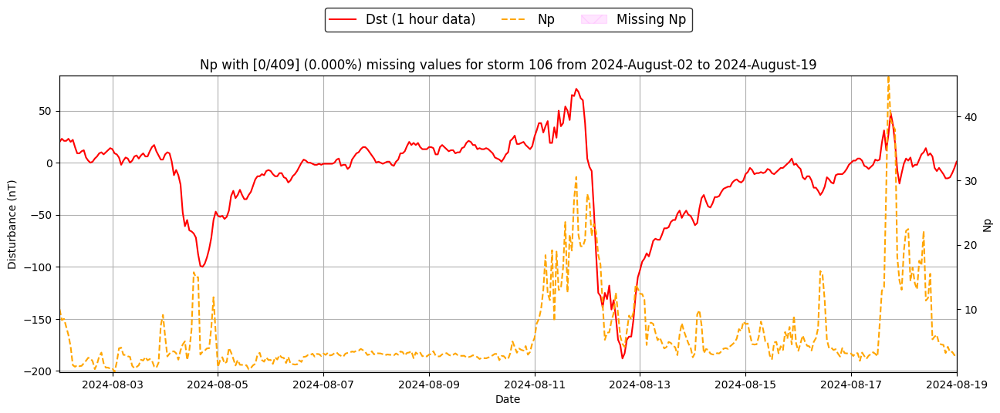

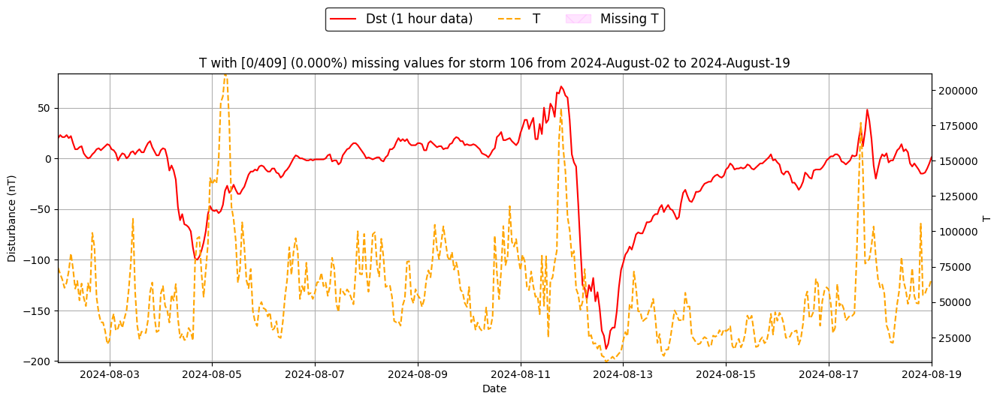

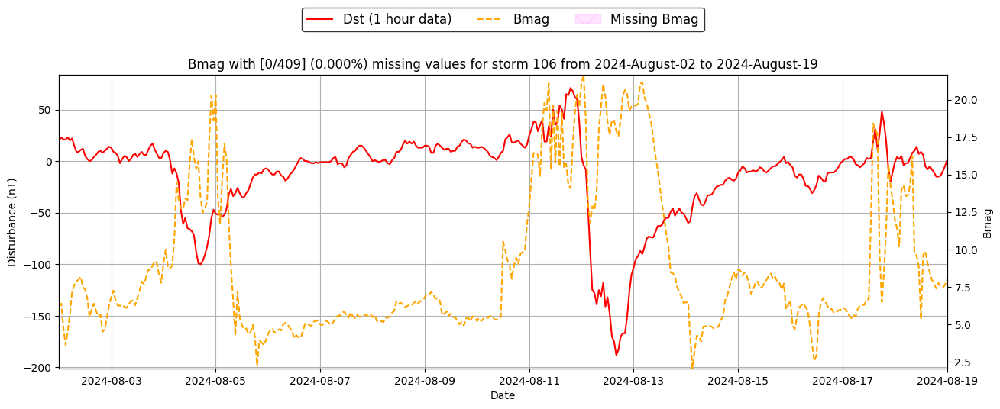

There are ACE missing values in test storm 107 from 2024 September 10 to 2024 September 23
Bz missing 0 values (0.000%)


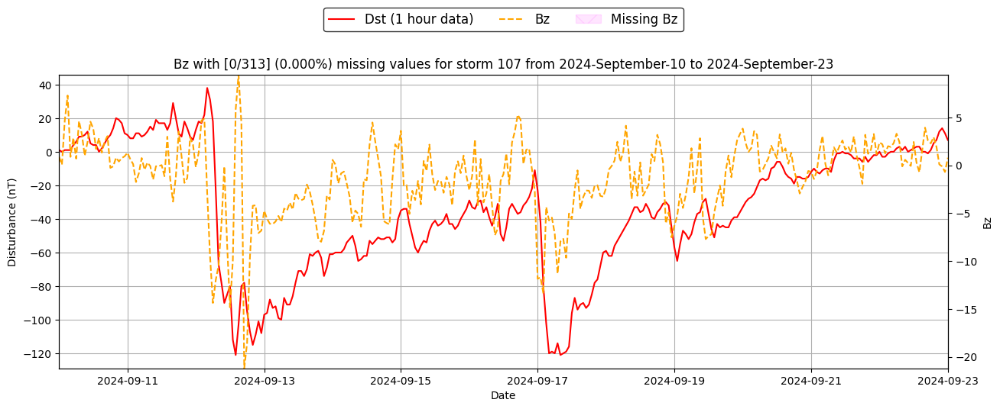

Vp missing 7 values (2.236%)


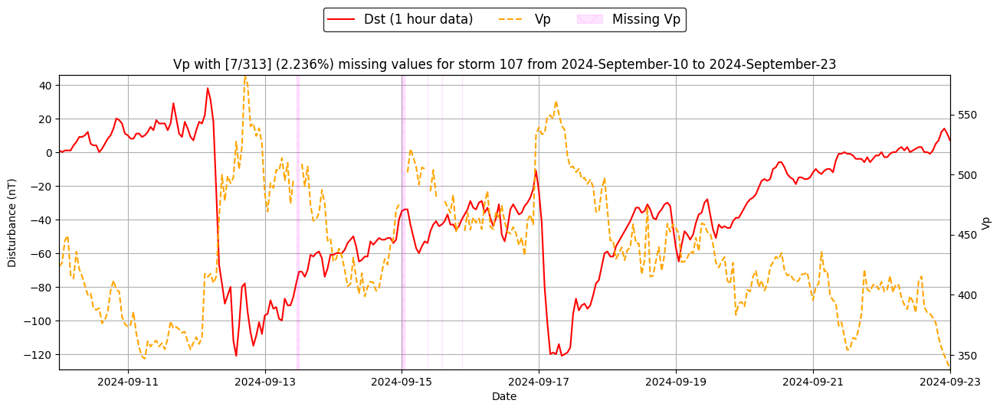

Np missing 7 values (2.236%)


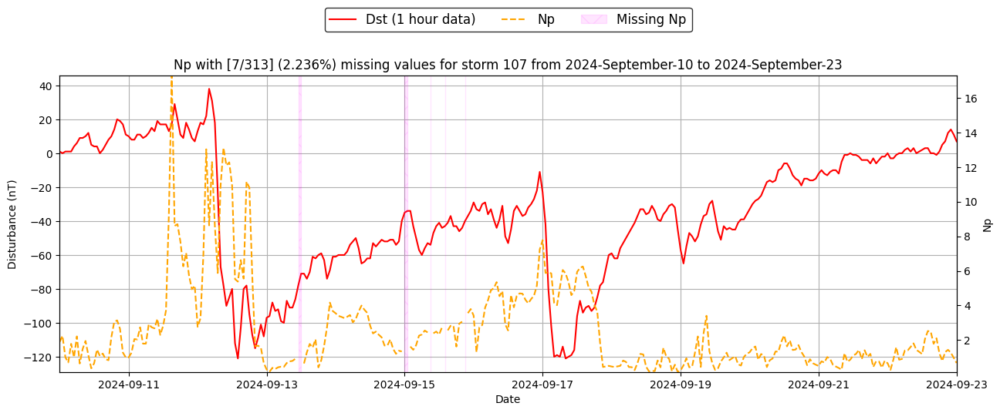

T missing 7 values (2.236%)


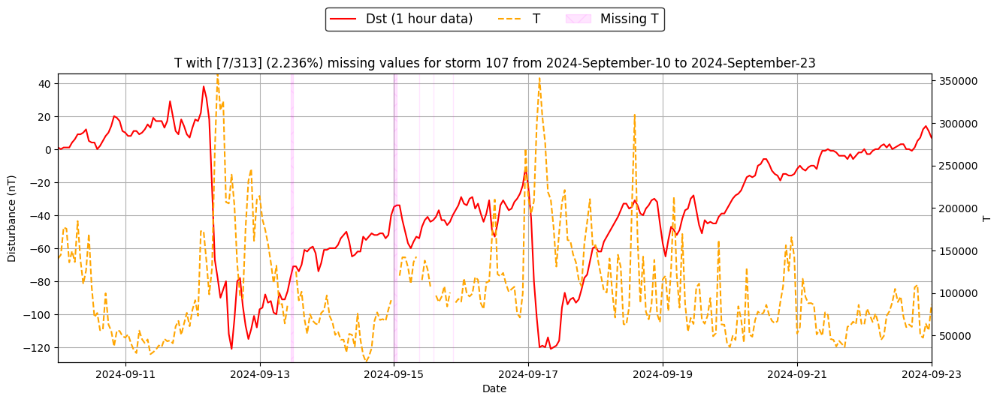

Bmag missing 0 values (0.000%)


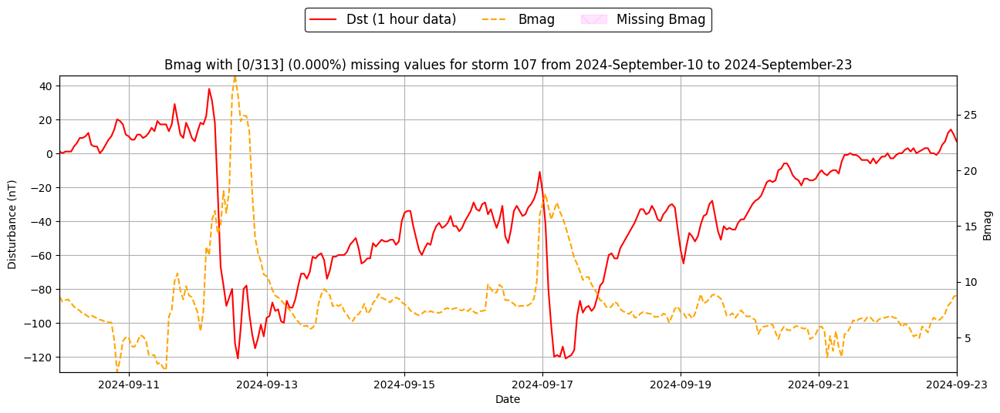

There are ACE missing values in test storm 108 from 2024 October 05 to 2024 October 17
Bz missing 0 values (0.000%)


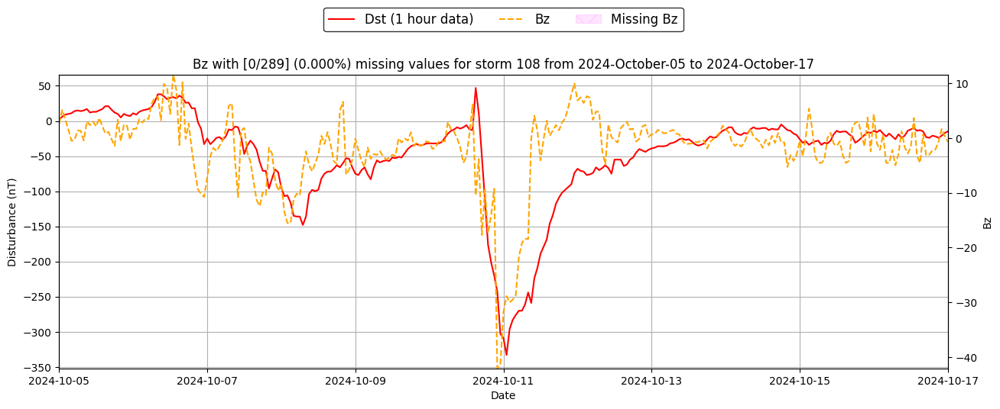

Vp missing 4 values (1.384%)


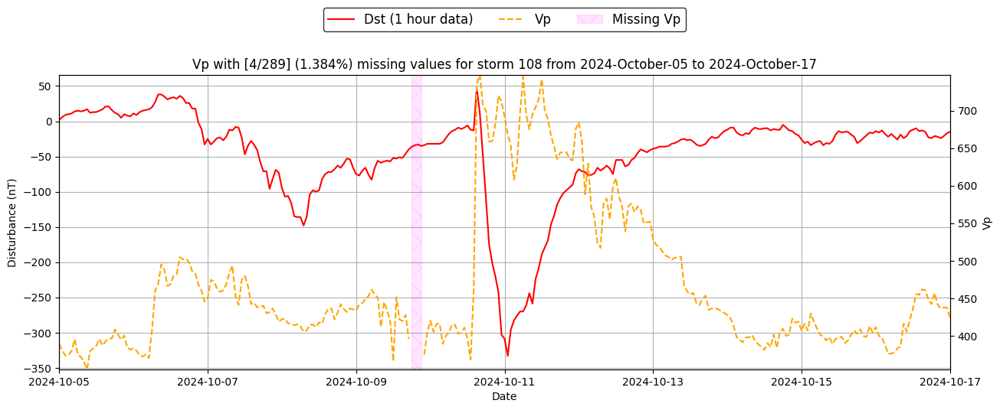

Np missing 0 values (0.000%)


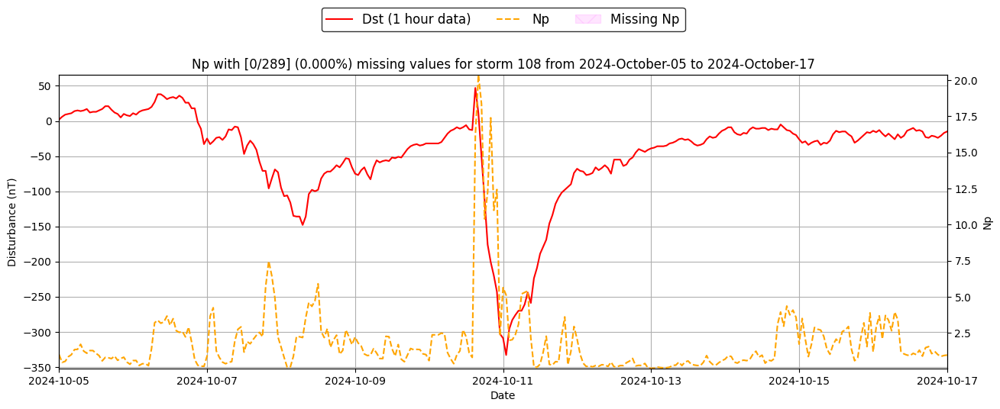

T missing 0 values (0.000%)


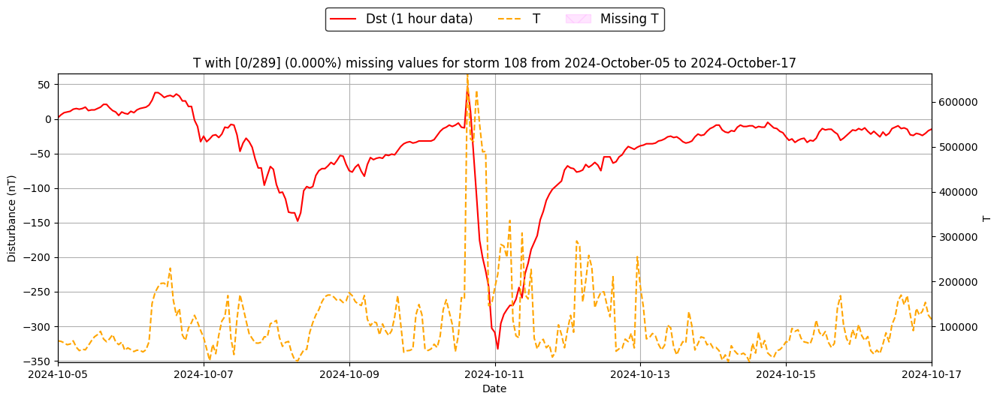

Bmag missing 0 values (0.000%)


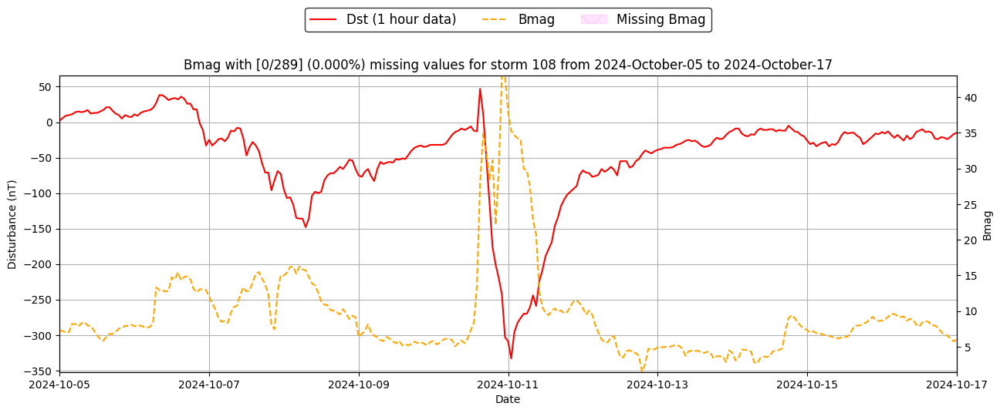

Test storm 109 from 2024 November 07 to 2024 November 15 has no missing values


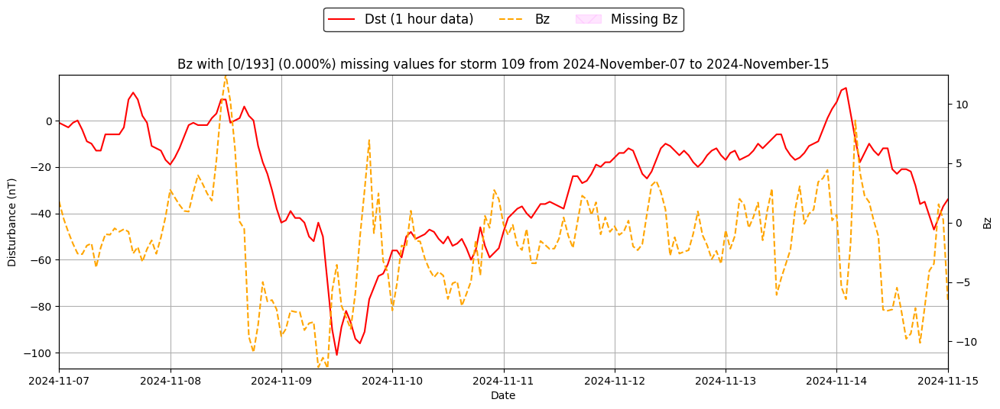

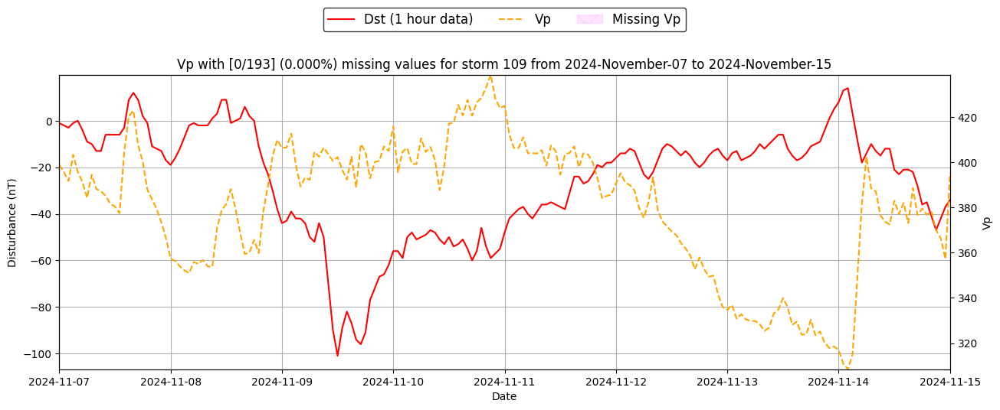

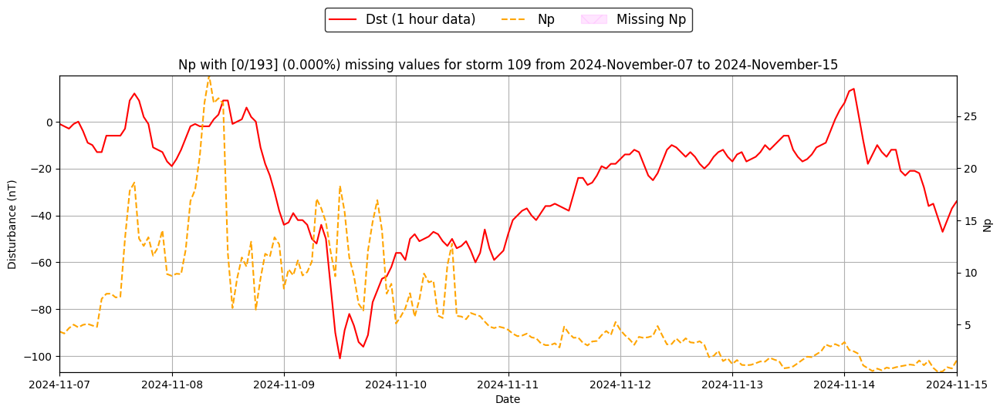

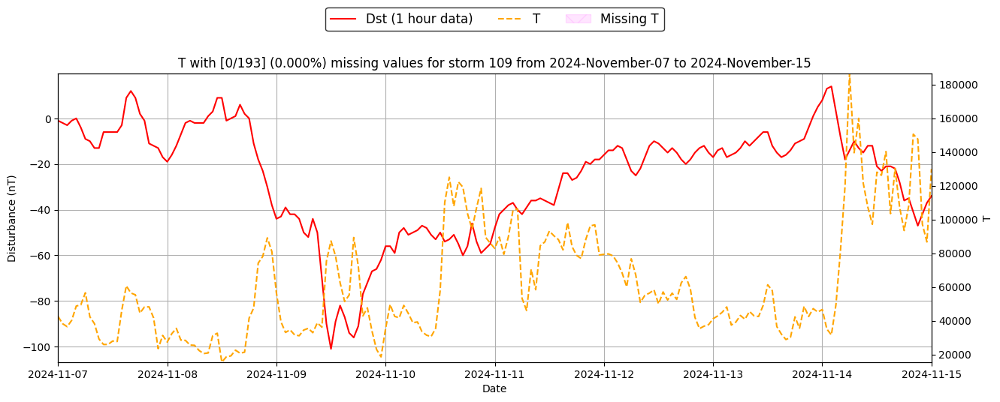

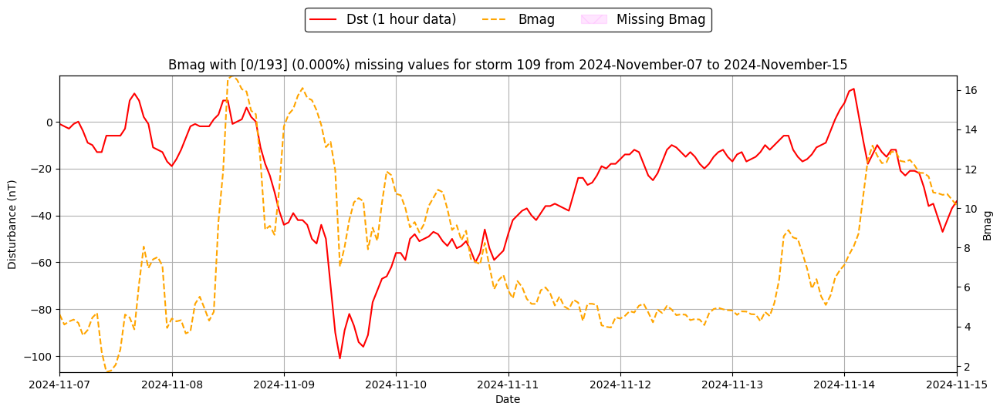

Complete ACE test storms [9/21]


In [ ]:
valid_ace_test_storms = 0
for start_date, end_date, storm_index in storm_dates.TEST_STORMS_SYMBOLIC_REGRESSION:
    sd = pd.to_datetime(start_date)
    ed = pd.to_datetime(end_date)
    storm = ace_data[sd:ed].copy()
    if storm[ace_columns].isna().sum().sum() == 0:
        print(f'Test storm {storm_index} from {sd.strftime("%Y %B %d")} to {ed.strftime("%Y %B %d")} has no missing values')
        valid_ace_test_storms += 1
        
        for col in relevant_columns:            
            plot_storm(dst_kyoto, storm, col, sd, ed, storm_index)
        
    else:
        print(f'There are ACE missing values in test storm {storm_index} from {sd.strftime("%Y %B %d")} to {ed.strftime("%Y %B %d")}')
        for col in relevant_columns:            
            print(f'{col} missing {storm[col].isna().sum()} values ({storm[col].isna().sum() / len(storm[col]) * 100:.3f}%)')
            plot_storm(dst_kyoto, storm, col, sd, ed, storm_index)
            
        #col = storm[ace_columns].isna().sum().sort_values(ascending=False).index[0]
        #plot_storm(dst_kyoto, storm, col, sd, ed, storm_index)
        
print(f'Complete ACE test storms [{valid_ace_test_storms}/{len(storm_dates.TEST_STORMS_SYMBOLIC_REGRESSION)}]')

# Now plotting the incomplete storms after the cleanup

There are ACE missing values in Train storm 2 from 1998 May 02 to 1998 May 11
T missing 14 values (6.452%)


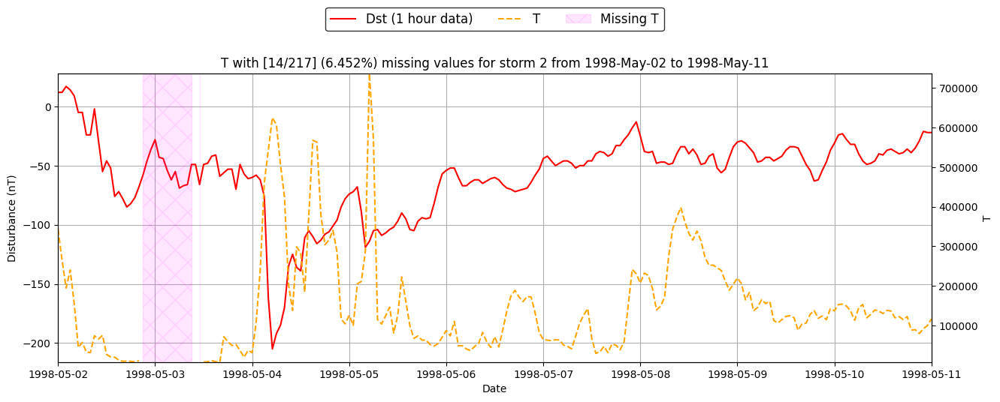

Train storm 3 from 1998 June 24 to 1998 June 30 has no missing values
Train storm 4 from 1998 August 04 to 1998 August 13 has no missing values
Train storm 5 from 1998 August 25 to 1998 September 02 has no missing values
Train storm 6 from 1998 September 23 to 1998 October 01 has no missing values
There are ACE missing values in Train storm 7 from 1998 October 17 to 1998 October 25
T missing 2 values (1.036%)


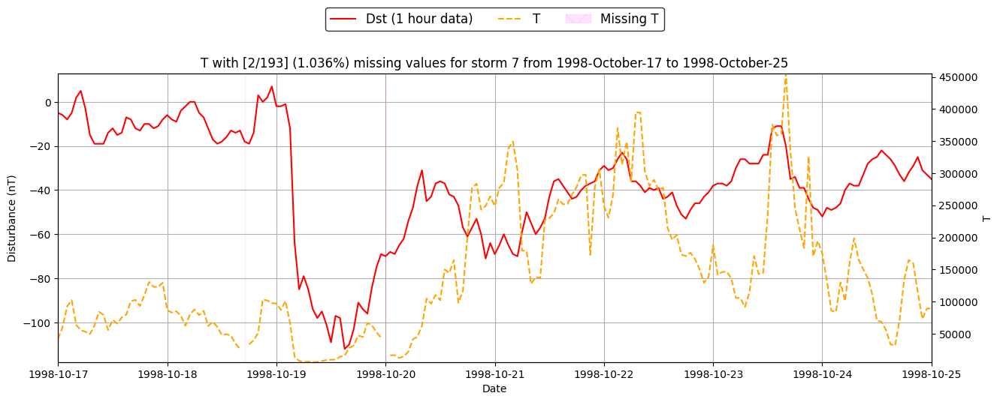

There are ACE missing values in Train storm 8 from 1999 January 11 to 1999 January 20
T missing 1 values (0.461%)


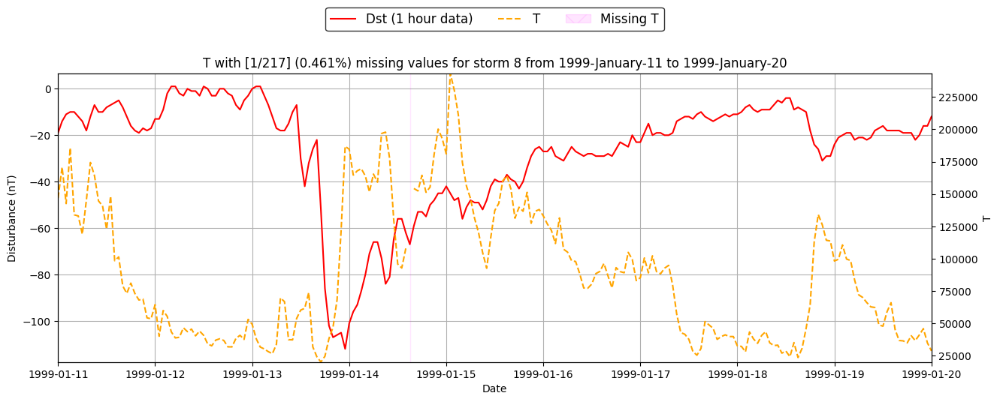

Train storm 9 from 1999 February 16 to 1999 February 25 has no missing values
There are ACE missing values in Train storm 10 from 1999 February 27 to 1999 March 07
T missing 4 values (2.073%)


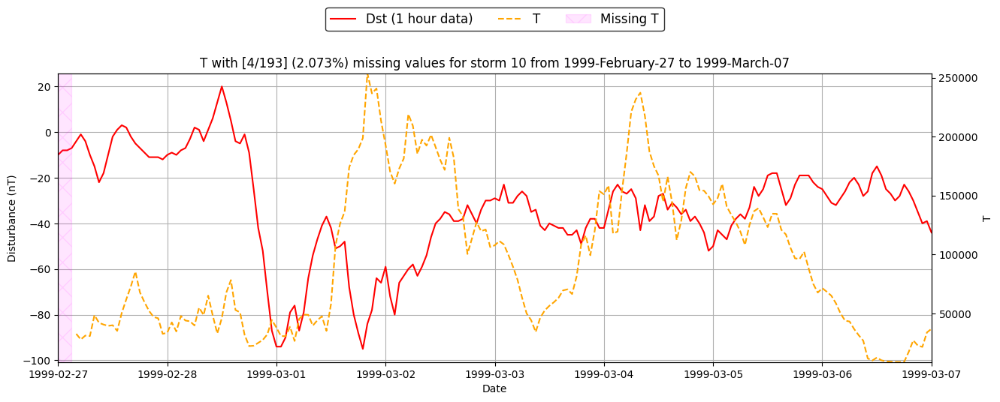

Train storm 11 from 1999 April 15 to 1999 April 23 has no missing values
Train storm 12 from 1999 September 20 to 1999 September 29 has no missing values
Train storm 13 from 2000 February 10 to 2000 February 16 has no missing values
Train storm 14 from 2000 May 15 to 2000 May 30 has no missing values
Train storm 15 from 2000 June 06 to 2000 June 14 has no missing values
Train storm 17 from 2000 August 09 to 2000 August 16 has no missing values
There are ACE missing values in Train storm 18 from 2000 September 15 to 2000 September 24
T missing 4 values (1.843%)


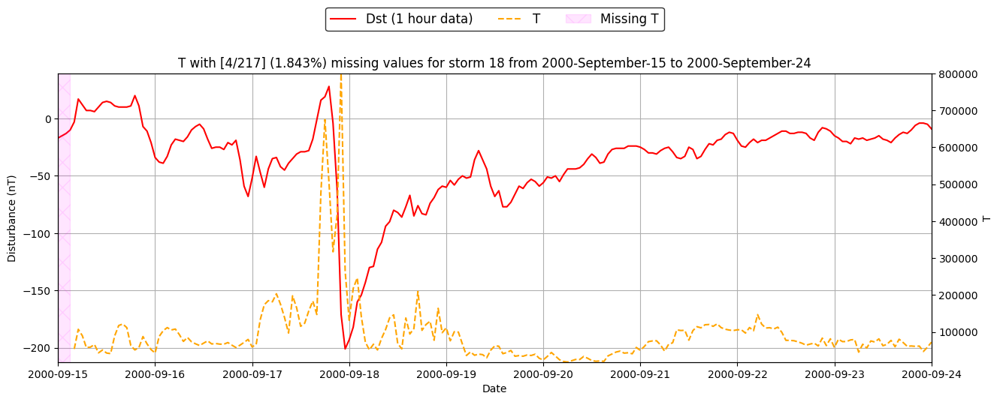

Train storm 19 from 2000 October 02 to 2000 October 07 has no missing values
Train storm 21 from 2000 November 27 to 2000 December 05 has no missing values
There are ACE missing values in Train storm 23 from 2001 April 09 to 2001 April 28
T missing 16 values (3.501%)


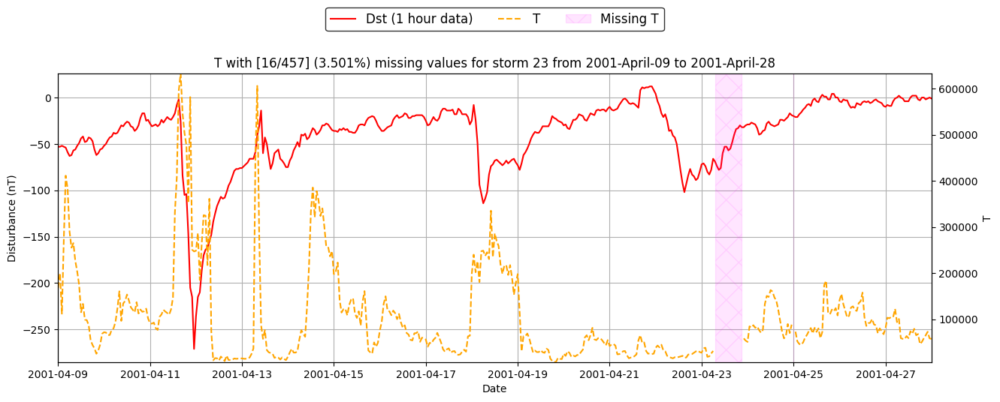

Train storm 24 from 2001 August 15 to 2001 August 23 has no missing values
Train storm 25 from 2001 September 29 to 2001 October 07 has no missing values
There are ACE missing values in Train storm 26 from 2001 October 19 to 2001 November 01
T missing 20 values (6.390%)


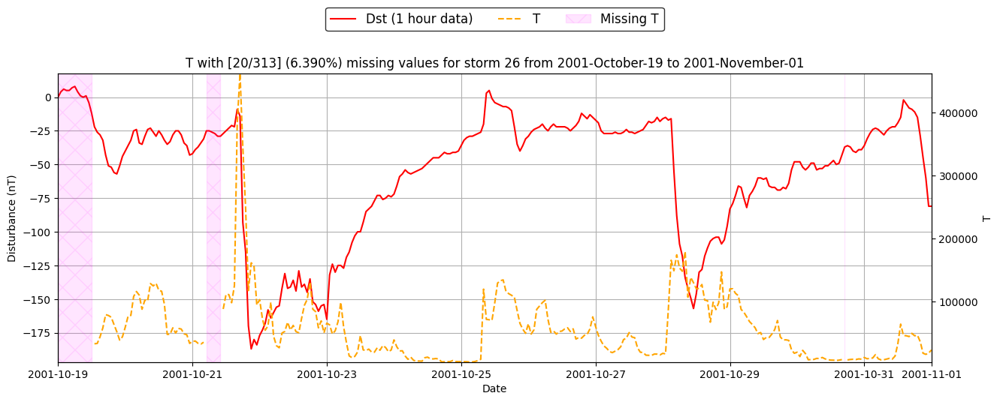

There are ACE missing values in Train storm 28 from 2002 March 22 to 2002 March 29
T missing 4 values (2.367%)


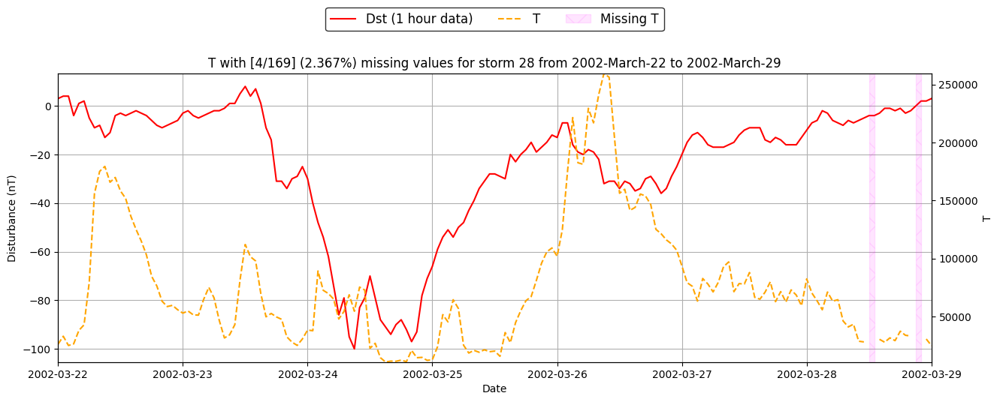

Train storm 30 from 2002 May 21 to 2002 May 29 has no missing values
There are ACE missing values in Train storm 31 from 2002 July 31 to 2002 August 07
T missing 2 values (1.183%)


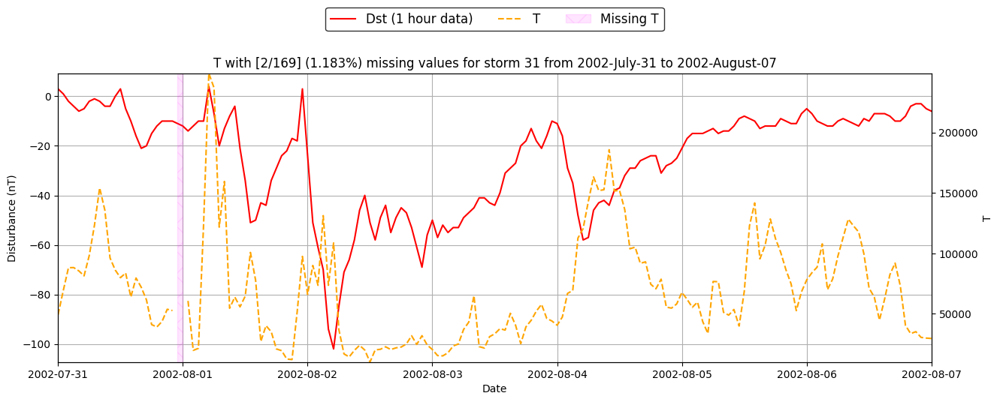

Train storm 34 from 2002 October 22 to 2002 October 31 has no missing values
Train storm 35 from 2002 November 19 to 2002 November 27 has no missing values
Train storm 36 from 2003 May 27 to 2003 June 08 has no missing values
There are ACE missing values in Train storm 37 from 2003 July 10 to 2003 July 22
T missing 3 values (1.038%)


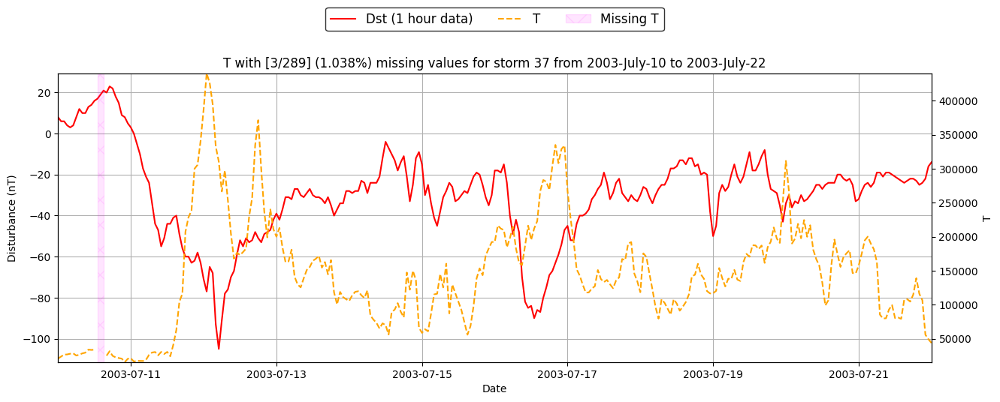

Train storm 38 from 2003 August 16 to 2003 August 25 has no missing values
There are ACE missing values in Train storm 40 from 2003 November 18 to 2003 November 27
T missing 1 values (0.461%)


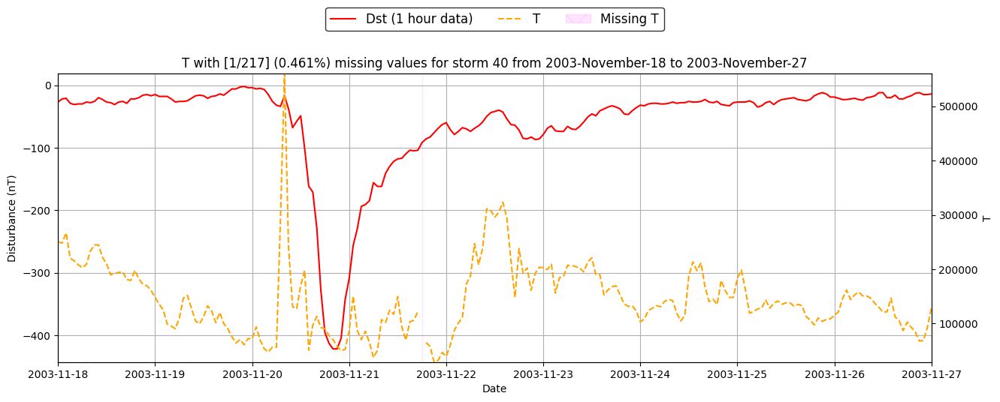

Train storm 41 from 2004 January 20 to 2004 January 28 has no missing values
Train storm 42 from 2004 February 09 to 2004 February 17 has no missing values
Train storm 43 from 2004 April 01 to 2004 April 10 has no missing values
There are ACE missing values in Train storm 44 from 2004 July 21 to 2004 August 02
Np missing 7 values (2.422%)


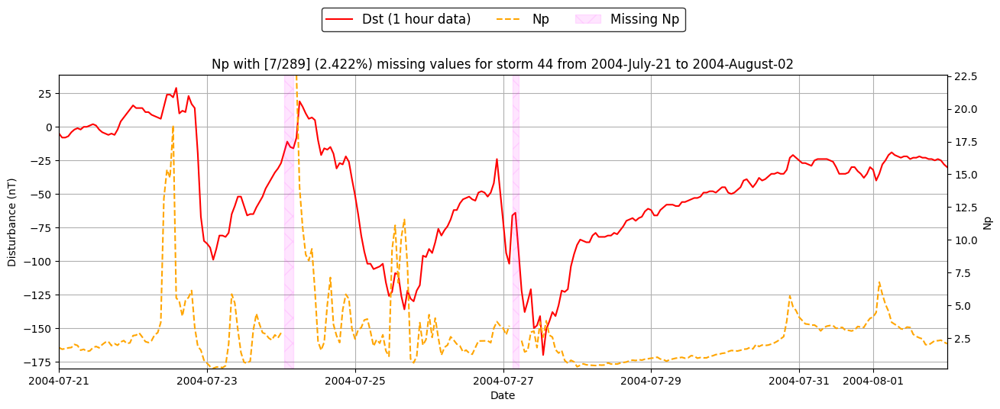

Train storm 45 from 2004 August 28 to 2004 September 03 has no missing values
There are ACE missing values in Train storm 46 from 2004 November 06 to 2004 November 18
T missing 10 values (3.460%)


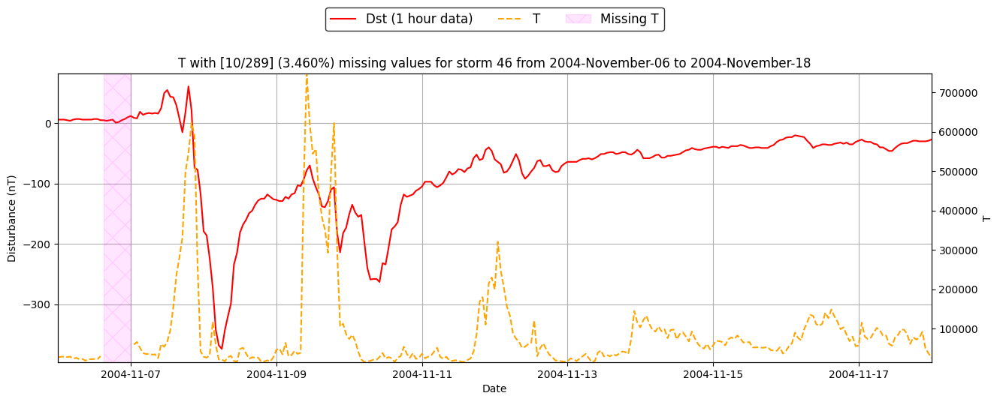

There are ACE missing values in Train storm 47 from 2005 January 06 to 2005 January 14
Np missing 6 values (3.109%)


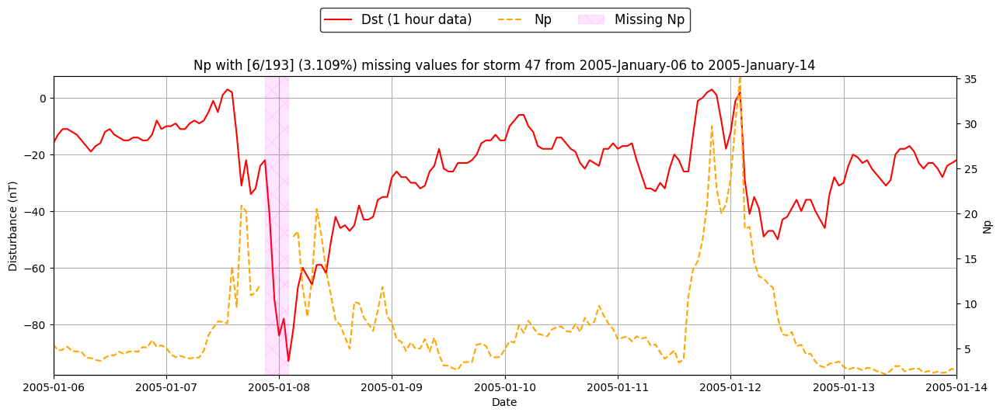

Train storm 48 from 2005 May 06 to 2005 May 22 has no missing values
There are ACE missing values in Train storm 49 from 2005 May 28 to 2005 June 05
T missing 6 values (3.109%)


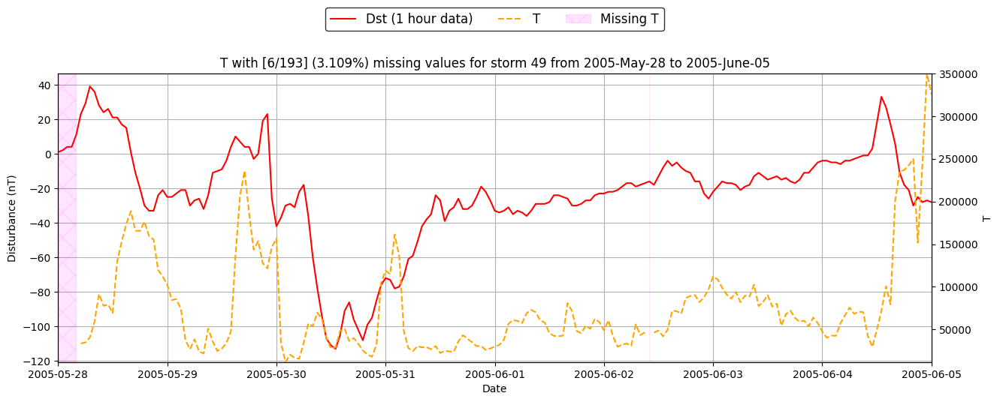

There are ACE missing values in Train storm 51 from 2005 August 22 to 2005 September 06
Np missing 22 values (6.094%)


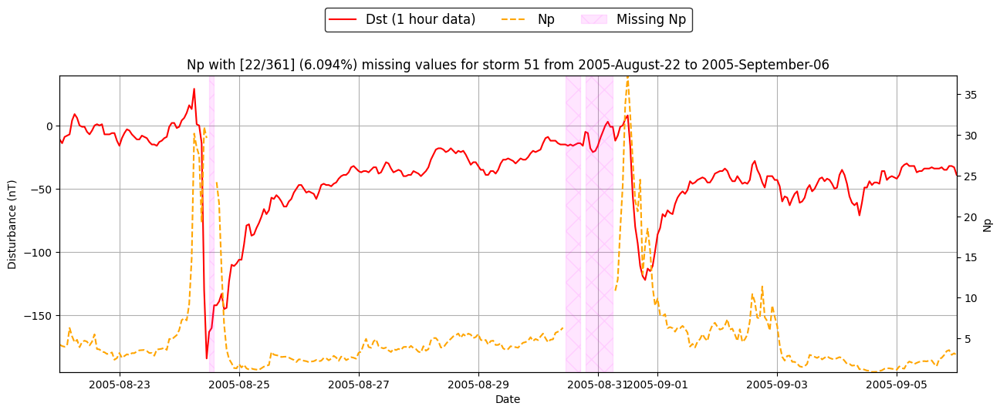

There are ACE missing values in Train storm 52 from 2006 April 12 to 2006 April 20
Np missing 5 values (2.591%)


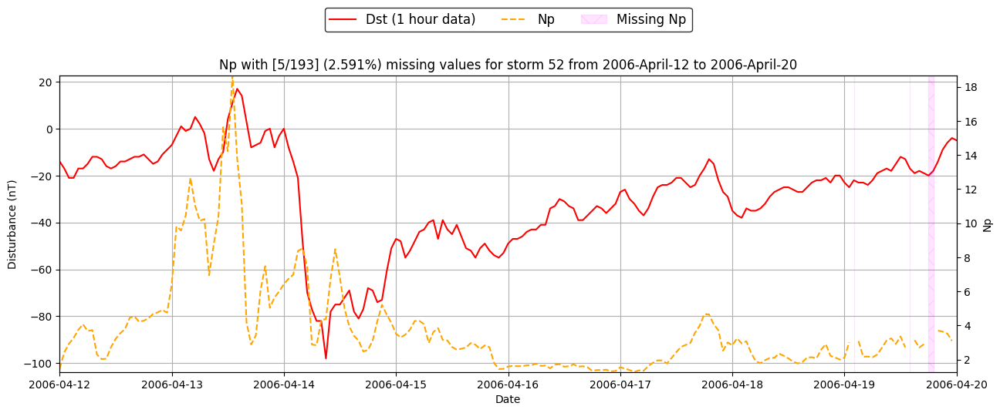

There are ACE missing values in Train storm 53 from 2006 December 14 to 2006 December 21
T missing 2 values (1.183%)


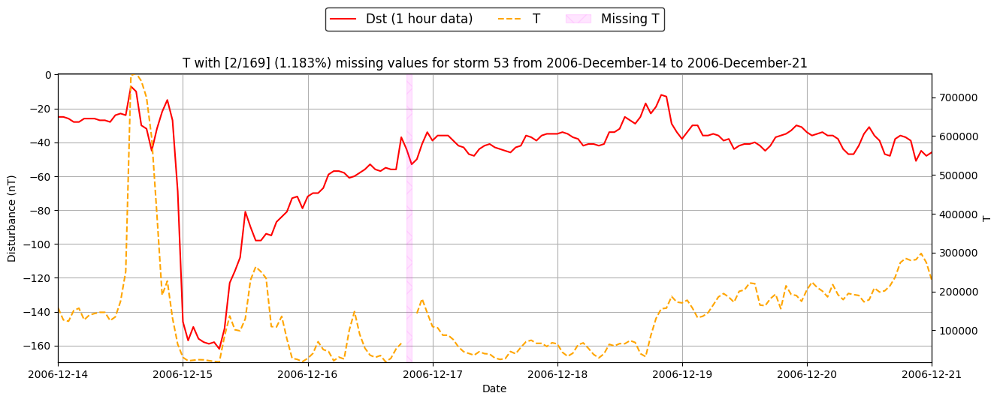

There are ACE missing values in Train storm 60 from 2013 May 30 to 2013 June 07
Np missing 4 values (2.073%)


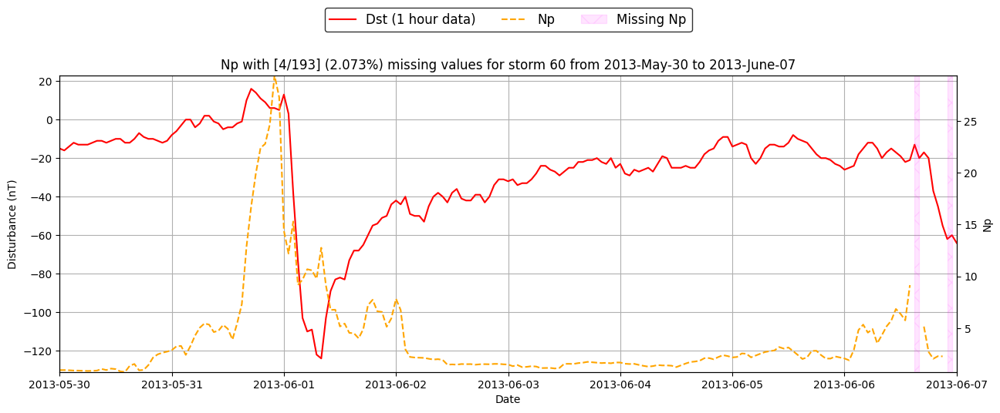

There are ACE missing values in Train storm 69 from 2016 October 11 to 2016 October 20
Np missing 12 values (5.530%)


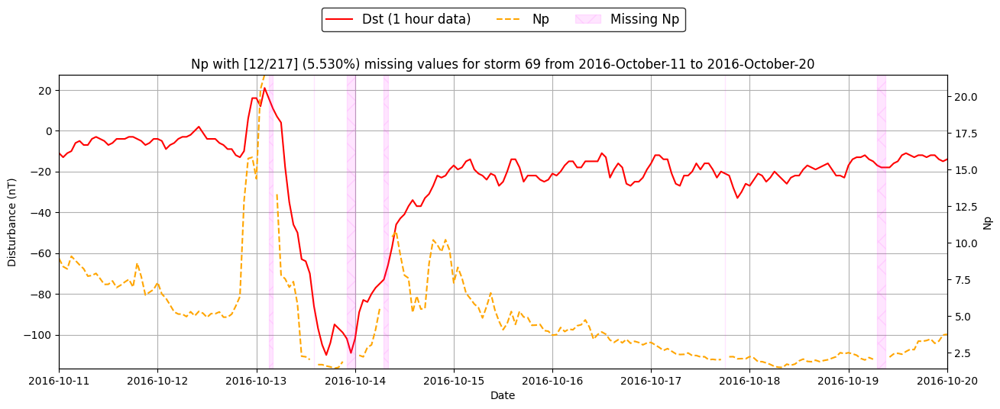

Complete ACE train storms [25/45]


In [ ]:
PLOT_COMPLETE_STORMS = False
PLOT_INCOMPLETE_STORMS = True

valid_ace_train_storms = 0
for start_date, end_date, storm_index in storm_dates.TRAIN_STORMS_SYMBOLIC_REGRESSION:
    sd = pd.to_datetime(start_date)
    ed = pd.to_datetime(end_date)
    storm = ace_data[sd:ed].copy()
    if storm[ace_columns].isna().sum().sum() == 0:
        print(f'Train storm {storm_index} from {sd.strftime("%Y %B %d")} to {ed.strftime("%Y %B %d")} has no missing values')
        valid_ace_train_storms += 1
        if not PLOT_COMPLETE_STORMS:
            continue
            
        plot_storm(dst_kyoto, storm, None, sd, ed, storm_index)
        
    else:
        print(f'There are ACE missing values in Train storm {storm_index} from {sd.strftime("%Y %B %d")} to {ed.strftime("%Y %B %d")}')
        if not PLOT_INCOMPLETE_STORMS:
            continue
            
        col = storm[ace_columns].isna().sum().sort_values(ascending=False).index[0]
        print(f'{col} missing {storm[col].isna().sum()} values ({storm[col].isna().sum() / len(storm[col]) * 100:.3f}%)')
        plot_storm(dst_kyoto, storm, col, sd, ed, storm_index)
        
    
print(f'Complete ACE train storms [{valid_ace_train_storms}/{len(storm_dates.TRAIN_STORMS_SYMBOLIC_REGRESSION)}]')

Test storm 90 from 2017 September 26 to 2017 October 04 has no missing values
Test storm 91 from 2018 August 24 to 2018 September 01 has no missing values
There are ACE missing values in test storm 92 from 2021 November 02 to 2021 November 10
Np missing 4 values (2.073%)


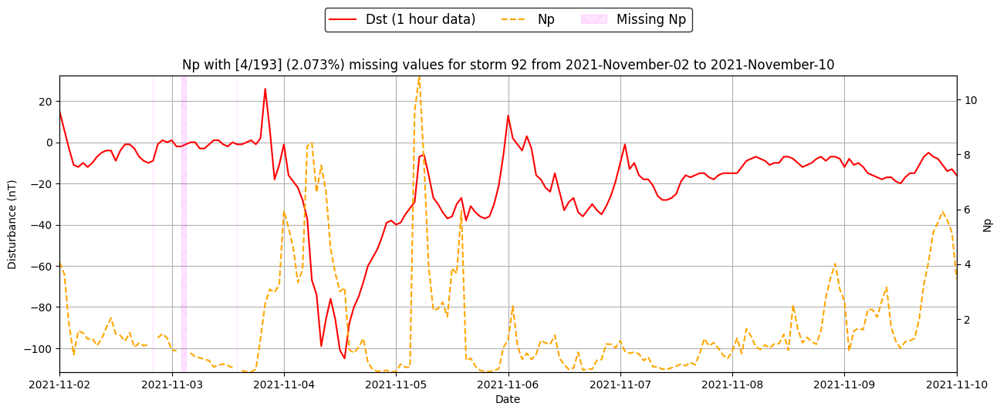

Test storm 93 from 2022 January 12 to 2022 January 20 has no missing values
Test storm 94 from 2022 November 05 to 2022 November 13 has no missing values
Test storm 95 from 2023 February 25 to 2023 March 06 has no missing values
There are ACE missing values in test storm 96 from 2023 March 21 to 2023 March 30
Np missing 4 values (1.843%)


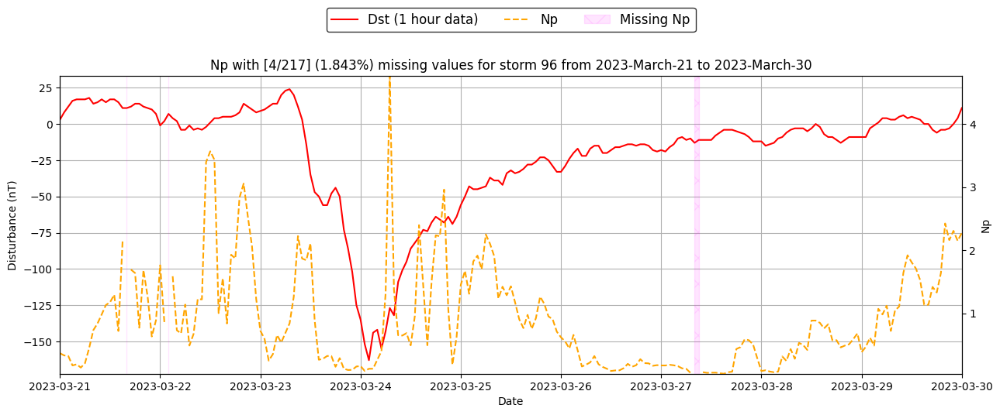

There are ACE missing values in test storm 97 from 2023 April 21 to 2023 April 30
Np missing 1 values (0.461%)


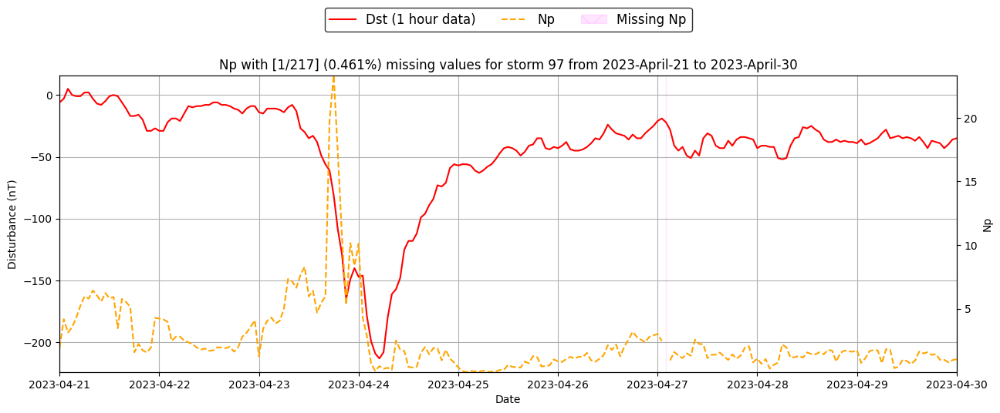

Test storm 98 from 2023 August 03 to 2023 August 11 has no missing values
There are ACE missing values in test storm 99 from 2023 November 03 to 2023 November 12
Np missing 1 values (0.461%)


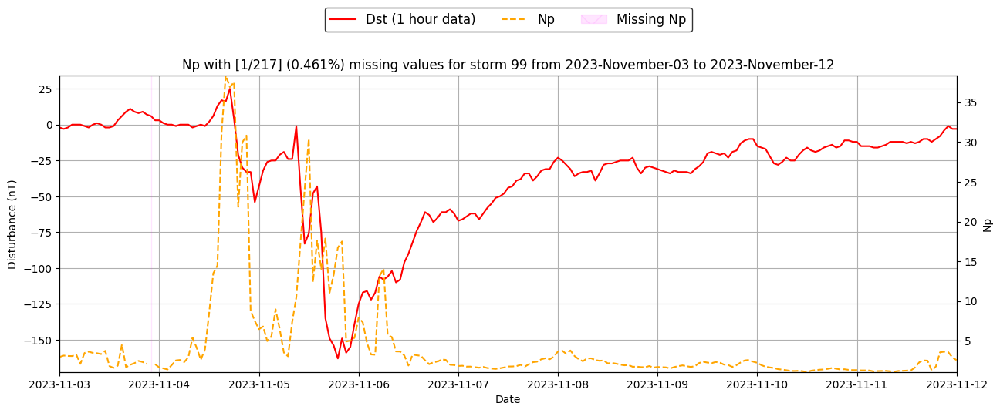

There are ACE missing values in test storm 100 from 2023 November 23 to 2023 December 08
Np missing 1 values (0.277%)


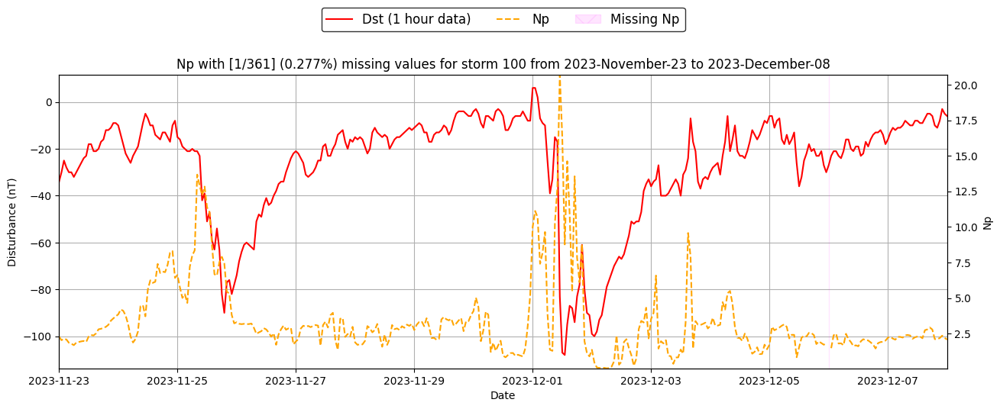

There are ACE missing values in test storm 101 from 2024 March 01 to 2024 March 09
Np missing 3 values (1.554%)


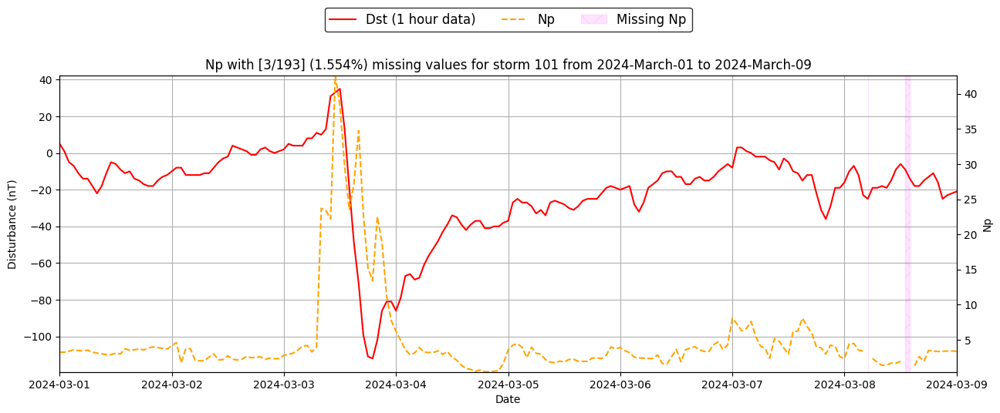

There are ACE missing values in test storm 102 from 2024 March 22 to 2024 March 30
Np missing 6 values (3.109%)


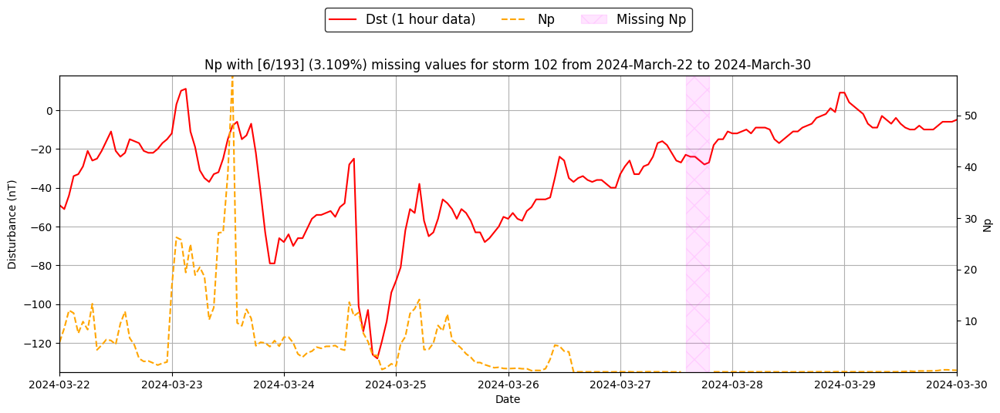

There are ACE missing values in test storm 103 from 2024 April 17 to 2024 April 25
Np missing 1 values (0.518%)


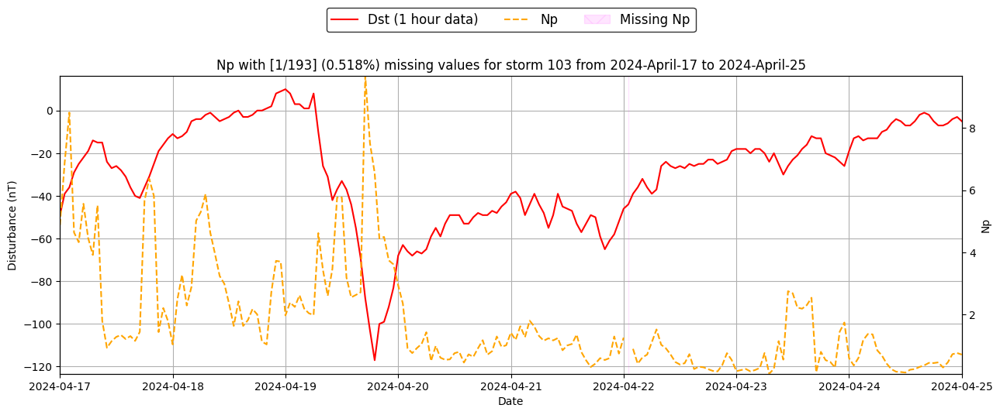

Test storm 104 from 2024 May 09 to 2024 May 14 has no missing values
There are ACE missing values in test storm 105 from 2024 June 26 to 2024 July 04
T missing 2 values (1.036%)


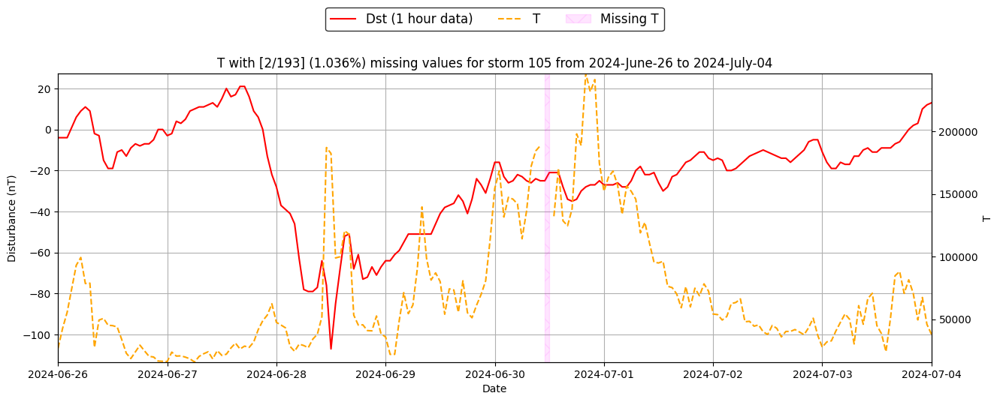

Test storm 106 from 2024 August 02 to 2024 August 19 has no missing values
There are ACE missing values in test storm 107 from 2024 September 10 to 2024 September 23
T missing 7 values (2.236%)


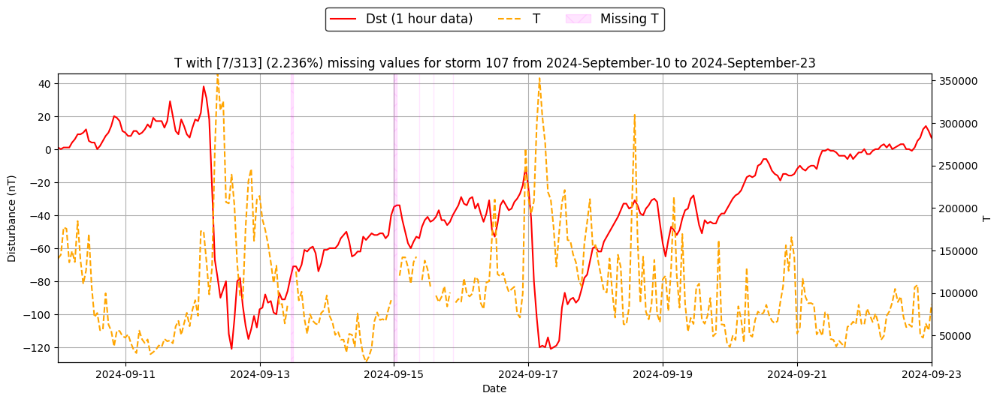

There are ACE missing values in test storm 108 from 2024 October 09 to 2024 October 14
Vp missing 4 values (3.306%)


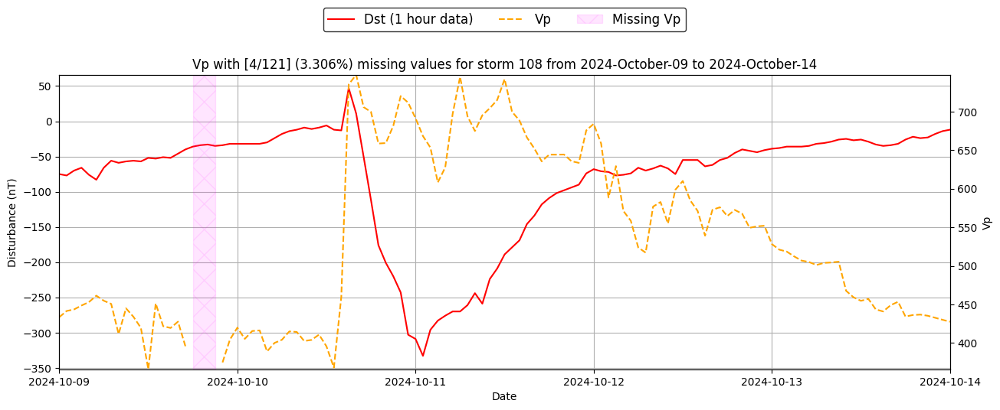

Test storm 109 from 2024 November 07 to 2024 November 15 has no missing values
Complete ACE test storms [9/20]


In [ ]:
valid_ace_test_storms = 0
for start_date, end_date, storm_index in storm_dates.TEST_STORMS_SYMBOLIC_REGRESSION:
    sd = pd.to_datetime(start_date)
    ed = pd.to_datetime(end_date)
    storm = ace_data[sd:ed].copy()
    if storm[ace_columns].isna().sum().sum() == 0:
        print(f'Test storm {storm_index} from {sd.strftime("%Y %B %d")} to {ed.strftime("%Y %B %d")} has no missing values')
        valid_ace_test_storms += 1
        if not PLOT_COMPLETE_STORMS:
            continue
            
        plot_storm(dst_kyoto, storm, None, sd, ed, storm_index)
        
    else:
        print(f'There are ACE missing values in test storm {storm_index} from {sd.strftime("%Y %B %d")} to {ed.strftime("%Y %B %d")}')
        if not PLOT_INCOMPLETE_STORMS:
            continue
            
        col = storm[ace_columns].isna().sum().sort_values(ascending=False).index[0]
        print(f'{col} missing {storm[col].isna().sum()} values ({storm[col].isna().sum() / len(storm[col]) * 100:.3f}%)')
        plot_storm(dst_kyoto, storm, col, sd, ed, storm_index)
        
print(f'Complete ACE test storms [{valid_ace_test_storms}/{len(storm_dates.TEST_STORMS_SYMBOLIC_REGRESSION)}]')